# Results of Detector Experiments on AnthroSet

In this version of the experiment analysis Notebook, the results from jina are discarded, as I failed to run the fixed contextual extraction in a reasonable amount of time (5 hours for a single MLM-experiment with short context, compared with the earlier ~20 minute run).

This Notebook describes the process of analyzing the results from the 1080 experiments on AnthroSet data.

To run the Notebook, upload the following files:
- `anthroset-lonke_scores.csv` (AnthroScores on AnthroSet, gold labels)
- `tuning_results_v3.csv` (results of 1440 experiments on AnthroSet, including the faulty implementation of contextual embeddings and results from jina)
- `results_contextual_new.jsonl` (results from the fixed contextual embeddings)
- `results_bge_new.jsonl` (results from the BPE adjusted static embeddings for BGE model)
- `runtimes (1).csv` (how long it took to run the experiments)
- `runtimes_contextual_new.jsonl` (how long it took to run the fixed contextual embedding implementation)

In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

In [ ]:
anthroscores_filename = "anthroset-lonke_scores.csv"

results_filename = "tuning_results_v3.csv"
new_results_filename = "results_contextual_new.csv"

runtime_filename = "runtimes (1).csv"
new_runtime_filename = "runtimes_contextual_new.jsonl"

Map the numeric linguistic categories to string representations and define which scoring method to use for which category.

In [ ]:
id2cat = {
    '1': 'verb_subjects',
    '2': 'verb_objects',
    '3': 'adjectives',
    '4': 'role_function_NPs',
    '5': 'genitive_NPs',
    '6': 'comparisons',
    }

cat2id = {value: key for key, value in id2cat.items()}

f1_cats = {'verb_subjects', 'verb_objects', 'adjectives'}
accuracy_cats = {'role_function_NPs', 'genitive_NPs'}

In [ ]:
# This function scores each linguistic category as intended
def score_group(g):
    cat = g.ling_category.iloc[0]
    if cat in accuracy_cats:
        return accuracy_score(g.expectations, g.pred)
    else:
        return f1_score(g.expectations, g.pred, average="macro")

## Experiment 0.1: random baseline with three labels

In [ ]:
y = pd.read_csv(anthroscores_filename, usecols=["expectations"]).to_numpy().reshape(-1)
print("Shape of expectations array:", y.shape)

Shape of expectations array: (600,)


In [ ]:
num_rounds = 10000

results = np.empty((num_rounds, 600))

for i in range(num_rounds):
  rng = np.random.default_rng()
  results[i] = rng.integers(0, high=2, size=600, endpoint=True)

accuracies = np.empty(num_rounds)

for i in range(num_rounds):
  accuracies[i] = accuracy_score(y, results[i])

acc = pd.Series(accuracies)
acc.describe()

,0
count,10000.000000
mean,0.333338
std,0.019381
min,0.263333
25%,0.320000
50%,0.333333
75%,0.346667
max,0.405000


<Axes: ylabel='Density'>

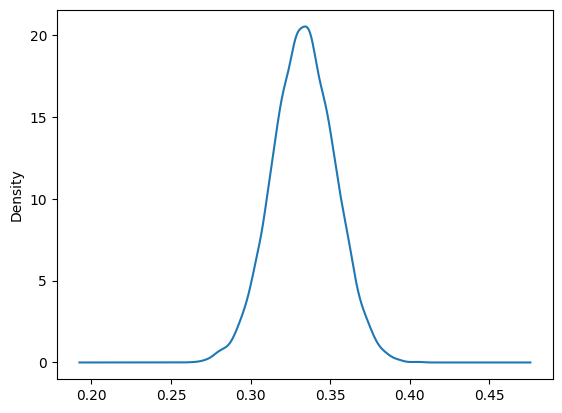

In [ ]:
acc.plot.density()

## Experiment 0.2: Random baseline with 2 labels

In [ ]:
as_expectations = pd.read_csv(anthroscores_filename, usecols=["expectations"])
as_expectations = as_expectations[as_expectations != 2].dropna().astype(int)
y = as_expectations.to_numpy().reshape(-1)

print("Shape of expectations array:", y.shape)

Shape of expectations array: (469,)


In [ ]:
num_rounds = 10000
num_items = y.shape[0]

results = np.empty((num_rounds, num_items))

for i in range(num_rounds):
  rng = np.random.default_rng()
  results[i] = rng.integers(0, high=1, size=num_items, endpoint=True)

accuracies = np.empty(num_rounds)

for i in range(num_rounds):
  accuracies[i] = accuracy_score(y, results[i])

acc = pd.Series(accuracies)
acc.describe()

,0
count,10000.000000
mean,0.499950
std,0.023136
min,0.413646
25%,0.484009
50%,0.498934
75%,0.515991
max,0.588486


<Axes: ylabel='Density'>

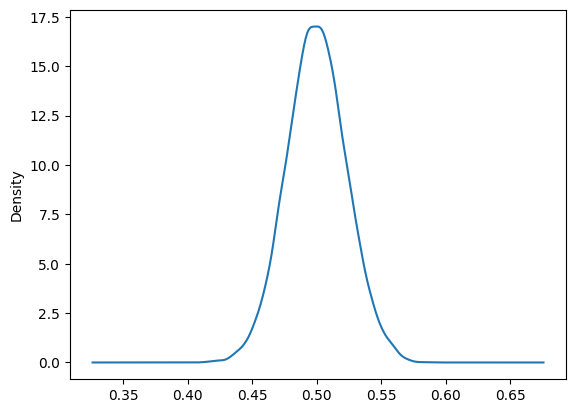

In [ ]:
acc.plot.density()

## Inspect AnthroScores (method by Cheng et al.)

This section investigates if the results that Lonke obtained with AnthroScore can be reproduced.

### Results when AnthroScores are mapped to two labels

In [ ]:
anthroscores = pd.read_csv(anthroscores_filename)
anthroscores["pred"] = (anthroscores["anthroscore"] > 0).astype(int)
anthroscores["correct"] = anthroscores["expectations"] == anthroscores["pred"]
anthroscores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 600 non-null    object 
 1   previous_sentence  597 non-null    object 
 2   current_sentence   600 non-null    object 
 3   masked_sentence    600 non-null    object 
 4   next_sentence      537 non-null    object 
 5   AI_phrase          600 non-null    object 
 6   masked_phrase      600 non-null    object 
 7   AI_entity          600 non-null    object 
 8   component          600 non-null    object 
 9   expectations       600 non-null    int64  
 10  anthroscore        600 non-null    float64
 11  pred               600 non-null    int64  
 12  correct            600 non-null    bool   
dtypes: bool(1), float64(1), int64(2), object(9)
memory usage: 57.0+ KB


In [ ]:
anthroscores.id.nunique()

599

In [ ]:
anthroscores[anthroscores.duplicated(subset="id", keep=False)]

,id,previous_sentence,current_sentence,masked_sentence,next_sentence,AI_phrase,masked_phrase,AI_entity,component,expectations,anthroscore,pred,correct,ling_category
327,2_arx_1910.06294_1190213_4,"However, such models impose a heavy memory and...",In this work-in-progress we combined the effec...,In this work-in-progress we combined the effec...,Preliminary evaluations show that the compact ...,pre-trained masked language models,pre-trained masked language models,model,provide,0,-3.764543,0,True,verb_objects
380,2_arx_1910.06294_1190213_4,"However, such models impose a heavy memory and...",In this work-in-progress we combined the effec...,In this work-in-progress we combined the effec...,Preliminary evaluations show that the compact ...,a fast and compact model,model,model,train,0,-1.611769,0,True,verb_objects


In [ ]:
# Add suffixes to the duplicated ids so that the merge process doesn't fail later
anthroscores.loc[327, "id"] = "2_arx_1910.06294_1190213_4_a"
anthroscores.loc[380, "id"] = "2_arx_1910.06294_1190213_4_b"

In [ ]:
anthroscores.id.nunique()

600

In [ ]:
# This matches with the table reported in the thesis (table 4.2)

anthroscores["ling_category"] = (anthroscores["id"].str[0]).replace(id2cat)
anthroscores.ling_category.value_counts()

,count
ling_category,
verb_objects,150
verb_subjects,150
adjectives,120
role_function_NPs,70
genitive_NPs,60
comparisons,50


In [ ]:
# This also matches with the numbers reported in the thesis (table 4.2)

anthroscores.expectations.value_counts()

,count
expectations,
1,296
0,173
2,131


In [ ]:
# This also matches (table 4.2)

anthroscores_no_inconclusive = anthroscores[anthroscores["expectations"] != 2].copy()
anthroscores_no_inconclusive.groupby(["ling_category", "expectations"]).size().unstack("expectations").fillna(0).astype(int)

expectations,0,1
ling_category,,
adjectives,47,52
genitive_NPs,0,60
role_function_NPs,0,70
verb_objects,65,58
verb_subjects,61,56


In [ ]:
# This also matches (table 4.2)

anthroset_inconclusive = anthroscores[anthroscores["expectations"] == 2].copy()
anthroset_inconclusive.ling_category.value_counts()

,count
ling_category,
comparisons,50
verb_subjects,33
verb_objects,27
adjectives,21


In [ ]:
anthroscores_no_inconclusive.groupby(["ling_category", "pred"])["correct"].count()

ling_category      pred
adjectives         0       72
                   1       27
genitive_NPs       0       43
                   1       17
role_function_NPs  0       57
                   1       13
verb_objects       0       86
                   1       37
verb_subjects      0       92
                   1       25
Name: correct, dtype: int64

Score the performance of AnthroScore in each linguistic category, exclude sentences with inconclusive annotations.

In [ ]:
anthroscores_scored = (
    anthroscores_no_inconclusive.groupby("ling_category", observed=True)
    .apply(score_group)
    .rename("performance")
    .reset_index("ling_category")
)
anthroscores_scored

/tmp/ipykernel_532/1227525460.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(score_group)


,ling_category,performance
0,adjectives,0.441868
1,genitive_NPs,0.283333
2,role_function_NPs,0.185714
3,verb_objects,0.545556
4,verb_subjects,0.518519


Show the performance averaged over all lingistic categories that include conclusive labels.

In [ ]:
anthroscores_scored.performance.mean()

np.float64(0.3949979933596855)

### Results when AntroScores are mapped to three labels

Lonke maps AnthroScores in the following way:
- negative: x < -1
- positive: x > 1
- inconclusive: -1 <= x <= 1

In [ ]:
def assign_lonke_pred(score):
  if score > 1:
    return 1
  elif score < -1:
    return 0
  else:
    return 2

anthroscores_no_inconclusive["pred_lonke"] = anthroscores_no_inconclusive["anthroscore"].apply(assign_lonke_pred)
anthroscores_no_inconclusive["correct_lonke"] = anthroscores_no_inconclusive["expectations"] == anthroscores_no_inconclusive["pred_lonke"]

In [ ]:
def score_group_lonke(g):
    cat = g.ling_category.iloc[0]
    if cat in accuracy_cats:
        return accuracy_score(g.expectations, g.pred_lonke)
    else:
        return f1_score(g.expectations, g.pred_lonke, average="macro")

The following scores are in line with the ones reported in the paper (Tables 5.3 and 5.4, minimal entity masking strategy).

In [ ]:
anthroscores_scored_lonke = (
    anthroscores_no_inconclusive.groupby("ling_category", observed=True)
    .apply(score_group_lonke)
    .rename("performance")
    .reset_index("ling_category")
)
anthroscores_scored_lonke

/tmp/ipykernel_2174/2085900889.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(score_group_lonke)


,ling_category,performance
0,adjectives,0.255565
1,genitive_NPs,0.116667
2,role_function_NPs,0.085714
3,verb_objects,0.292646
4,verb_subjects,0.305385


In [ ]:
anthroscores_scored_lonke.performance.mean()

np.float64(0.21119536950661325)

In [ ]:
anthroscores.groupby("ling_category")["pred_lonke"].value_counts()

ling_category      pred_lonke
adjectives         0             71
                   2             33
                   1             16
comparisons        0             42
                   2              5
                   1              3
genitive_NPs       0             33
                   2             20
                   1              7
role_function_NPs  0             46
                   2             18
                   1              6
verb_objects       0             69
                   2             50
                   1             31
verb_subjects      0             96
                   2             42
                   1             12
Name: count, dtype: int64

In [ ]:
anthroscores.groupby("ling_category")[["pred_lonke", "correct"]].value_counts()

ling_category      pred_lonke  correct
adjectives         0           False      44
                               True       27
                   2           False      22
                               True       11
                   1           False       8
                               True        8
comparisons        0           False      42
                   2           False       5
                   1           False       3
genitive_NPs       0           False      33
                   2           False      10
                               True       10
                   1           True        7
role_function_NPs  0           False      46
                   2           False      11
                               True        7
                   1           True        6
verb_objects       0           False      36
                               True       33
                   2           False      27
                               True       23
                   1           False      17
                               True       14
verb_subjects      0           False      54
                               True       42
                   2           False      28
                               True       14
                   1           True       10
                               False       2
Name: count, dtype: int64

In [ ]:
anthroscores.groupby(["ling_category", "expectations"]).size()

ling_category      expectations
adjectives         0               47
                   1               52
                   2               21
comparisons        2               50
genitive_NPs       1               60
role_function_NPs  1               70
verb_objects       0               65
                   1               58
                   2               27
verb_subjects      0               61
                   1               56
                   2               33
dtype: int64

In [ ]:
anthroscores[anthroscores["expectations"] == 2].groupby("ling_category")["pred_lonke"].value_counts()

ling_category  pred_lonke
adjectives     0             15
               2              4
               1              2
comparisons    0             42
               2              5
               1              3
verb_objects   0             10
               2              9
               1              8
verb_subjects  0             21
               2             11
               1              1
Name: count, dtype: int64

In [ ]:
anthroscores.pred_lonke.value_counts()

,count
pred_lonke,
0,357
2,168
1,75


In [ ]:
len(anthroscores[(anthroscores["pred_lonke"] == 2) & (anthroscores["anthroscore"] > 0)])

69

In [ ]:
len(anthroscores[(anthroscores["pred_lonke"] == 2) & (anthroscores["anthroscore"] < 0)])

99

### Inspect the differences between the two scoring approaches

In [ ]:
diff = anthroscores[anthroscores["pred"] != anthroscores["pred_lonke"]]

In [ ]:
len(diff)

168

In sentences where the predictions differ depending on how AnthroScore is interpreted, how many more of the predictions are correct?

When scores between -1 and 1 are interpreted as inconclusive, in 29 cases the inconclusive label is correct. On the contrary, if negative scores are interpreted as negative label and positive scores as positive label, in 65 cases the binary prediction is better. In 74 cases, neither of the interpretations is correct.

In [ ]:
diff.groupby("correct_lonke")["expectations"].value_counts()

correct_lonke  expectations
False          1               84
               0               55
True           2               29
Name: count, dtype: int64

In [ ]:
diff[(diff["correct"] == False) & (diff["correct_lonke"] == False)]["expectations"].value_counts()

,count
expectations,
1,50
0,24


In [ ]:
len(diff[(diff["correct"] == False) & (diff["correct_lonke"] == False)])

74

In [ ]:
len(diff[(diff["correct"] == True) & (diff["correct_lonke"] == False)])

65

In [ ]:
len(diff[(diff["correct"] == False) & (diff["correct_lonke"] == True)])

29

## Initialize color palette

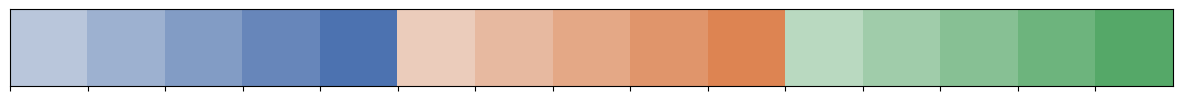

In [ ]:
base_colors = ["#4C72B0", "#DD8452", "#55A868"]  # blue, orange, green
n_shades = 5

palette = []
for color in base_colors:
    shades = sns.light_palette(color, n_colors=n_shades + 2)[2:]  # skip near-white
    palette.extend(shades)

sns.palplot(palette)

## Inspect scores from 1080 experiments

In [ ]:
from collections import defaultdict

with open(new_results_filename.replace("csv", "jsonl")) as file:
  jsonl_results = [json.loads(line) for line in file]

def parse_key(key: str):
  scoring_method, mlm, emb, topk, cont_emb, long_cont = key.split("_")
  return {"scoring_method": scoring_method,
          "mlm": mlm,
          "emb": emb,
          "topk": int(topk[1:]),
          "cont_emb": cont_emb,
          "long_cont": int(long_cont),
          "experiment": key}

def jsonl_to_csv(jsonl_results, filename):
  res_dict = defaultdict(list)
  for line in jsonl_results:
    i = line.pop("i")
    for key, value in line.items():
      new_dict = parse_key(key)
      new_dict["score"] = value
      new_dict["index"] = i
      res_dict[i].append(new_dict)

  print(len(res_dict))

  pd.concat(
    {k: pd.DataFrame(v) for k, v in res_dict.items()}
  ).droplevel(1).to_csv(filename, index=False)


jsonl_to_csv(jsonl_results, "results_contextual_new.csv")

600


In [ ]:
with open("results_bge_new.jsonl") as file:
  bge_results = [json.loads(line) for line in file]

jsonl_to_csv(bge_results, "results_bge_new.csv")

600


In [ ]:
new_results = pd.read_csv(new_results_filename)
new_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 216000 entries, 0 to 215999
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   scoring_method  216000 non-null  object 
 1   mlm             216000 non-null  object 
 2   emb             216000 non-null  object 
 3   topk            216000 non-null  int64  
 4   cont_emb        216000 non-null  object 
 5   long_cont       216000 non-null  int64  
 6   experiment      216000 non-null  object 
 7   score           216000 non-null  float64
 8   index           216000 non-null  int64  
dtypes: float64(1), int64(3), object(5)
memory usage: 14.8+ MB


In [ ]:
new_results

,scoring_method,mlm,emb,topk,cont_emb,long_cont,experiment,score,index
0,soft,distilbert-base-uncased,all-MiniLM-L6-v2,1,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.025088,0
1,hard,distilbert-base-uncased,all-MiniLM-L6-v2,1,contextual,0,hard_distilbert-base-uncased_all-MiniLM-L6-v2_...,24.672467,0
2,soft,distilbert-base-uncased,all-MiniLM-L6-v2,5,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.036282,0
3,hard,distilbert-base-uncased,all-MiniLM-L6-v2,5,contextual,0,hard_distilbert-base-uncased_all-MiniLM-L6-v2_...,1.820348,0
4,soft,distilbert-base-uncased,all-MiniLM-L6-v2,10,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.029241,0
...,...,...,...,...,...,...,...,...,...
215995,hard,ModernBERT-base,modernbert-embed-base,50,contextual,1,hard_ModernBERT-base_modernbert-embed-base_k50...,-4.196358,599
215996,soft,ModernBERT-base,modernbert-embed-base,100,contextual,1,soft_ModernBERT-base_modernbert-embed-base_k10...,-0.051498,599
215997,hard,ModernBERT-base,modernbert-embed-base,100,contextual,1,hard_ModernBERT-base_modernbert-embed-base_k10...,-4.031654,599
215998,soft,ModernBERT-base,modernbert-embed-base,150,contextual,1,soft_ModernBERT-base_modernbert-embed-base_k15...,-0.051377,599


In [ ]:
bge_results = pd.read_csv("results_bge_new.csv")
bge_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72000 entries, 0 to 71999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   scoring_method  72000 non-null  object 
 1   mlm             72000 non-null  object 
 2   emb             72000 non-null  object 
 3   topk            72000 non-null  int64  
 4   cont_emb        72000 non-null  object 
 5   long_cont       72000 non-null  int64  
 6   experiment      72000 non-null  object 
 7   score           72000 non-null  float64
 8   index           72000 non-null  int64  
dtypes: float64(1), int64(3), object(5)
memory usage: 4.9+ MB


In [ ]:
bge_results

,scoring_method,mlm,emb,topk,cont_emb,long_cont,experiment,score,index
0,soft,distilbert-base-uncased,bge-base-en-v1.5,1,static,0,soft_distilbert-base-uncased_bge-base-en-v1.5_...,0.009702,0
1,hard,distilbert-base-uncased,bge-base-en-v1.5,1,static,0,hard_distilbert-base-uncased_bge-base-en-v1.5_...,24.672467,0
2,soft,distilbert-base-uncased,bge-base-en-v1.5,5,static,0,soft_distilbert-base-uncased_bge-base-en-v1.5_...,0.006828,0
3,hard,distilbert-base-uncased,bge-base-en-v1.5,5,static,0,hard_distilbert-base-uncased_bge-base-en-v1.5_...,1.003225,0
4,soft,distilbert-base-uncased,bge-base-en-v1.5,10,static,0,soft_distilbert-base-uncased_bge-base-en-v1.5_...,-0.002264,0
...,...,...,...,...,...,...,...,...,...
71995,hard,ModernBERT-base,bge-base-en-v1.5,50,static,1,hard_ModernBERT-base_bge-base-en-v1.5_k50_stat...,2.568398,599
71996,soft,ModernBERT-base,bge-base-en-v1.5,100,static,1,soft_ModernBERT-base_bge-base-en-v1.5_k100_sta...,0.001463,599
71997,hard,ModernBERT-base,bge-base-en-v1.5,100,static,1,hard_ModernBERT-base_bge-base-en-v1.5_k100_sta...,2.505163,599
71998,soft,ModernBERT-base,bge-base-en-v1.5,150,static,1,soft_ModernBERT-base_bge-base-en-v1.5_k150_sta...,0.001397,599


In [ ]:
results = pd.read_csv(results_filename)
# Add suffixes to the duplicated ids so that the merge process doesn't fail later
results.loc[327, "id"] = "2_arx_1910.06294_1190213_4_a"
results.loc[380, "id"] = "2_arx_1910.06294_1190213_4_b"
results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Columns: 1454 entries, id to hard_bert-base-uncased_jina-embeddings-v5-text-nano_k150_2_1
dtypes: float64(1440), int64(1), object(13)
memory usage: 6.7+ MB


In [ ]:
# To ensure that the prediction is kept pointing to the correct row, add an actual id instead of just the index
# However, one id is duplicated, so make sure you have run the part when these ids are deduplicated
bge_results = bge_results.merge(results["id"], left_on="index", right_index=True)
new_results = new_results.merge(results["id"], left_on="index", right_index=True)

In [ ]:
bge_results.id.nunique()

600

In [ ]:
jina_cols = [col for col in results.columns if "jina-embeddings-v5-text-nano" in col]
len(jina_cols)

360

In [ ]:
results = results.drop(columns=jina_cols)

In [ ]:
results

,id,previous_sentence,current_sentence,masked_sentence,next_sentence,AI_phrase,masked_phrase,AI_entity,component,expectations,...,soft_bert-base-uncased_modernbert-embed-base_k100_0_1,hard_bert-base-uncased_modernbert-embed-base_k100_0_1,soft_bert-base-uncased_modernbert-embed-base_k100_2_1,hard_bert-base-uncased_modernbert-embed-base_k100_2_1,soft_bert-base-uncased_modernbert-embed-base_k150_1_1,hard_bert-base-uncased_modernbert-embed-base_k150_1_1,soft_bert-base-uncased_modernbert-embed-base_k150_0_1,hard_bert-base-uncased_modernbert-embed-base_k150_0_1,soft_bert-base-uncased_modernbert-embed-base_k150_2_1,hard_bert-base-uncased_modernbert-embed-base_k150_2_1
0,3_acl_7_46407_0,"In conclusion, our findings can achieve less s...",Language models (LMs) are vulnerable to exploi...,<mask> are vulnerable to exploitation for adve...,Training LMs for safety alignment is extensive...,Language models (LMs),Language models (LMs),model,vulnerable,2,...,0.050025,2.723015,0.029022,2.027672,-0.068098,-20.665498,0.049350,2.612769,0.028444,1.956181
1,3_arx_2005.06620_1286415_1,Artificial intelligence (AI) enabled products ...,While governments and businesses are eager to ...,While governments and businesses are eager to ...,This article introduces one of the first inter...,these autonomous and intelligent systems,systems,system,"autonomous,intelligent",2,...,-0.092897,-6.760102,-0.082717,-6.961856,-0.035780,-20.722494,-0.092875,-6.667724,-0.082701,-6.886962
2,3_arx_2408.08878_2129059_6,We discovered prompting to be a useful but und...,Integrating LLMs into KE tasks needs to be min...,Integrating LLMs into KE tasks needs to be min...,"Given the limited ethical training, most knowl...",responsible AI,AI,AI,responsible,2,...,-0.014438,-0.658086,-0.030226,-1.329559,-0.035734,-20.550705,-0.013667,-0.628783,-0.029438,-1.298376
3,3_arx_2402.05827_2003466_5,We focus on three key research questions.,RQ1: Can edited LLMs behave consistently resem...,RQ1: Can edited LLMs behave consistently resem...,RQ2: To what extent does the rephrasing of pro...,communicative AI,AI,AI,communicative,2,...,-0.012239,-0.938095,-0.021353,-1.142123,-0.033171,-4.556619,-0.012859,-0.926233,-0.021918,-1.207854
4,3_arx_1904.13086_1118126_10,Simply putting a human into the loop does not ...,The results demonstrate the descriptive value ...,The results demonstrate the descriptive value ...,The ResQu model is a new quantitative method t...,the intelligent system,system,system,intelligent,2,...,-0.090582,-5.924179,-0.080074,-6.033363,0.034639,20.722284,-0.090549,-5.860261,-0.080050,-5.981467
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,1_arx_2010.09890_1366220_2,"In WAH, an AI agent needs to help a human-like...","To succeed, the AI agent needs to i) understan...","To succeed, the <mask> needs to i) understand ...","For this challenge, we build VirtualHome-Socia...",the AI agent,AI agent,agent,"understand,coordinate",1,...,0.102308,4.308370,0.053826,3.687827,0.059343,20.715222,0.102135,4.239960,0.053734,3.645364
596,1_acl_1477_40886_4,"Then, we conduct experiments on four popular t...",The experimental results showcase that ChatGPT...,The experimental results showcase that <mask> ...,We also found that ChatGPT hardly understands ...,ChatGPT,ChatGPT,ChatGPT,"demonstrate proficiency,struggle",1,...,-0.040559,-0.906483,-0.040554,-1.562889,-0.031876,-20.268314,-0.037814,-0.846758,-0.038433,-1.455433
597,1_arx_2303.09387_1809184_9,Our overall assessment is that while some prog...,In the absence of a consensus definition and r...,In the absence of a consensus definition and r...,We argue that such manipulation poses a signif...,AI systems,AI systems,system,learn to manipulate,1,...,-0.006566,0.859416,-0.022682,-1.928316,-0.035345,-20.703542,-0.006578,0.850339,-0.022666,-1.920960
598,1_arx_2212.01681_1757858_4,I argue that LMs are models of intentional com...,When performing next word prediction given a t...,When performing next word predi

The tested combinations were
- 5 masked language models
- 3 embedding models
- 2 scoring methods
- 6 top-k values
- 3 ways of producing embeddings
- 2 lengths of input (short vs long)

AnthroSet contains 600 masked sentences

In [ ]:
num_params = 5*3*2*6*3*2
num_annotations = len(results)
num_experiments = num_params * num_annotations

In [ ]:
metadata_cols = results.columns[:14]
metadata_cols

Index(['id', 'previous_sentence', 'current_sentence', 'masked_sentence',
       'next_sentence', 'AI_phrase', 'masked_phrase', 'AI_entity', 'component',
       'expectations', 'masked_sentence_bert', 'long_context',
       'long_context_bert', 'ling_category'],
      dtype='object')

In [ ]:
experiment_cols = results.columns[14:].tolist()
labels_only = results[["id", "expectations", "ling_category"] + experiment_cols]
labels_long = labels_only.melt(id_vars=["id", "expectations", "ling_category"], var_name="experiment", value_name="score")
assert len(labels_long) == num_experiments
labels_long

,id,expectations,ling_category,experiment,score
0,3_acl_7_46407_0,2,adjectives,soft_ModernBERT-base_all-MiniLM-L6-v2_k1_1_0,0.025088
1,3_arx_2005.06620_1286415_1,2,adjectives,soft_ModernBERT-base_all-MiniLM-L6-v2_k1_1_0,-0.156247
2,3_arx_2408.08878_2129059_6,2,adjectives,soft_ModernBERT-base_all-MiniLM-L6-v2_k1_1_0,-0.150310
3,3_arx_2402.05827_2003466_5,2,adjectives,soft_ModernBERT-base_all-MiniLM-L6-v2_k1_1_0,0.137930
4,3_arx_1904.13086_1118126_10,2,adjectives,soft_ModernBERT-base_all-MiniLM-L6-v2_k1_1_0,0.163491
...,...,...,...,...,...
647995,1_arx_2010.09890_1366220_2,1,verb_subjects,hard_bert-base-uncased_modernbert-embed-base_k...,3.645364
647996,1_acl_1477_40886_4,1,verb_subjects,hard_bert-base-uncased_modernbert-embed-base_k...,-1.455433
647997,1_arx_2303.09387_1809184_9,1,verb_subjects,hard_bert-base-uncased_modernbert-embed-base_k...,-1.920960
647998,1_arx_2212.01681_1757858_4,1,verb_subjects,hard_bert-base-uncased_modernbert-embed-base_k...,5.424074


In [ ]:
# Extract the experiment parameters from the initial column names
cols = [
    "scoring_method",
    "mlm",
    "emb",
    "topk",
    "cont_emb",
    "long_cont"
]

labels_long[cols] = labels_long["experiment"].str.split("_", expand=True)
labels_long["topk"] = labels_long["topk"].str[1:]

In [ ]:
dtypes = {"mlm": "category", "emb": "category", "scoring_method": "category", "topk": int, "long_cont": int, "cont_emb": int}
labels_long = labels_long.astype(dtypes)
labels_long

,id,expectations,ling_category,experiment,score,scoring_method,mlm,emb,topk,cont_emb,long_cont
0,3_acl_7_46407_0,2,adjectives,soft_ModernBERT-base_all-MiniLM-L6-v2_k1_1_0,0.025088,soft,ModernBERT-base,all-MiniLM-L6-v2,1,1,0
1,3_arx_2005.06620_1286415_1,2,adjectives,soft_ModernBERT-base_all-MiniLM-L6-v2_k1_1_0,-0.156247,soft,ModernBERT-base,all-MiniLM-L6-v2,1,1,0
2,3_arx_2408.08878_2129059_6,2,adjectives,soft_ModernBERT-base_all-MiniLM-L6-v2_k1_1_0,-0.150310,soft,ModernBERT-base,all-MiniLM-L6-v2,1,1,0
3,3_arx_2402.05827_2003466_5,2,adjectives,soft_ModernBERT-base_all-MiniLM-L6-v2_k1_1_0,0.137930,soft,ModernBERT-base,all-MiniLM-L6-v2,1,1,0
4,3_arx_1904.13086_1118126_10,2,adjectives,soft_ModernBERT-base_all-MiniLM-L6-v2_k1_1_0,0.163491,soft,ModernBERT-base,all-MiniLM-L6-v2,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
647995,1_arx_2010.09890_1366220_2,1,verb_subjects,hard_bert-base-uncased_modernbert-embed-base_k...,3.645364,hard,bert-base-uncased,modernbert-embed-base,150,2,1
647996,1_acl_1477_40886_4,1,verb_subjects,hard_bert-base-uncased_modernbert-embed-base_k...,-1.455433,hard,bert-base-uncased,modernbert-embed-base,150,2,1
647997,1_arx_2303.09387_1809184_9,1,verb_subjects,hard_bert-base-uncased_modernbert-embed-base_k...,-1.920960,hard,bert-base-uncased,modernbert-embed-base,150,2,1
647998,1_arx_2212.01681_1757858_4,1,verb_subjects,hard_bert-base-uncased_modernbert-embed-base_k...,5.424074,hard,bert-base-uncased,modernbert-embed-base,150,2,1


In [ ]:
# Remove the results that include scores from the old faulty version of contextual embeddings
labels_long = labels_long[labels_long["cont_emb"] != 1]

In [ ]:
# Map the predictions of the new implementation to gold labels
new_results_with_gold = new_results.merge(anthroscores[["id", "expectations", "ling_category"]], how="left", on="id")
new_results_with_gold = new_results_with_gold.drop(columns="index")
new_results_with_gold

,scoring_method,mlm,emb,topk,cont_emb,long_cont,experiment,score,id,expectations,ling_category
0,soft,distilbert-base-uncased,all-MiniLM-L6-v2,1,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.025088,3_acl_7_46407_0,2,adjectives
1,hard,distilbert-base-uncased,all-MiniLM-L6-v2,1,contextual,0,hard_distilbert-base-uncased_all-MiniLM-L6-v2_...,24.672467,3_acl_7_46407_0,2,adjectives
2,soft,distilbert-base-uncased,all-MiniLM-L6-v2,5,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.036282,3_acl_7_46407_0,2,adjectives
3,hard,distilbert-base-uncased,all-MiniLM-L6-v2,5,contextual,0,hard_distilbert-base-uncased_all-MiniLM-L6-v2_...,1.820348,3_acl_7_46407_0,2,adjectives
4,soft,distilbert-base-uncased,all-MiniLM-L6-v2,10,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.029241,3_acl_7_46407_0,2,adjectives
...,...,...,...,...,...,...,...,...,...,...,...
215995,hard,ModernBERT-base,modernbert-embed-base,50,contextual,1,hard_ModernBERT-base_modernbert-embed-base_k50...,-4.196358,1_arx_1808.10627_1019773_2,1,verb_subjects
215996,soft,ModernBERT-base,modernbert-embed-base,100,contextual,1,soft_ModernBERT-base_modernbert-embed-base_k10...,-0.051498,1_arx_1808.10627_1019773_2,1,verb_subjects
215997,hard,ModernBERT-base,modernbert-embed-base,100,contextual,1,hard_ModernBERT-base_modernbert-embed-base_k10...,-4.031654,1_arx_1808.10627_1019773_2,1,verb_subjects
215998,soft,ModernBERT-base,modernbert-embed-base,150,contextual,1,soft_ModernBERT-base_modernbert-embed-base_k15...,-0.051377,1_arx_1808.10627_1019773_2,1,verb_subjects


In [ ]:
# Map the predictions of bge static with prefix to gold labels
new_bge_with_gold = bge_results.merge(anthroscores[["id", "expectations", "ling_category"]], how="left", on="id")
new_bge_with_gold = new_bge_with_gold.drop(columns="index")
new_bge_with_gold

,scoring_method,mlm,emb,topk,cont_emb,long_cont,experiment,score,id,expectations,ling_category
0,soft,distilbert-base-uncased,bge-base-en-v1.5,1,static,0,soft_distilbert-base-uncased_bge-base-en-v1.5_...,0.009702,3_acl_7_46407_0,2,adjectives
1,hard,distilbert-base-uncased,bge-base-en-v1.5,1,static,0,hard_distilbert-base-uncased_bge-base-en-v1.5_...,24.672467,3_acl_7_46407_0,2,adjectives
2,soft,distilbert-base-uncased,bge-base-en-v1.5,5,static,0,soft_distilbert-base-uncased_bge-base-en-v1.5_...,0.006828,3_acl_7_46407_0,2,adjectives
3,hard,distilbert-base-uncased,bge-base-en-v1.5,5,static,0,hard_distilbert-base-uncased_bge-base-en-v1.5_...,1.003225,3_acl_7_46407_0,2,adjectives
4,soft,distilbert-base-uncased,bge-base-en-v1.5,10,static,0,soft_distilbert-base-uncased_bge-base-en-v1.5_...,-0.002264,3_acl_7_46407_0,2,adjectives
...,...,...,...,...,...,...,...,...,...,...,...
71995,hard,ModernBERT-base,bge-base-en-v1.5,50,static,1,hard_ModernBERT-base_bge-base-en-v1.5_k50_stat...,2.568398,1_arx_1808.10627_1019773_2,1,verb_subjects
71996,soft,ModernBERT-base,bge-base-en-v1.5,100,static,1,soft_ModernBERT-base_bge-base-en-v1.5_k100_sta...,0.001463,1_arx_1808.10627_1019773_2,1,verb_subjects
71997,hard,ModernBERT-base,bge-base-en-v1.5,100,static,1,hard_ModernBERT-base_bge-base-en-v1.5_k100_sta...,2.505163,1_arx_1808.10627_1019773_2,1,verb_subjects
71998,soft,ModernBERT-base,bge-base-en-v1.5,150,static,1,soft_ModernBERT-base_bge-base-en-v1.5_k150_sta...,0.001397,1_arx_1808.10627_1019773_2,1,verb_subjects


In [ ]:
# Remove the old bge static embeddings
labels_long = labels_long[~((labels_long["emb"] == "bge-base-en-v1.5") & (labels_long["cont_emb"] == 0))]

In [ ]:
# Concatenate the results from the earlier run with the fixed results
labels_long = pd.concat([new_results_with_gold, new_bge_with_gold, labels_long], ignore_index=True)

In [ ]:
labels_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 648000 entries, 0 to 647999
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   scoring_method  648000 non-null  object 
 1   mlm             648000 non-null  object 
 2   emb             648000 non-null  object 
 3   topk            648000 non-null  int64  
 4   cont_emb        648000 non-null  object 
 5   long_cont       648000 non-null  int64  
 6   experiment      648000 non-null  object 
 7   score           648000 non-null  float64
 8   id              648000 non-null  object 
 9   expectations    648000 non-null  int64  
 10  ling_category   648000 non-null  object 
dtypes: float64(1), int64(3), object(7)
memory usage: 54.4+ MB


In [ ]:
labels_long

,scoring_method,mlm,emb,topk,cont_emb,long_cont,experiment,score,id,expectations,ling_category
0,soft,distilbert-base-uncased,all-MiniLM-L6-v2,1,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.025088,3_acl_7_46407_0,2,adjectives
1,hard,distilbert-base-uncased,all-MiniLM-L6-v2,1,contextual,0,hard_distilbert-base-uncased_all-MiniLM-L6-v2_...,24.672467,3_acl_7_46407_0,2,adjectives
2,soft,distilbert-base-uncased,all-MiniLM-L6-v2,5,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.036282,3_acl_7_46407_0,2,adjectives
3,hard,distilbert-base-uncased,all-MiniLM-L6-v2,5,contextual,0,hard_distilbert-base-uncased_all-MiniLM-L6-v2_...,1.820348,3_acl_7_46407_0,2,adjectives
4,soft,distilbert-base-uncased,all-MiniLM-L6-v2,10,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.029241,3_acl_7_46407_0,2,adjectives
...,...,...,...,...,...,...,...,...,...,...,...
647995,hard,bert-base-uncased,modernbert-embed-base,150,2,1,hard_bert-base-uncased_modernbert-embed-base_k...,3.645364,1_arx_2010.09890_1366220_2,1,verb_subjects
647996,hard,bert-base-uncased,modernbert-embed-base,150,2,1,hard_bert-base-uncased_modernbert-embed-base_k...,-1.455433,1_acl_1477_40886_4,1,verb_subjects
647997,hard,bert-base-uncased,modernbert-embed-base,150,2,1,hard_bert-base-uncased_modernbert-embed-base_k...,-1.920960,1_arx_2303.09387_1809184_9,1,verb_subjects
647998,hard,bert-base-uncased,modernbert-embed-base,150,2,1,hard_bert-base-uncased_modernbert-embed-base_k...,5.424074,1_arx_2212.01681_1757858_4,1,verb_subjects


In [ ]:
labels_long.emb.unique()

array(['all-MiniLM-L6-v2', 'bge-base-en-v1.5', 'modernbert-embed-base'],
      dtype=object)

In [ ]:
labels_long.cont_emb.unique()

array(['contextual', 'static', 0, 2], dtype=object)

In [ ]:
labels_long["cont_emb"] = labels_long["cont_emb"].replace({0: "static", 2: "template"})
labels_long["cont_emb"] = labels_long["cont_emb"].astype("category")
labels_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 648000 entries, 0 to 647999
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   scoring_method  648000 non-null  object  
 1   mlm             648000 non-null  object  
 2   emb             648000 non-null  object  
 3   topk            648000 non-null  int64   
 4   cont_emb        648000 non-null  category
 5   long_cont       648000 non-null  int64   
 6   experiment      648000 non-null  object  
 7   score           648000 non-null  float64 
 8   id              648000 non-null  object  
 9   expectations    648000 non-null  int64   
 10  ling_category   648000 non-null  object  
dtypes: category(1), float64(1), int64(3), object(6)
memory usage: 50.1+ MB


Assign binary labels from the scores: positive scores imply human-like framing, negative scores non-human-like framing.

In [ ]:
labels_long["pred"] = (labels_long["score"] > 0.0).astype(int)
labels_long["correct"] = labels_long["pred"] == labels_long["expectations"]

In [ ]:
labels_long

,scoring_method,mlm,emb,topk,cont_emb,long_cont,experiment,score,id,expectations,ling_category,pred,correct
0,soft,distilbert-base-uncased,all-MiniLM-L6-v2,1,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.025088,3_acl_7_46407_0,2,adjectives,1,False
1,hard,distilbert-base-uncased,all-MiniLM-L6-v2,1,contextual,0,hard_distilbert-base-uncased_all-MiniLM-L6-v2_...,24.672467,3_acl_7_46407_0,2,adjectives,1,False
2,soft,distilbert-base-uncased,all-MiniLM-L6-v2,5,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.036282,3_acl_7_46407_0,2,adjectives,1,False
3,hard,distilbert-base-uncased,all-MiniLM-L6-v2,5,contextual,0,hard_distilbert-base-uncased_all-MiniLM-L6-v2_...,1.820348,3_acl_7_46407_0,2,adjectives,1,False
4,soft,distilbert-base-uncased,all-MiniLM-L6-v2,10,contextual,0,soft_distilbert-base-uncased_all-MiniLM-L6-v2_...,0.029241,3_acl_7_46407_0,2,adjectives,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
647995,hard,bert-base-uncased,modernbert-embed-base,150,template,1,hard_bert-base-uncased_modernbert-embed-base_k...,3.645364,1_arx_2010.09890_1366220_2,1,verb_subjects,1,True
647996,hard,bert-base-uncased,modernbert-embed-base,150,template,1,hard_bert-base-uncased_modernbert-embed-base_k...,-1.455433,1_acl_1477_40886_4,1,verb_subjects,0,False
647997,hard,bert-base-uncased,modernbert-embed-base,150,template,1,hard_bert-base-uncased_modernbert-embed-base_k...,-1.920960,1_arx_2303.09387_1809184_9,1,verb_subjects,0,False
647998,hard,bert-base-uncased,modernbert-embed-base,150,template,1,hard_bert-base-uncased_modernbert-embed-base_k...,5.424074,1_arx_2212.01681_1757858_4,1,verb_subjects,1,True


In [ ]:
labels_long.correct.value_counts()

,count
correct,
True,339618
False,308382


In [ ]:
labels_long.correct.value_counts(normalize=True)

,proportion
correct,
True,0.524102
False,0.475898


In [ ]:
labels_long.to_csv("mlm-emb-experiment-results-21-08-26.csv", index=False)

As only a binary label is produced by the different scoring methods, exclude the annotations that are inconclusive (as there is 0% chance that the label would be correct).

In [ ]:
labels_long.columns

Index(['scoring_method', 'mlm', 'emb', 'topk', 'cont_emb', 'long_cont',
       'experiment', 'score', 'id', 'expectations', 'ling_category', 'pred',
       'correct'],
      dtype='object')

In [ ]:
labels_long_no_inconclusive = labels_long[labels_long["expectations"] != 2].copy()

In [ ]:
labels_long_no_inconclusive.correct.value_counts()

,count
correct,
True,339618
False,166902


In [ ]:
labels_long_no_inconclusive.correct.value_counts(normalize=True)

,proportion
correct,
True,0.670493
False,0.329507


In [ ]:
labels_long_no_inconclusive.groupby("emb")["correct"].value_counts()

emb                    correct
all-MiniLM-L6-v2       True       116164
                       False       52676
bge-base-en-v1.5       True       110177
                       False       58663
modernbert-embed-base  True       113277
                       False       55563
Name: count, dtype: int64

The categories are scored based on the number of possible labels: accuracy for single-label categories, macro F1 for multi-label categories. (Note that multi-label in this context doesn't mean that one sentence would belong to multiple categories but a category has positive and negative annotations.)

In [ ]:
# This function scores each linguistic category as intended
def score_group(g):
    cat = g.ling_category.iloc[0]
    if cat in accuracy_cats:
        return accuracy_score(g.expectations, g.pred)
    else:
        return f1_score(g.expectations, g.pred, average="macro")

The following DataFrame includes 5*1080=5400 rows; one row for each category (with conclusive labels) per experiment.

In [ ]:
scores_per_experiment = (
    labels_long_no_inconclusive.groupby(["experiment", "ling_category"], observed=True)
    .apply(score_group)
    .rename("performance")
    .reset_index("ling_category")
)
scores_per_experiment

/tmp/ipykernel_375/3055687459.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(score_group)


,ling_category,performance
experiment,,
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,adjectives,0.652273
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,genitive_NPs,0.783333
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,role_function_NPs,0.642857
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,verb_objects,0.785427
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,verb_subjects,0.674619
...,...,...
soft_roberta-base_modernbert-embed-base_k5_contextual_1,adjectives,0.585317
soft_roberta-base_modernbert-embed-base_k5_contextual_1,genitive_NPs,0.450000
soft_roberta-base_modernbert-embed-base_k5_contextual_1,role_function_NPs,0.600000


The following boxplot shows how the scores are distributed across experiments when the sentences from different linguistic categories are kept separate.

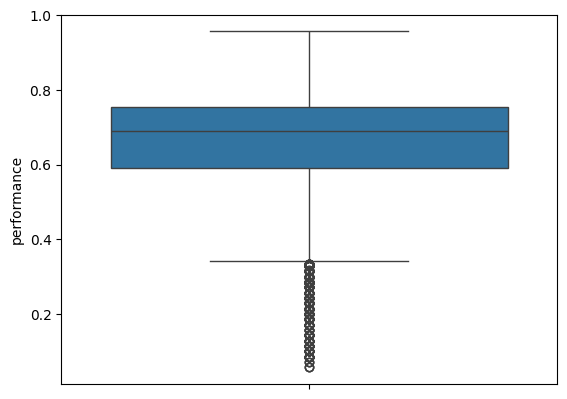

In [ ]:
sns.boxplot(scores_per_experiment, y="performance")
plt.show()

In [ ]:
scores_per_experiment["performance"].describe()

,performance
count,5400.000000
mean,0.653572
std,0.158729
min,0.057143
25%,0.590219
50%,0.689890
75%,0.755359
max,0.957143


Add back the metadata

In [ ]:
scores_per_experiment = pd.merge(scores_per_experiment, labels_long_no_inconclusive.drop_duplicates("experiment").set_index("experiment")[cols], how="left", on="experiment")
scores_per_experiment

,ling_category,performance,scoring_method,mlm,emb,topk,cont_emb,long_cont
experiment,,,,,,,,
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,adjectives,0.652273,hard,ModernBERT-base,all-MiniLM-L6-v2,100,0,0
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,genitive_NPs,0.783333,hard,ModernBERT-base,all-MiniLM-L6-v2,100,0,0
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,role_function_NPs,0.642857,hard,ModernBERT-base,all-MiniLM-L6-v2,100,0,0
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,verb_objects,0.785427,hard,ModernBERT-base,all-MiniLM-L6-v2,100,0,0
hard_ModernBERT-base_all-MiniLM-L6-v2_k100_0_0,verb_subjects,0.674619,hard,ModernBERT-base,all-MiniLM-L6-v2,100,0,0
...,...,...,...,...,...,...,...,...
soft_roberta-base_modernbert-embed-base_k5_contextual_1,adjectives,0.585317,soft,roberta-base,modernbert-embed-base,5,contextual,1
soft_roberta-base_modernbert-embed-base_k5_contextual_1,genitive_NPs,0.450000,soft,roberta-base,modernbert-embed-base,5,contextual,1
soft_roberta-base_modernbert-embed-base_k5_contextual_1,role_function_NPs,0.600000,soft,roberta-base,modernbert-embed-base,5,contextual,1


Inspect the best and worst scoring methods per linguistic category

In [ ]:
from collections import Counter

def show_top_n_results(n=5):
  top_mlm_counter = Counter()
  top_emb_counter = Counter()
  top_method_counter = Counter()
  top_k_counter = Counter()
  top_cont_emb_counter = Counter()
  top_long_cont_counter = Counter()

  for key, g in scores_per_experiment.groupby("ling_category"):
    print(key)
    top_n = g.sort_values(by="performance", ascending=False).head(n)
    tail_n = g.sort_values(by="performance", ascending=False).tail(n)
    print(f"TOP-{n}")
    for row in top_n.itertuples():
      print(f"{row.Index} {row.performance}")
      top_mlm_counter[row.mlm] += 1
      top_emb_counter[row.emb] += 1
      top_method_counter[row.scoring_method] += 1
      top_k_counter[row.topk] += 1
      top_cont_emb_counter[row.cont_emb] += 1
      top_long_cont_counter[row.long_cont] += 1

    print("...")
    print(f"WORST {n}")
    for row in tail_n.itertuples():
      print(f"{row.Index} {row.performance}")
    print("\n----------\n")

  print(f"Number of times MLMs appear in top-{n} results")
  for m, count in top_mlm_counter.most_common():
    print(m, count)

  print(f"\nNumber of times embedding models appear in top-{n} results")
  for m, count in top_emb_counter.most_common():
    print(m, count)

  print()
  counters = (top_method_counter, top_k_counter,
              top_cont_emb_counter, top_long_cont_counter)
  counter_names = ("method", "topk", "cont_emb", "long_cont")

  for c, cn in zip(counters, counter_names):
    print(cn)
    print("========")
    for m, count in c.most_common():
      print(m, count)
    print()

show_top_n_results(5)

adjectives
TOP-5
hard_distilbert-base-uncased_bge-base-en-v1.5_k5_0_0 0.7969647251845775
soft_distilbert-base-uncased_modernbert-embed-base_k5_0_0 0.7856921966807546
hard_distilbert-base-uncased_bge-base-en-v1.5_k10_0_0 0.7856921966807546
hard_distilbert-base-uncased_modernbert-embed-base_k10_0_0 0.7835502342529932
hard_distilbert-base-uncased_modernbert-embed-base_k1_0_0 0.7759259259259259
...
WORST 5
hard_roberta-base_all-MiniLM-L6-v2_k1_2_1 0.4617698091382302
soft_roberta-base_all-MiniLM-L6-v2_k1_2_1 0.4617698091382302
hard_ModernBERT-base_all-MiniLM-L6-v2_k1_2_1 0.4599146110056926
soft_ModernBERT-base_all-MiniLM-L6-v2_k1_2_1 0.4599146110056926
hard_ModernBERT-base_all-MiniLM-L6-v2_k5_2_1 0.45291005291005293

----------

genitive_NPs
TOP-5
soft_bert-large-uncased_bge-base-en-v1.5_k5_contextual_1 0.9
soft_bert-large-uncased_bge-base-en-v1.5_k10_contextual_1 0.9
soft_bert-large-uncased_all-MiniLM-L6-v2_k100_0_0 0.9
soft_bert-large-uncased_all-MiniLM-L6-v2_k150_0_0 0.9
soft_bert-large-

In [ ]:
show_top_n_results(10)

adjectives
TOP-10
hard_distilbert-base-uncased_bge-base-en-v1.5_k5_0_0 0.7969647251845775
soft_distilbert-base-uncased_modernbert-embed-base_k5_0_0 0.7856921966807546
hard_distilbert-base-uncased_bge-base-en-v1.5_k10_0_0 0.7856921966807546
hard_distilbert-base-uncased_modernbert-embed-base_k10_0_0 0.7835502342529932
hard_distilbert-base-uncased_modernbert-embed-base_k1_0_0 0.7759259259259259
soft_distilbert-base-uncased_modernbert-embed-base_k1_0_0 0.7759259259259259
soft_distilbert-base-uncased_modernbert-embed-base_k10_0_0 0.775
hard_distilbert-base-uncased_modernbert-embed-base_k5_0_0 0.7738787375415282
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k5_0_1 0.766149738112355
soft_bert-large-uncased_bge-base-en-v1.5_k5_0_0 0.7652819296979694
...
WORST 10
soft_roberta-base_all-MiniLM-L6-v2_k100_2_1 0.47619047619047616
hard_ModernBERT-base_all-MiniLM-L6-v2_k50_2_1 0.47619047619047616
soft_bert-large-uncased_all-MiniLM-L6-v2_k1_2_1 0.4689832089552239
hard_ModernBERT-base_all-MiniLM-L6-v2_

The above summaries show that the single best models (judging by the time they appear in the top results) are distilbert-base-uncased and modernbert-embed-base. However, the leading embedding model changes when all experiments are taken into account.

The following box plot shows how the performance results are distributed when different MLMs and embedding models are taken into account.

While all-MiniLM-L6-v2 (blue box) seems to have consistently higher average scores than the other embedding models, there are still other parameters affecting the performance, as all model combinations do produce very low scores, while them being more rare. And while modernbert-embed-base and bge-base-en-v1.5 perform worse than all-MiniLM-L6-v2 on average, bge-base-en-v1.5 has the single best scores in conjunction with each MLM, except for roberta-base. When it comes to MLMs, ModernBERT-base and roberta-base seem to be consistently worse than bert-base-uncased, bert-large-uncased, and distilbert-base-uncased.

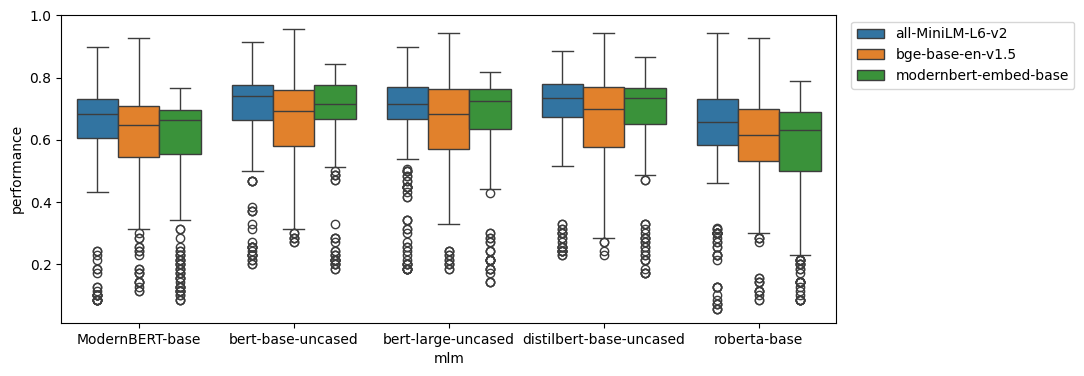

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(scores_per_experiment, y="performance", x="mlm", hue="emb", ax=ax)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

In [ ]:
scores_per_experiment.groupby(["mlm", "emb"], observed=True)["performance"].agg(["mean", "min", "max", "std"]).style.background_gradient()

If the model combinations are sorted by the max results obtained, bge-base-en-v1.5 outperforms all other embedding models. However, the max value can be from a successful performance from a single linguistic category, and doesn't necessarily reflect the overall performance of the model.

In [ ]:
scores_per_experiment.groupby(["mlm", "emb"], observed=True)["performance"].agg(["mean", "min", "max", "std"]).sort_values("max", ascending=False).style.background_gradient()

When the results are sorted by the highest mean perfromance, all-MiniLM-L6-v2 climbs to the top.

In [ ]:
scores_per_experiment.groupby(["mlm", "emb"], observed=True)["performance"].agg(["mean", "min", "max", "std"]).sort_values("mean", ascending=False).style.background_gradient()

,,mean,min,max,std
mlm,emb,,,,
distilbert-base-uncased,all-MiniLM-L6-v2,0.703300,0.228571,0.885714,0.134878
bert-base-uncased,all-MiniLM-L6-v2,0.696842,0.200000,0.914286,0.142978
bert-large-uncased,all-MiniLM-L6-v2,0.687954,0.185714,0.900000,0.151305
distilbert-base-uncased,modernbert-embed-base,0.687857,0.171429,0.866667,0.141461
bert-base-uncased,modernbert-embed-base,0.683514,0.185714,0.844501,0.142422
distilbert-base-uncased,bge-base-en-v1.5,0.673741,0.228571,0.942857,0.143606
bert-large-uncased,modernbert-embed-base,0.671724,0.142857,0.816667,0.144510
bert-base-uncased,bge-base-en-v1.5,0.669928,0.271429,0.957143,0.135252
bert-large-uncased,bge-base-en-v1.5,0.663526,0.185714,0.942857,0.150732


The following DataFrame includes 1080 rows; one row per experiment, where the score is the average from all 5 linguistic categories per experiment.

In [ ]:
average_per_experiment = (
    scores_per_experiment.groupby(level="experiment")["performance"]
    .mean()
    .sort_values(ascending=False)
)

average_per_experiment = pd.merge(average_per_experiment, labels_long_no_inconclusive.drop_duplicates("experiment").set_index("experiment")[cols], how="left", on="experiment")
average_per_experiment

,performance,scoring_method,mlm,emb,topk,cont_emb,long_cont
experiment,,,,,,,
soft_bert-large-uncased_all-MiniLM-L6-v2_k150_contextual_0,0.789773,soft,bert-large-uncased,all-MiniLM-L6-v2,150,contextual,0
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_0_1,0.789213,soft,distilbert-base-uncased,all-MiniLM-L6-v2,50,0,1
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k150_0_1,0.786603,soft,distilbert-base-uncased,all-MiniLM-L6-v2,150,0,1
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k100_0_1,0.786603,soft,distilbert-base-uncased,all-MiniLM-L6-v2,100,0,1
soft_bert-large-uncased_all-MiniLM-L6-v2_k100_contextual_0,0.785012,soft,bert-large-uncased,all-MiniLM-L6-v2,100,contextual,0
...,...,...,...,...,...,...,...
soft_roberta-base_all-MiniLM-L6-v2_k1_2_1,0.431329,soft,roberta-base,all-MiniLM-L6-v2,1,2,1
hard_roberta-base_all-MiniLM-L6-v2_k50_2_1,0.425963,hard,roberta-base,all-MiniLM-L6-v2,50,2,1
hard_roberta-base_all-MiniLM-L6-v2_k100_2_1,0.423894,hard,roberta-base,all-MiniLM-L6-v2,100,2,1


When the performance in each linguistic category is averaged within a single experiment, the distribution of the performance results looks like this:

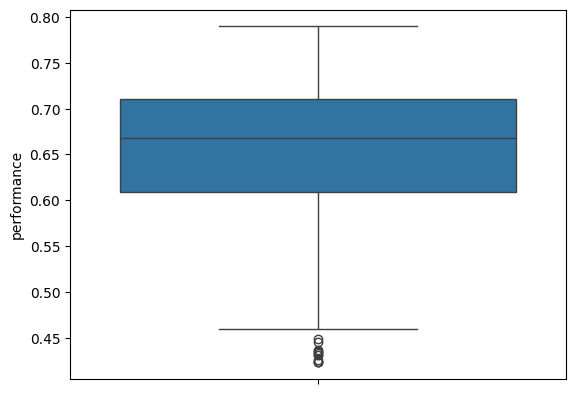

In [ ]:
sns.boxplot(average_per_experiment, y="performance")
plt.show()

In [ ]:
average_per_experiment["performance"].describe()

,performance
count,1080.000000
mean,0.653572
std,0.078179
min,0.423195
25%,0.609039
50%,0.667593
75%,0.710990
max,0.789773


When the average performance of the models is compared and exceptionally high scores from certain linguistic categories are flattened, bge-base-en-v1.5 isn't on top of the list anymore.

In [ ]:
average_per_experiment.groupby(["mlm", "emb"], observed=True)["performance"].agg(["mean", "min", "max", "std"]).sort_values("max", ascending=False)

mean       min       max  \
mlm                     emb                                                   
bert-large-uncased      all-MiniLM-L6-v2       0.687954  0.504853  0.789773   
distilbert-base-uncased all-MiniLM-L6-v2       0.703300  0.603741  0.789213   
bert-base-uncased       all-MiniLM-L6-v2       0.696842  0.534773  0.783511   
                        modernbert-embed-base  0.683514  0.567166  0.759093   
distilbert-base-uncased modernbert-embed-base  0.687857  0.603040  0.758455   
bert-large-uncased      modernbert-embed-base  0.671724  0.552451  0.751660   
roberta-base            all-MiniLM-L6-v2       0.627998  0.423195  0.750901   
ModernBERT-base         all-MiniLM-L6-v2       0.644107  0.459668  0.743098   
bert-large-uncased      bge-base-en-v1.5       0.663526  0.567033  0.738097   
distilbert-base-uncased bge-base-en-v1.5       0.673741  0.615093  0.729388   
bert-base-uncased       bge-base-en-v1.5       0.669928  0.586952  0.725703   
ModernBERT-base         modernbert-embed-base  0.588947  0.504476  0.703628   
                        bge-base-en-v1.5       0.627139  0.522438  0.688291   
roberta-base            bge-base-en-v1.5       0.607420  0.462199  0.680234   
                        modernbert-embed-base  0.569588  0.464771  0.673569   

                                                    std  
mlm                     emb                              
bert-large-uncased      all-MiniLM-L6-v2       0.090806  
distilbert-base-uncased all-MiniLM-L6-v2       0.064971  
bert-base-uncased       all-MiniLM-L6-v2       0.083891  
                        modernbert-embed-base  0.061774  
distilbert-base-uncased modernbert-embed-base  0.048271  
bert-large-uncased      modernbert-embed-base  0.060430  
roberta-base            all-MiniLM-L6-v2       0.106286  
ModernBERT-base         all-MiniLM-L6-v2       0.098693  
bert-large-uncased      bge-base-en-v1.5       0.043531  
distilbert-base-uncased bge-base-en-v1.5       0.027786  
bert-base-uncased       bge-base-en-v1.5       0.037030  
ModernBERT-base         modernbert-embed-base  0.059828  
                        bge-base-en-v1.5       0.050676  
roberta-base            bge-base-en-v1.5       0.066036  
                        modernbert-embed-base  0.064533

In [ ]:
average_per_experiment.groupby(["mlm", "emb"], observed=True)["performance"].agg(["mean", "min", "max", "std"]).sort_values("mean", ascending=False)

,,mean,min,max,std
mlm,emb,,,,
distilbert-base-uncased,all-MiniLM-L6-v2,0.703300,0.603741,0.789213,0.064971
bert-base-uncased,all-MiniLM-L6-v2,0.696842,0.534773,0.783511,0.083891
bert-large-uncased,all-MiniLM-L6-v2,0.687954,0.504853,0.789773,0.090806
distilbert-base-uncased,modernbert-embed-base,0.687857,0.603040,0.758455,0.048271
bert-base-uncased,modernbert-embed-base,0.683514,0.567166,0.759093,0.061774
distilbert-base-uncased,bge-base-en-v1.5,0.673741,0.615093,0.729388,0.027786
bert-large-uncased,modernbert-embed-base,0.671724,0.552451,0.751660,0.060430
bert-base-uncased,bge-base-en-v1.5,0.669928,0.586952,0.725703,0.037030
bert-large-uncased,bge-base-en-v1.5,0.663526,0.567033,0.738097,0.043531


When the overall performance per experiment (i.e. performance in each linguistic category collapsed into one number) is analyzed between MLM + embedding model combinations, the differences between models become more visible. Now, all-MiniLM-L6-v2 performs clearly better on average than the other embedding models, possibly suggesting a more balanced performance across different linguistic categories, while other models might do well in some categories and poorly in others. However, the long whiskers towards worse scores still show that some parameters do not work with all-MiniLM-L6-v2 at all.

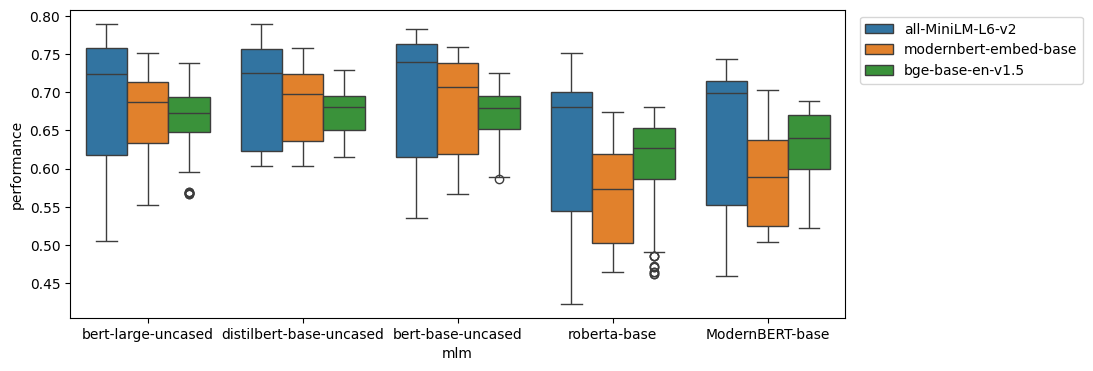

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(average_per_experiment, y="performance", x="mlm", hue="emb", ax=ax)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

One could ask if it is fair to compare the results from all experiments, as it by now clear that certain parameters do not work for all of the models. What if one compared only the best results from each model combination?

In [ ]:
experiments_to_compare = []
for key, g in average_per_experiment.groupby(["mlm", "emb"], observed=True):
  print(key)
  top_5 = g.sort_values("performance", ascending=False).head(5)
  print("Mean score of top-5:", top_5.performance.mean())
  for row in top_5.itertuples():
    experiments_to_compare.append(row.Index)
  print()
print("Number of experiments to compare:", len(experiments_to_compare))


('ModernBERT-base', 'all-MiniLM-L6-v2')
Mean score of top-5: 0.7359709167488308

('ModernBERT-base', 'bge-base-en-v1.5')
Mean score of top-5: 0.684339646254054

('ModernBERT-base', 'modernbert-embed-base')
Mean score of top-5: 0.6974483290288795

('bert-base-uncased', 'all-MiniLM-L6-v2')
Mean score of top-5: 0.7789779176599856

('bert-base-uncased', 'bge-base-en-v1.5')
Mean score of top-5: 0.7204251340462833

('bert-base-uncased', 'modernbert-embed-base')
Mean score of top-5: 0.7559031969907922

('bert-large-uncased', 'all-MiniLM-L6-v2')
Mean score of top-5: 0.7843370089335815

('bert-large-uncased', 'bge-base-en-v1.5')
Mean score of top-5: 0.7280018470492718

('bert-large-uncased', 'modernbert-embed-base')
Mean score of top-5: 0.7488616351414112

('distilbert-base-uncased', 'all-MiniLM-L6-v2')
Mean score of top-5: 0.7840483897664628

('distilbert-base-uncased', 'bge-base-en-v1.5')
Mean score of top-5: 0.7211135122475406

('distilbert-base-uncased', 'modernbert-embed-base')
Mean score 

In [ ]:
top5_comparison = average_per_experiment.loc[experiments_to_compare]
top5_comparison.sort_values("performance", ascending=False)

,performance,scoring_method,mlm,emb,topk,cont_emb,long_cont
experiment,,,,,,,
soft_bert-large-uncased_all-MiniLM-L6-v2_k150_contextual_0,0.789773,soft,bert-large-uncased,all-MiniLM-L6-v2,150,contextual,0
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k50_0_1,0.789213,soft,distilbert-base-uncased,all-MiniLM-L6-v2,50,0,1
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k150_0_1,0.786603,soft,distilbert-base-uncased,all-MiniLM-L6-v2,150,0,1
soft_distilbert-base-uncased_all-MiniLM-L6-v2_k100_0_1,0.786603,soft,distilbert-base-uncased,all-MiniLM-L6-v2,100,0,1
soft_bert-large-uncased_all-MiniLM-L6-v2_k100_contextual_0,0.785012,soft,bert-large-uncased,all-MiniLM-L6-v2,100,contextual,0
...,...,...,...,...,...,...,...
soft_roberta-base_modernbert-embed-base_k100_contextual_0,0.673569,soft,roberta-base,modernbert-embed-base,100,contextual,0
soft_roberta-base_modernbert-embed-base_k150_contextual_0,0.673569,soft,roberta-base,modernbert-embed-base,150,contextual,0
soft_roberta-base_modernbert-embed-base_k50_contextual_0,0.667378,soft,roberta-base,modernbert-embed-base,50,contextual,0


Even with the top-5 results for each MLM + embedding model combo, it seems like all-MiniLM-L6-v2 is clearly the best-performing embedding model, and the three older BERTs perform better than ModernBERT or roberta.

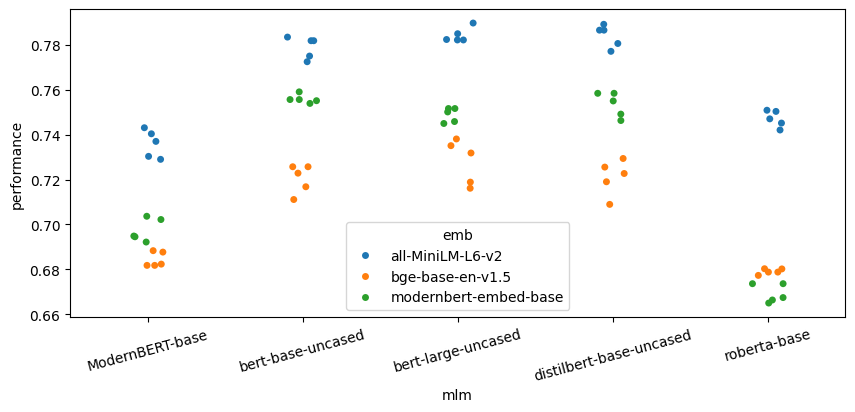

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.stripplot(top5_comparison, x="mlm", y="performance", hue="emb", ax=ax)
ax.tick_params(axis="x", rotation=15)
plt.show()

What if the same experiments are plotted by results from linguistic categories? This shows that ModernBERT seems to be competitive in the categories verb_subjects and verb_objects, but works poorly in the other categories.

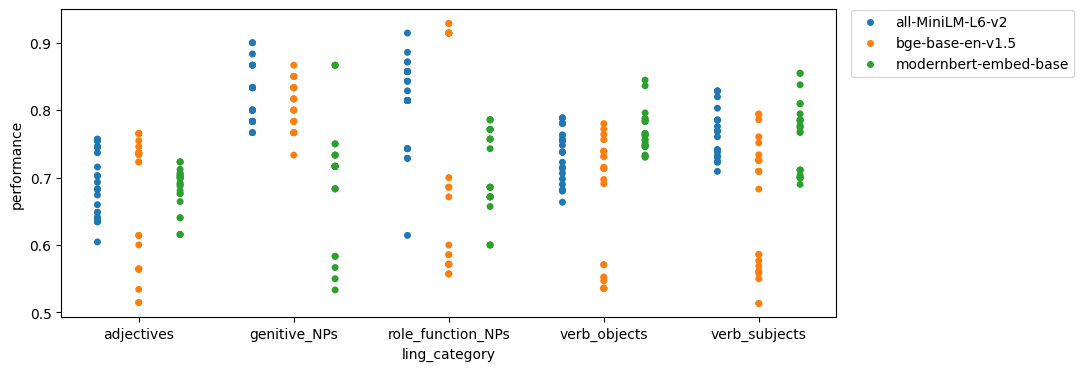

In [ ]:
top5_comparison_ling_cats = scores_per_experiment.loc[experiments_to_compare]
top5_comparison_ling_cats["models"] = (top5_comparison_ling_cats["mlm"].astype(str) + " + " + top5_comparison_ling_cats["emb"].astype(str)).astype("category")
fig, ax = plt.subplots(figsize=(10, 4))
sns.stripplot(top5_comparison_ling_cats, x="ling_category", y="performance", hue="emb", dodge=True, jitter=False, ax=ax)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.02))
plt.show()

When it comes to MLMs, it can be seen that the category adjectives has the overall lowest scores, and the scores in role_function_NPs is more spread.

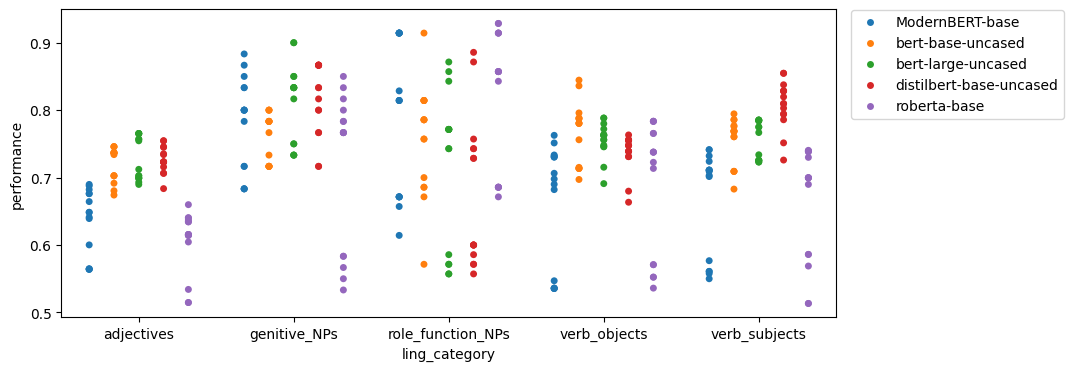

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.stripplot(top5_comparison_ling_cats, x="ling_category", y="performance", hue="mlm", dodge=True, jitter=False, ax=ax)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.02))
plt.show()

The following plot shows how the top-5 experiments per MLM+embedding model combination perform in each linguistic category. The ideal performance would be high on the y-axis, all dots clustering tightly together, signaling that there are no big differences between the performance in different linguistic categories. Given this requirement, the best combination seems to be bert-base-uncased + all-MiniLM-L6-v2. Also distilbert-base-uncased + all-MiniLM-L6-v2 combo seems to be pretty good, yet the scores are more spread.

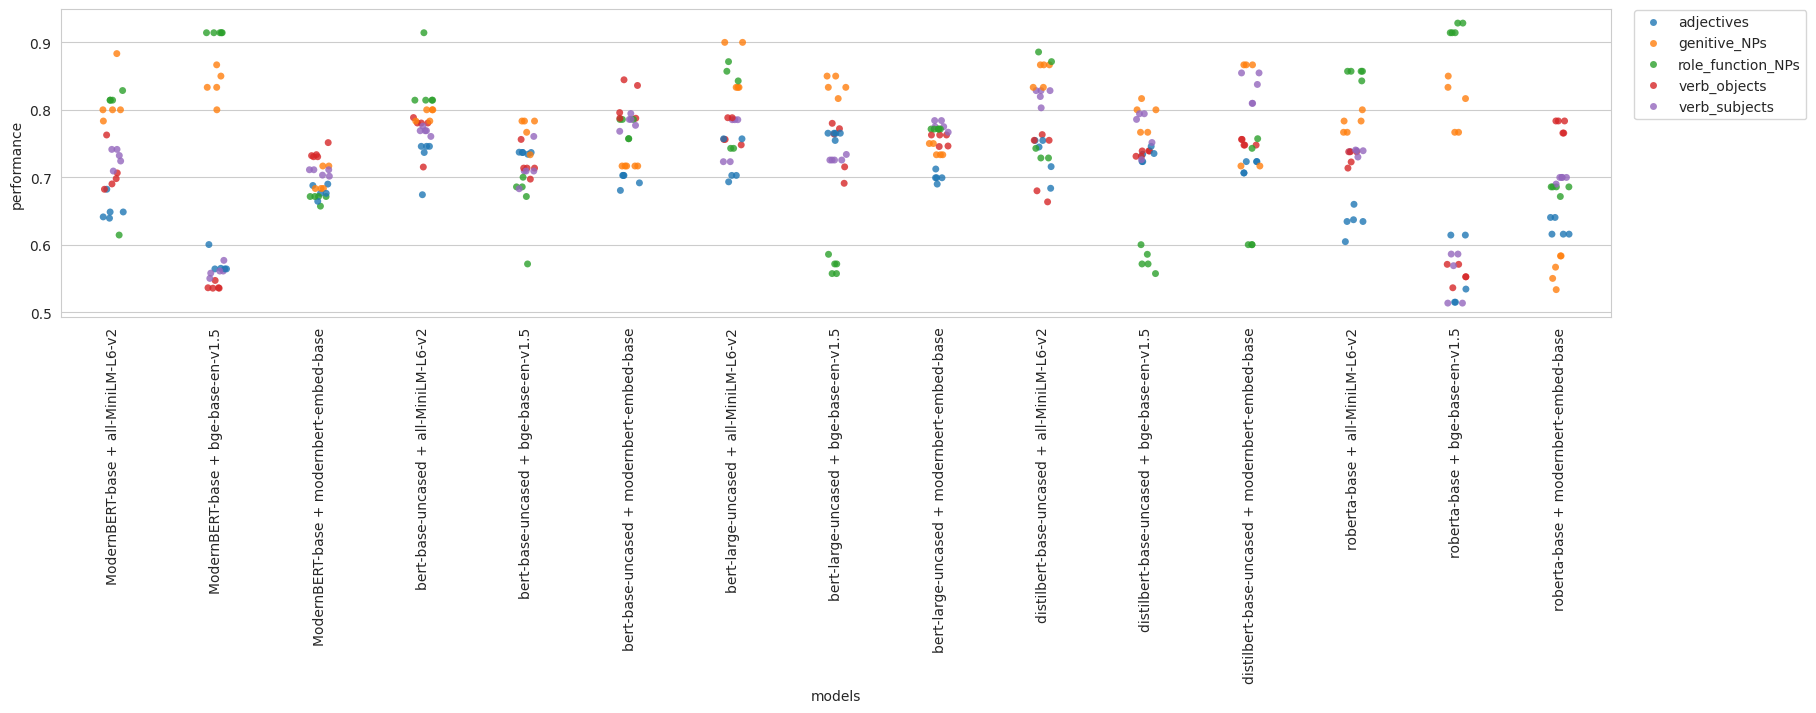

In [ ]:
with sns.axes_style("whitegrid"):
  fig, ax = plt.subplots(figsize=(20, 4))
  sns.stripplot(top5_comparison_ling_cats, x="models", y="performance", hue="ling_category", alpha=0.8, ax=ax)
  ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.02))
  ax.tick_params(axis="x", rotation=90)
  plt.show()

What about top-1 per model combo only? (Values sorted in descending order by average score.)

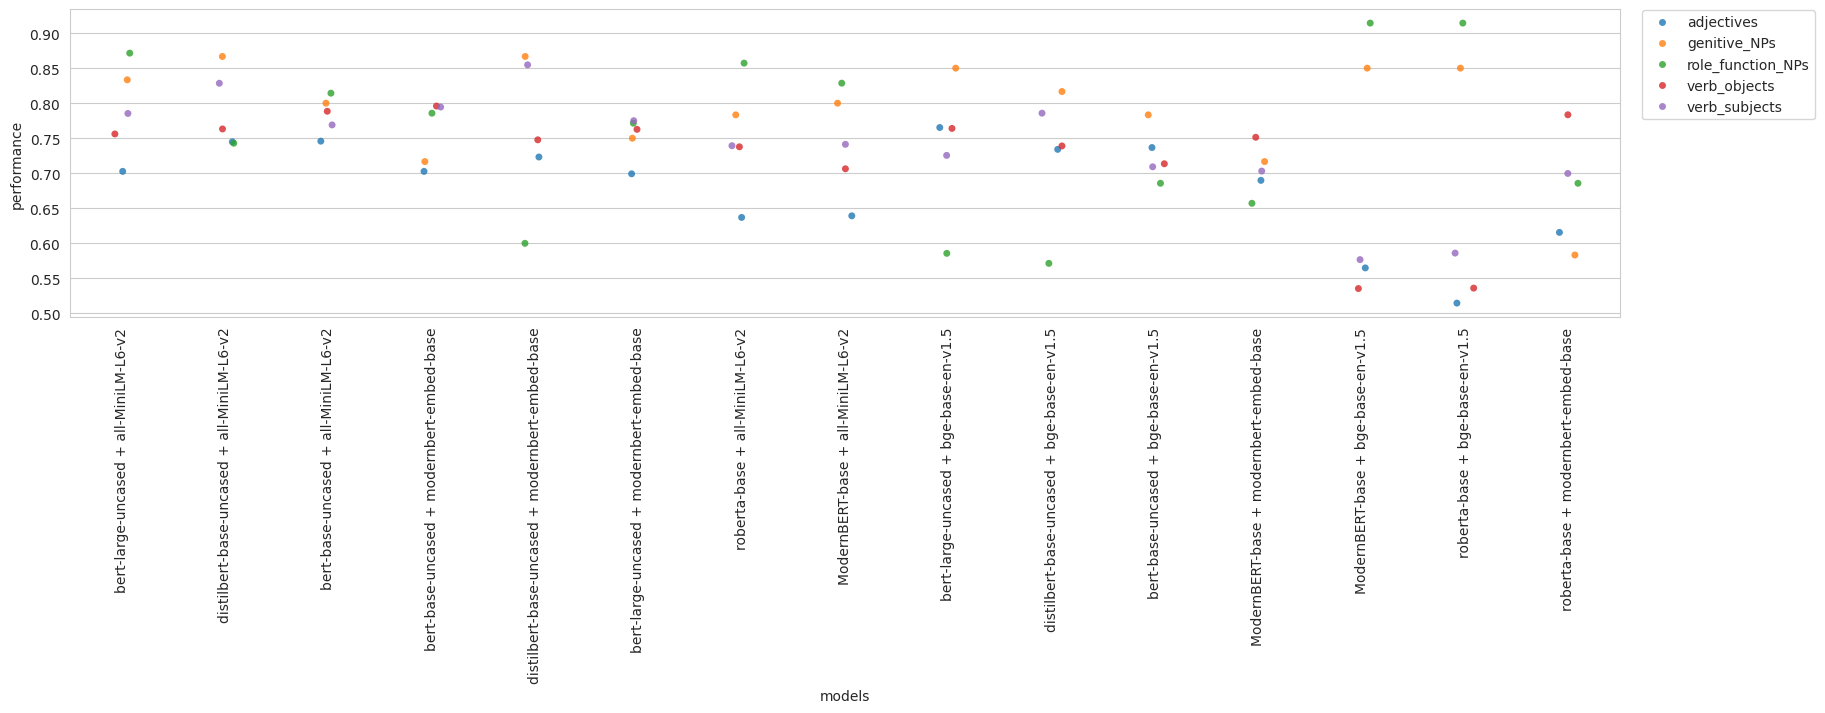

In [ ]:
top1_to_compare = []
for key, g in average_per_experiment.groupby(["mlm", "emb"], observed=True):
  top1_to_compare.append(g.sort_values("performance", ascending=False).head(1).index[0])

to_plot = scores_per_experiment.loc[top1_to_compare]
to_plot["models"] = (to_plot["mlm"].astype(str) + " + " + to_plot["emb"].astype(str)).astype("category")
average_per_experiment["models"] = (average_per_experiment["mlm"].astype(str) + " + " + average_per_experiment["emb"].astype(str)).astype("category")

order = average_per_experiment.loc[top1_to_compare].sort_values("performance", ascending=False).models.tolist()

with sns.axes_style("whitegrid"):
  fig, ax = plt.subplots(figsize=(20, 4))
  sns.stripplot(to_plot, x="models", y="performance", hue="ling_category", order=order, alpha=0.8, ax=ax)
  ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.02))
  ax.tick_params(axis="x", rotation=90)
  plt.show()

How many of the 1080 experiments have a higher performance score than AnthroScore?

In [ ]:
anthroscore_mean = anthroscores_scored.performance.mean()
better_than_anthroscore = len(average_per_experiment[average_per_experiment["performance"] > anthroscore_mean])
print(f"{better_than_anthroscore / len(average_per_experiment):.2%} ({better_than_anthroscore} / {len(average_per_experiment)}) of the experiments outperform AnthroScore")

100.00% (1080 / 1080) of the experiments outperform AnthroScore


Upload a csv holding the runtime information.

In [ ]:
with open(new_runtime_filename) as file:
  new_runtimes = [json.loads(line) for line in file]

In [ ]:
runtime_df = pd.DataFrame.from_records(new_runtimes)

In [ ]:
runtime_df = runtime_df.astype({"mlm": "category", "emb": "category", "long_cont": int})
runtime_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   mlm        30 non-null     category
 1   emb        30 non-null     category
 2   long_cont  30 non-null     int64   
 3   runtime    30 non-null     float64 
dtypes: category(2), float64(1), int64(1)
memory usage: 1016.0 bytes


Merge the data from average scores per experiment.

In [ ]:
average_and_runtime = pd.merge(average_per_experiment, runtime_df, on=["mlm", "emb", "long_cont"])

In [ ]:
average_and_runtime

,performance,scoring_method,mlm,emb,topk,cont_emb,long_cont,models,runtime
0,0.789773,soft,bert-large-uncased,all-MiniLM-L6-v2,150,contextual,0,bert-large-uncased + all-MiniLM-L6-v2,57.742578
1,0.789213,soft,distilbert-base-uncased,all-MiniLM-L6-v2,50,0,1,distilbert-base-uncased + all-MiniLM-L6-v2,153.054563
2,0.786603,soft,distilbert-base-uncased,all-MiniLM-L6-v2,150,0,1,distilbert-base-uncased + all-MiniLM-L6-v2,153.054563
3,0.786603,soft,distilbert-base-uncased,all-MiniLM-L6-v2,100,0,1,distilbert-base-uncased + all-MiniLM-L6-v2,153.054563
4,0.785012,soft,bert-large-uncased,all-MiniLM-L6-v2,100,contextual,0,bert-large-uncased + all-MiniLM-L6-v2,57.742578
...,...,...,...,...,...,...,...,...,...
1075,0.431329,soft,roberta-base,all-MiniLM-L6-v2,1,2,1,roberta-base + all-MiniLM-L6-v2,141.371784
1076,0.425963,hard,roberta-base,all-MiniLM-L6-v2,50,2,1,roberta-base + all-MiniLM-L6-v2,141.371784
1077,0.423894,hard,roberta-base,all-MiniLM-L6-v2,100,2,1,roberta-base + all-MiniLM-L6-v2,141.371784
1078,0.423894,hard,roberta-base,all-MiniLM-L6-v2,150,2,1,roberta-base + all-MiniLM-L6-v2,141.371784


A first look into how model performance compares to runtime.

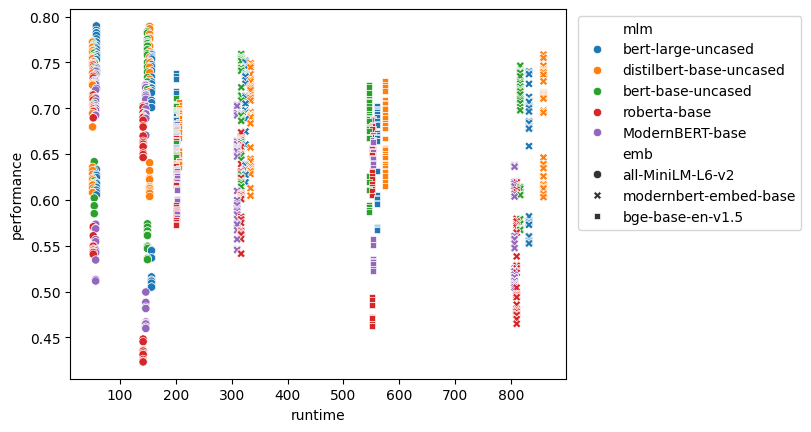

In [ ]:
fig, ax = plt.subplots()
sns.scatterplot(average_and_runtime, y="performance", x="runtime", hue="mlm", style="emb", ax=ax)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

In [ ]:
min_max_mean = (
    average_and_runtime
    .groupby(["mlm", "emb", "long_cont"], observed=True)["performance"]
    .agg(["min", "max", "mean"])
)
min_max_mean

min       max  \
mlm                     emb                   long_cont                       
ModernBERT-base         all-MiniLM-L6-v2      0          0.511495  0.743098   
                                              1          0.459668  0.725859   
                        bge-base-en-v1.5      0          0.578486  0.682290   
                                              1          0.522438  0.688291   
                        modernbert-embed-base 0          0.545384  0.703628   
                                              1          0.504476  0.638141   
bert-base-uncased       all-MiniLM-L6-v2      0          0.585002  0.769788   
                                              1          0.534773  0.783511   
                        bge-base-en-v1.5      0          0.633794  0.711092   
                                              1          0.586952  0.725703   
                        modernbert-embed-base 0          0.601172  0.759093   
                                              1          0.567166  0.746316   
bert-large-uncased      all-MiniLM-L6-v2      0          0.605369  0.789773   
                                              1          0.504853  0.760009   
                        bge-base-en-v1.5      0          0.631423  0.738097   
                                              1          0.567033  0.702159   
                        modernbert-embed-base 0          0.619196  0.751660   
                                              1          0.552451  0.740161   
distilbert-base-uncased all-MiniLM-L6-v2      0          0.607873  0.773177   
                                              1          0.603741  0.789213   
                        bge-base-en-v1.5      0          0.635310  0.706290   
                                              1          0.615093  0.729388   
                        modernbert-embed-base 0          0.604509  0.749172   
                                              1          0.603040  0.758455   
roberta-base            all-MiniLM-L6-v2      0          0.540670  0.750901   
                                              1          0.423195  0.702223   
                        bge-base-en-v1.5      0          0.572540  0.678739   
                                              1          0.462199  0.680234   
                        modernbert-embed-base 0          0.541270  0.673569   
                                              1          0.464771  0.620043   

                                                             mean  
mlm                     emb                   long_cont            
ModernBERT-base         all-MiniLM-L6-v2      0          0.659421  
                                              1          0.628794  
                        bge-base-en-v1.5      0          0.633730  
                                              1          0.620547  
                        modernbert-embed-base 0          0.622245  
                                              1          0.555649  
bert-base-uncased       all-MiniLM-L6-v2      0          0.703083  
                                              1          0.690600  
                        bge-base-en-v1.5      0          0.676191  
                                              1          0.663664  
                        modernbert-embed-base 0          0.689432  
                                              1          0.677597  
bert-large-uncased      all-MiniLM-L6-v2      0          0.713554  
                                              1          0.662355  
                        bge-base-en-v1.5      0          0.680141  
                                              1          0.646912  
                        modernbert-embed-base 0          0.688154  
                                              1          0.655295  
distilbert-base-uncased all-MiniLM-L6-v2      0          0.697462  
                                              1          0.709139  
                        bge-base-en-v

In [ ]:
min_max_mean_runtime = pd.merge(min_max_mean, runtime_df, on=["mlm", "emb", "long_cont"], how="left")
min_max_mean_runtime

,mlm,emb,long_cont,min,max,mean,runtime
0,ModernBERT-base,all-MiniLM-L6-v2,0,0.511495,0.743098,0.659421,56.449957
1,ModernBERT-base,all-MiniLM-L6-v2,1,0.459668,0.725859,0.628794,146.187543
2,ModernBERT-base,bge-base-en-v1.5,0,0.578486,0.682290,0.633730,202.000752
3,ModernBERT-base,bge-base-en-v1.5,1,0.522438,0.688291,0.620547,552.872872
4,ModernBERT-base,modernbert-embed-base,0,0.545384,0.703628,0.622245,309.618205
5,ModernBERT-base,modernbert-embed-base,1,0.504476,0.638141,0.555649,806.240570
6,bert-base-uncased,all-MiniLM-L6-v2,0,0.585002,0.769788,0.703083,53.909953
7,bert-base-uncased,all-MiniLM-L6-v2,1,0.534773,0.783511,0.690600,149.185979
8,bert-base-uncased,bge-base-en-v1.5,0,0.633794,0.711092,0.676191,200.149717
9,bert-base-uncased,bge-base-en-v1.5,1,0.586952,0.725703,0.663664,545.888335


In [ ]:
min_max_mean_runtime["models"] = (min_max_mean_runtime["emb"].astype(str) + " +\n" + min_max_mean_runtime["mlm"].astype(str)).astype("category")

In [ ]:
from itertools import repeat
linestyles = []
for i in range(3):
  linestyles.extend(["solid", "dotted", "dashed", "dashdot", (5, (10, 3))])
linestyles

['solid',
 'dotted',
 'dashed',
 'dashdot',
 (5, (10, 3)),
 'solid',
 'dotted',
 'dashed',
 'dashdot',
 (5, (10, 3)),
 'solid',
 'dotted',
 'dashed',
 'dashdot',
 (5, (10, 3))]

In [ ]:
for style in ("solid", "dotted", "dashed", "dashdot", (5, (10, 3))):
  for item in repeat(style, 5):
    linestyles.append(item)

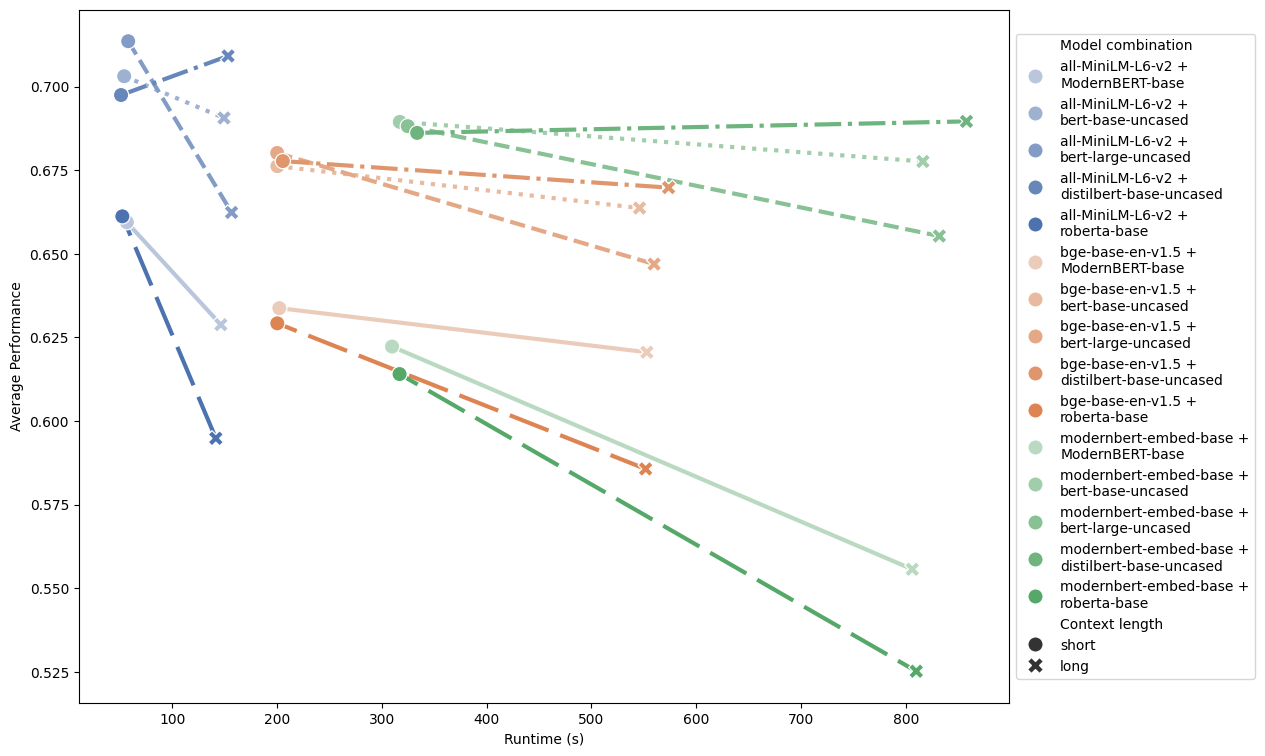

In [ ]:
# Example data structure:
# df columns: model_combo, context, runtime, performance
# context is "short" or "long"

fig, ax = plt.subplots(figsize=(12, 9))

# Assign consistent colors per model combo
combos = min_max_mean_runtime["models"].unique().sort_values()
palette_map = dict(zip(combos, palette))
linestyle_map = dict(zip(combos, linestyles))

# Draw connecting lines first (so points sit on top)
for combo in combos:
    sub = min_max_mean_runtime[min_max_mean_runtime["models"] == combo]
    ax.plot(
        sub["runtime"], sub["mean"],
        color=palette_map[combo], linewidth=3, zorder=1, linestyle=linestyle_map[combo]
    )

# Draw points on top, colored by combo, styled by context
sns.scatterplot(
    data=(
        min_max_mean_runtime
        .rename(columns={"models": "Model combination", "long_cont": "Context length"})
        .replace({"Context length": {0: "short", 1: "long"}})), x="runtime", y="mean",
    hue="Model combination", style="Context length",
    palette=palette, s=120, ax=ax, zorder=2
)

ax.set_xlabel("Runtime (s)")
ax.set_ylabel("Average Performance")
sns.move_legend(ax, loc="center left", bbox_to_anchor=(1, 0.5))
fig.savefig("runtime_vs_performance.pdf", bbox_inches="tight")

Reformat the data so that min, max and mean values are assigned their own row

In [ ]:
min_max_mean_runtime_long = min_max_mean_runtime.melt(
    id_vars = ["mlm", "emb", "long_cont", "runtime"],
    value_vars = ["min", "max", "mean"],
    var_name = "experiment",
    value_name = "performance"
)

In [ ]:
min_max_mean_runtime_long

,mlm,emb,long_cont,runtime,experiment,performance
0,ModernBERT-base,all-MiniLM-L6-v2,0,56.449957,min,0.511495
1,ModernBERT-base,all-MiniLM-L6-v2,1,146.187543,min,0.459668
2,ModernBERT-base,bge-base-en-v1.5,0,202.000752,min,0.578486
3,ModernBERT-base,bge-base-en-v1.5,1,552.872872,min,0.522438
4,ModernBERT-base,modernbert-embed-base,0,309.618205,min,0.545384
...,...,...,...,...,...,...
85,roberta-base,all-MiniLM-L6-v2,1,141.371784,mean,0.594813
86,roberta-base,bge-base-en-v1.5,0,200.081495,mean,0.629190
87,roberta-base,bge-base-en-v1.5,1,551.677127,mean,0.585650
88,roberta-base,modernbert-embed-base,0,316.796612,mean,0.614019


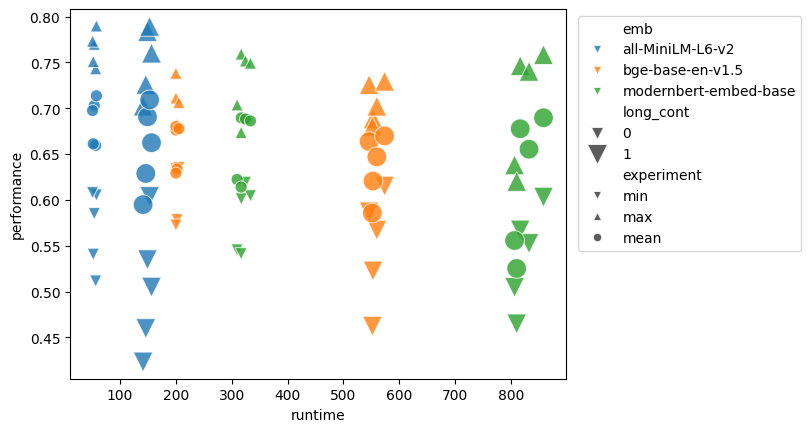

In [ ]:
fig, ax = plt.subplots()
sns.scatterplot(
    min_max_mean_runtime_long,
    y="performance", x="runtime", hue="emb", style="experiment", markers={"max": "^", "mean": "o", "min": "v"},
    size="long_cont", sizes={0: 75, 1: 200}, alpha=0.8, ax=ax
    )
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

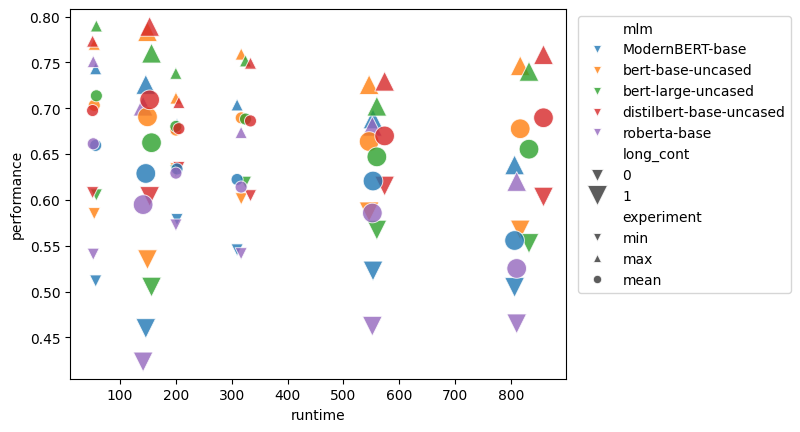

In [ ]:
fig, ax = plt.subplots()
sns.scatterplot(
    min_max_mean_runtime_long,
    y="performance", x="runtime", hue="mlm", style="experiment", markers={"max": "^", "mean": "o", "min": "v"},
    size="long_cont", sizes={0: 75, 1: 200}, alpha=0.8, ax=ax
    )
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

In [ ]:
min_max_mean_runtime_long

,mlm,emb,long_cont,runtime,experiment,performance
0,ModernBERT-base,all-MiniLM-L6-v2,0,56.449957,min,0.511495
1,ModernBERT-base,all-MiniLM-L6-v2,1,146.187543,min,0.459668
2,ModernBERT-base,bge-base-en-v1.5,0,202.000752,min,0.578486
3,ModernBERT-base,bge-base-en-v1.5,1,552.872872,min,0.522438
4,ModernBERT-base,modernbert-embed-base,0,309.618205,min,0.545384
...,...,...,...,...,...,...
85,roberta-base,all-MiniLM-L6-v2,1,141.371784,mean,0.594813
86,roberta-base,bge-base-en-v1.5,0,200.081495,mean,0.629190
87,roberta-base,bge-base-en-v1.5,1,551.677127,mean,0.585650
88,roberta-base,modernbert-embed-base,0,316.796612,mean,0.614019


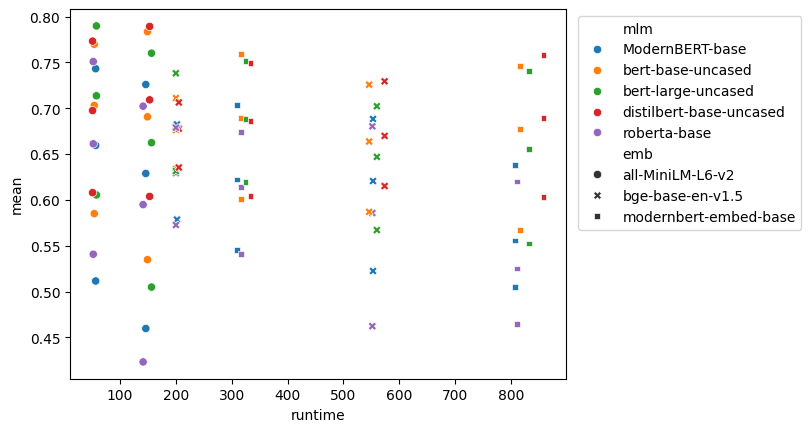

In [ ]:
fig, ax = plt.subplots()
sns.scatterplot(min_max_mean_runtime, y="mean", x="runtime", hue="mlm", style="emb", ax=ax)
sns.scatterplot(min_max_mean_runtime, y="max", x="runtime", hue="mlm", style="emb", ax=ax, legend=False)
sns.scatterplot(min_max_mean_runtime, y="min", x="runtime", hue="mlm", style="emb", ax=ax, legend=False)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()


The following table shows the average, best and worst performance of MLM + embedding model combo

In [ ]:
mean_max_mlm_emb = (average_per_experiment.groupby(["mlm", "emb"], observed=True)["performance"]
 .agg(["mean", "max"])
 .unstack("emb")
 .swaplevel(axis=1)
 .sort_index(axis=1, ascending=False)
 )

mean_max_mlm_emb

emb                     modernbert-embed-base           bge-base-en-v1.5  \
                                         mean       max             mean   
mlm                                                                        
ModernBERT-base                      0.588947  0.703628         0.627139   
bert-base-uncased                    0.683514  0.759093         0.669928   
bert-large-uncased                   0.671724  0.751660         0.663526   
distilbert-base-uncased              0.687857  0.758455         0.673741   
roberta-base                         0.569588  0.673569         0.607420   

emb                               all-MiniLM-L6-v2            
                              max             mean       max  
mlm                                                           
ModernBERT-base          0.688291         0.644107  0.743098  
bert-base-uncased        0.725703         0.696842  0.783511  
bert-large-uncased       0.738097         0.687954  0.789773  
distilbert-base-uncased  0.729388         0.703300  0.789213  
roberta-base             0.680234         0.627998  0.750901

In [ ]:
print(mean_max_mlm_emb.to_latex())

\begin{tabular}{lrrrrrr}
\toprule
emb & \multicolumn{2}{r}{modernbert-embed-base} & \multicolumn{2}{r}{bge-base-en-v1.5} & \multicolumn{2}{r}{all-MiniLM-L6-v2} \\
 & mean & max & mean & max & mean & max \\
mlm &  &  &  &  &  &  \\
\midrule
ModernBERT-base & 0.588947 & 0.703628 & 0.627139 & 0.688291 & 0.644107 & 0.743098 \\
bert-base-uncased & 0.683514 & 0.759093 & 0.669928 & 0.725703 & 0.696842 & 0.783511 \\
bert-large-uncased & 0.671724 & 0.751660 & 0.663526 & 0.738097 & 0.687954 & 0.789773 \\
distilbert-base-uncased & 0.687857 & 0.758455 & 0.673741 & 0.729388 & 0.703300 & 0.789213 \\
roberta-base & 0.569588 & 0.673569 & 0.607420 & 0.680234 & 0.627998 & 0.750901 \\
\bottomrule
\end{tabular}



## Differences between linguistic categories

With the following plots, I am trying to inspect how the scores are distributed in different linguistic categories.

It is clear that role_function_NPs is a category that only works with certain parameters that are yet to be discovered.

In [ ]:
scores_per_experiment["models"] = (scores_per_experiment["mlm"].astype(str) + " + " + scores_per_experiment["emb"].astype(str)).astype("category")

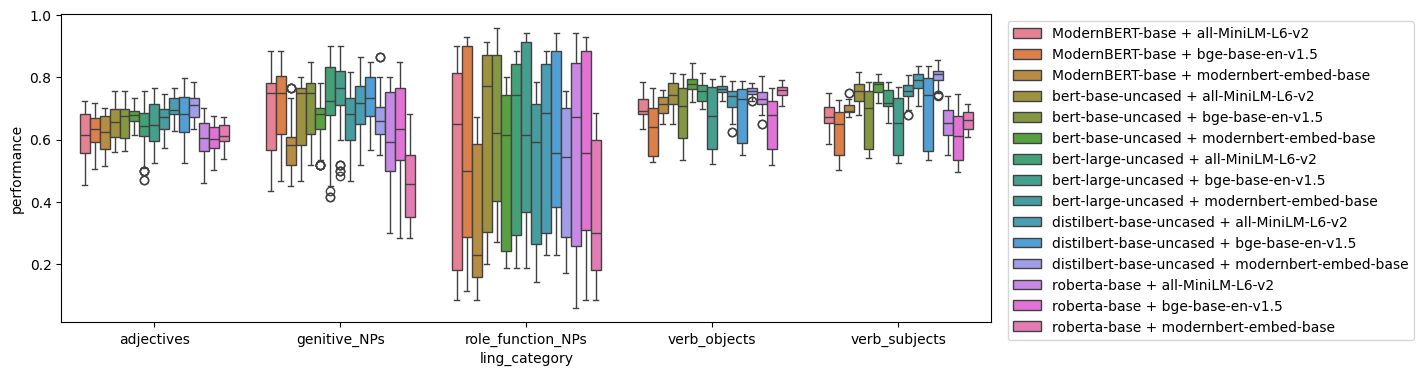

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(scores_per_experiment, x="ling_category", y="performance", hue="models")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

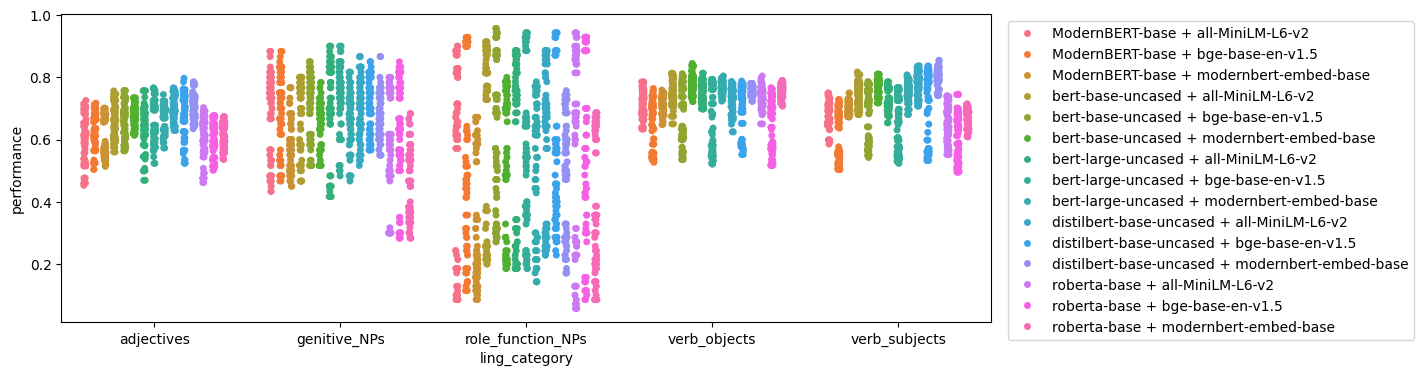

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.stripplot(scores_per_experiment, x="ling_category", y="performance", hue="models", dodge=True)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

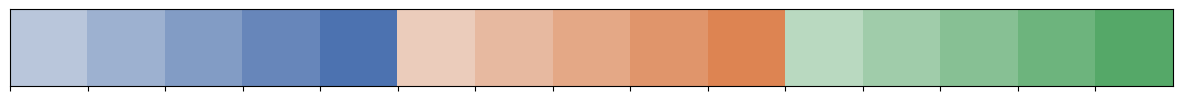

In [ ]:
base_colors = ["#4C72B0", "#DD8452", "#55A868"]  # blue, orange, green
n_shades = 5

palette = []
for color in base_colors:
    shades = sns.light_palette(color, n_colors=n_shades + 2)[2:]  # skip near-white
    palette.extend(shades)

sns.palplot(palette)

In [ ]:
hue_order = [f"{e} + {m}" for e in scores_per_experiment.emb.unique() for m in scores_per_experiment.mlm.unique()]

hue_order

['all-MiniLM-L6-v2 + ModernBERT-base',
 'all-MiniLM-L6-v2 + bert-base-uncased',
 'all-MiniLM-L6-v2 + bert-large-uncased',
 'all-MiniLM-L6-v2 + distilbert-base-uncased',
 'all-MiniLM-L6-v2 + roberta-base',
 'bge-base-en-v1.5 + ModernBERT-base',
 'bge-base-en-v1.5 + bert-base-uncased',
 'bge-base-en-v1.5 + bert-large-uncased',
 'bge-base-en-v1.5 + distilbert-base-uncased',
 'bge-base-en-v1.5 + roberta-base',
 'modernbert-embed-base + ModernBERT-base',
 'modernbert-embed-base + bert-base-uncased',
 'modernbert-embed-base + bert-large-uncased',
 'modernbert-embed-base + distilbert-base-uncased',
 'modernbert-embed-base + roberta-base']

In [ ]:
scores_per_experiment["models_2"] = (scores_per_experiment["emb"].astype(str) + " + " + scores_per_experiment["mlm"].astype(str)).astype("category")

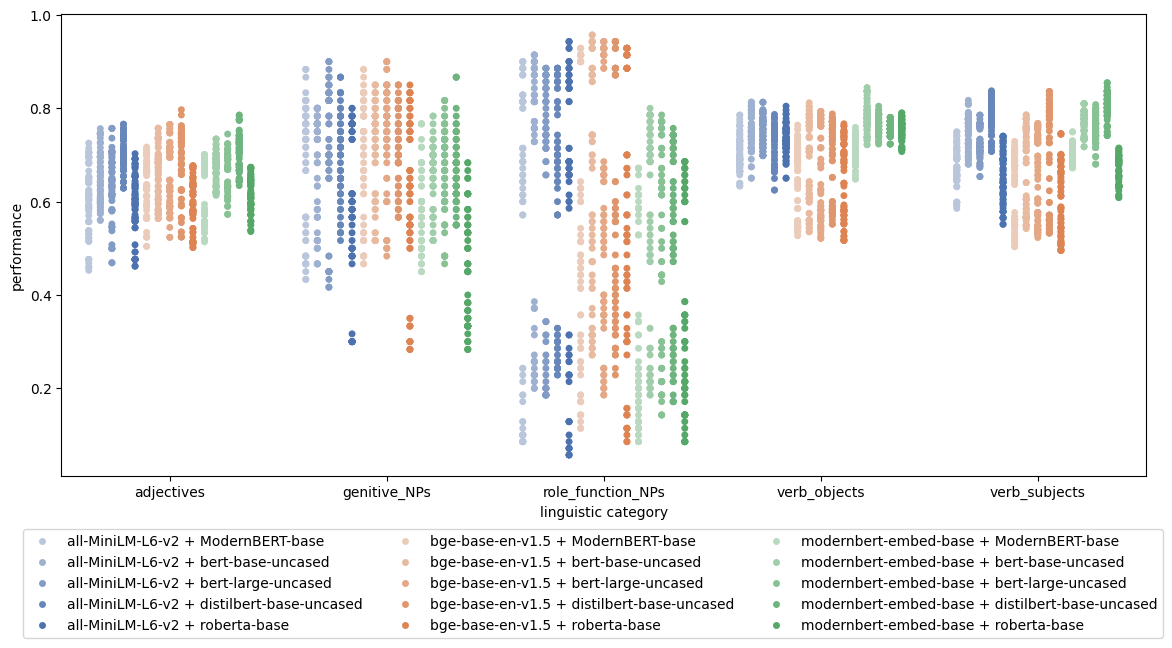

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))
ax = sns.stripplot(scores_per_experiment, x="ling_category", y="performance", hue="models_2", dodge=True, jitter=False, hue_order=hue_order, palette=palette)
ax.legend(loc="upper center", bbox_to_anchor=(0.49, -0.1), ncol=3)
ax.set_xlabel("linguistic category")
plt.savefig("performance_overview_v2.pdf", bbox_inches="tight")

plt.show()

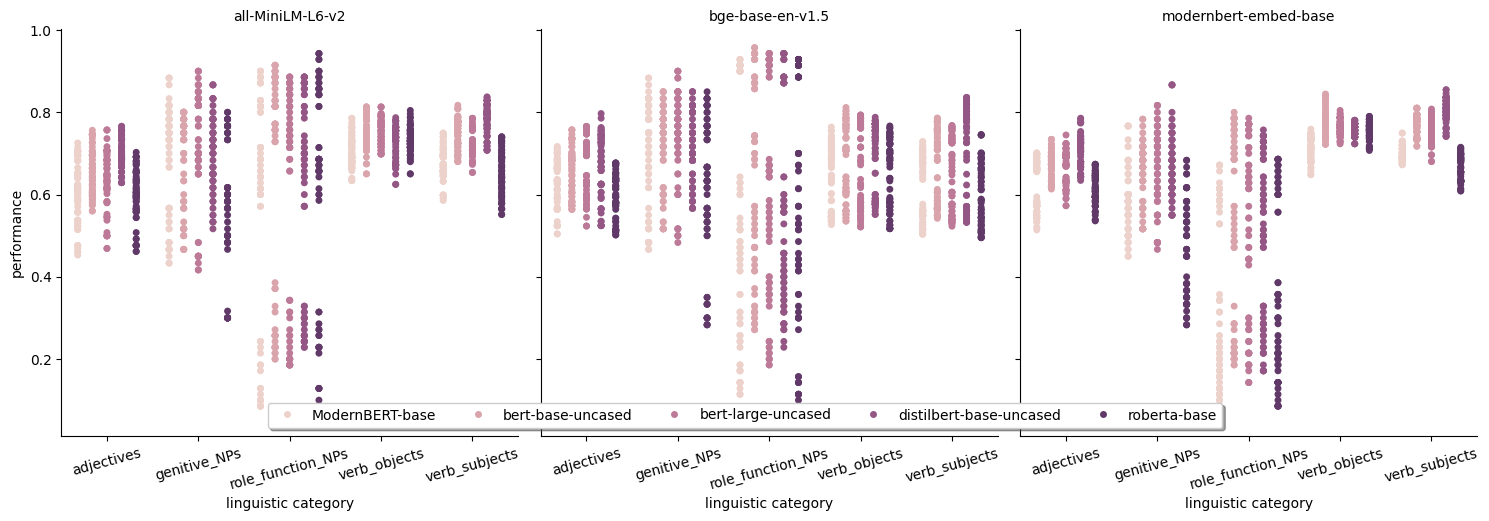

In [ ]:
with sns.cubehelix_palette():
  g = sns.catplot(scores_per_experiment, x="ling_category", y="performance", hue="mlm", col="emb", dodge=True, jitter=False, legend_out=False)
  g.set_xticklabels(rotation=15)
  g.set_xlabels("linguistic category")
  g.set_titles("{col_name}")
  sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, 0.12), ncol=5, title=None, shadow=True)
  #plt.savefig("performance_overview.pdf", bbox_inches="tight")

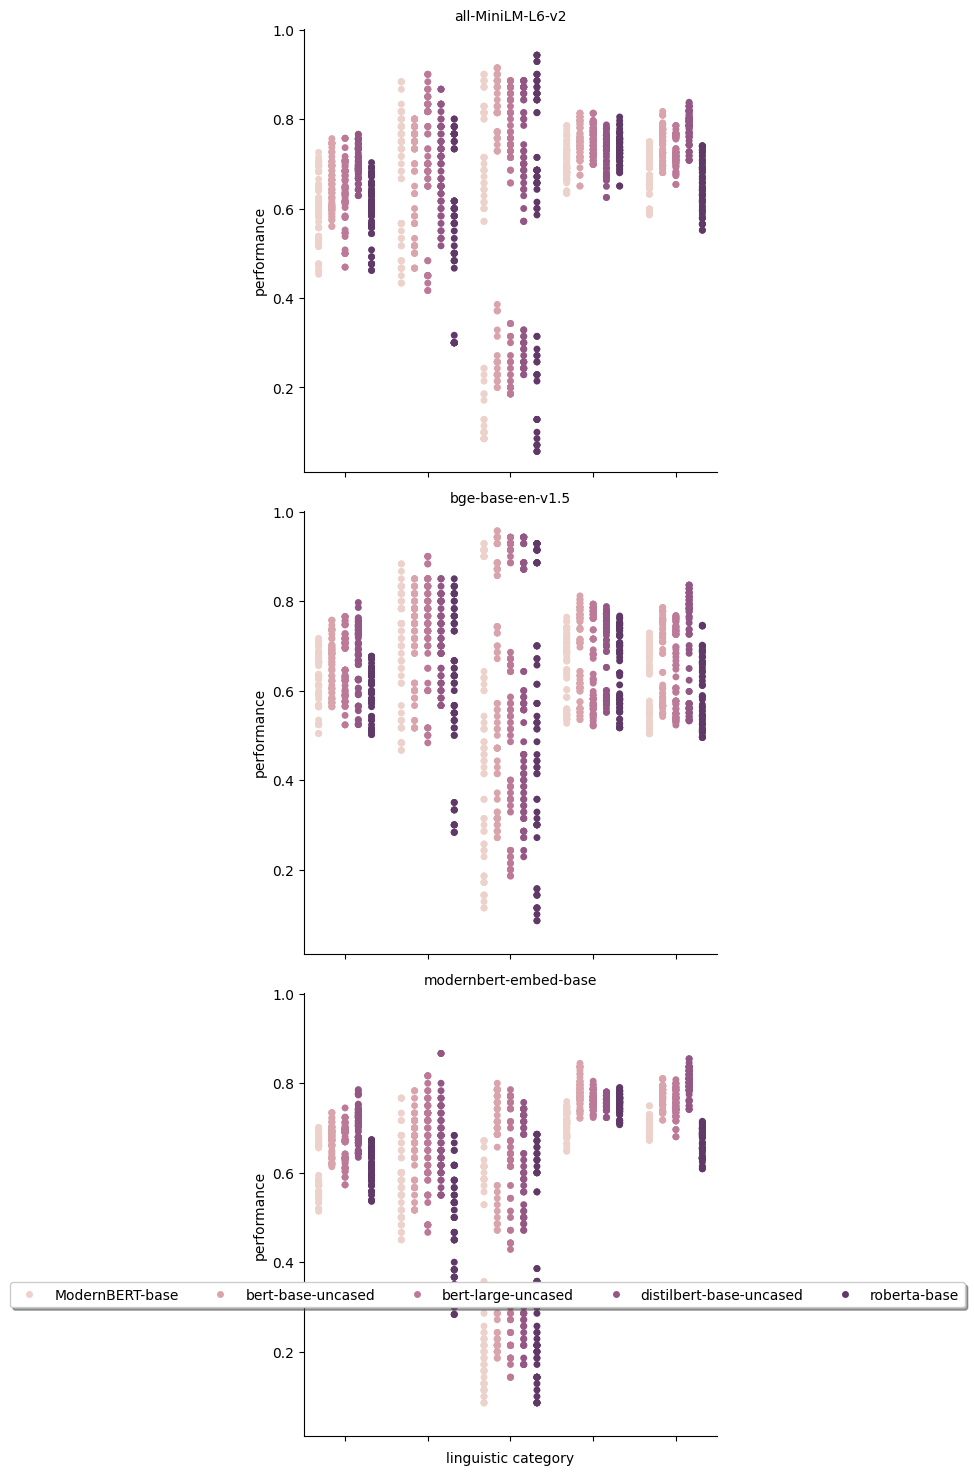

In [ ]:
with sns.cubehelix_palette():
  g = sns.catplot(scores_per_experiment, x="ling_category", y="performance", hue="mlm", row="emb", dodge=True, jitter=False, legend_out=False)
  g.set_xticklabels(rotation=15)
  g.set_xlabels("linguistic category")
  g.set_titles("{row_name}")
  sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, 0.12), ncol=5, title=None, shadow=True)
  #plt.savefig("performance_overview.pdf", bbox_inches="tight")

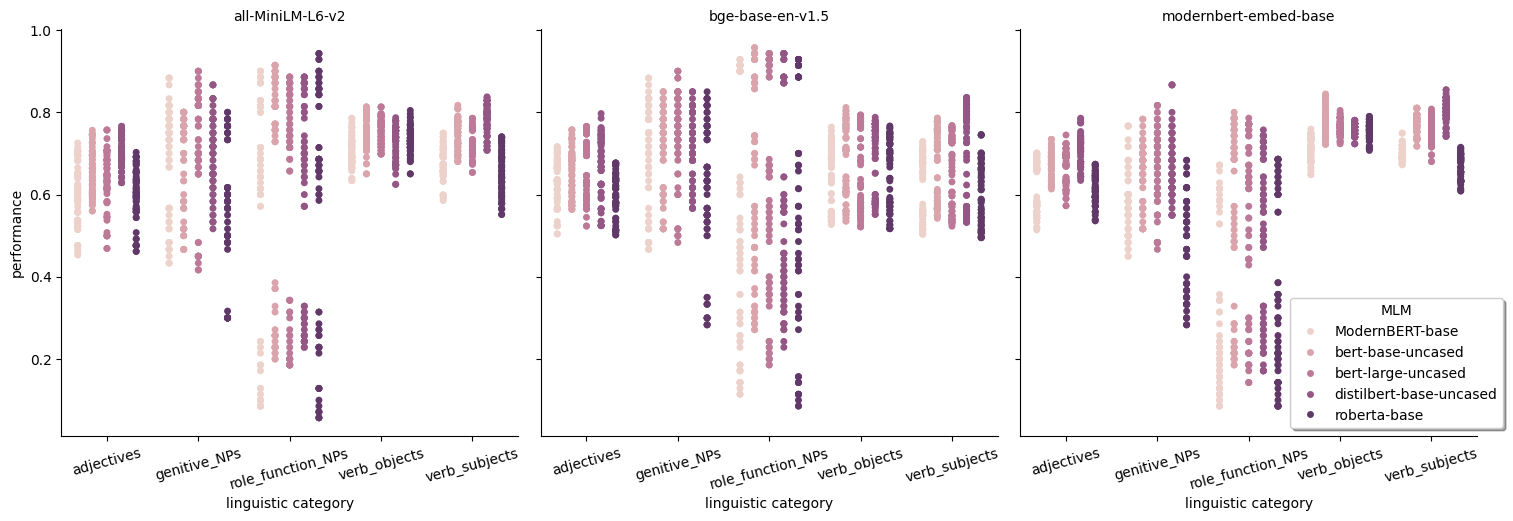

In [ ]:
with sns.cubehelix_palette():
  g = sns.catplot(scores_per_experiment, x="ling_category", y="performance", hue="mlm", col="emb", dodge=True, jitter=False, legend_out=False)
  g.set_xticklabels(rotation=15)
  g.set_xlabels("linguistic category")
  g.set_titles("{col_name}")
  g.legend.set_title("MLM")
  sns.move_legend(g, loc='lower right', bbox_to_anchor=(0.51, 0.12, 0.5, 0.5), shadow=True)
  #plt.savefig("performance_overview.pdf", bbox_inches="tight")

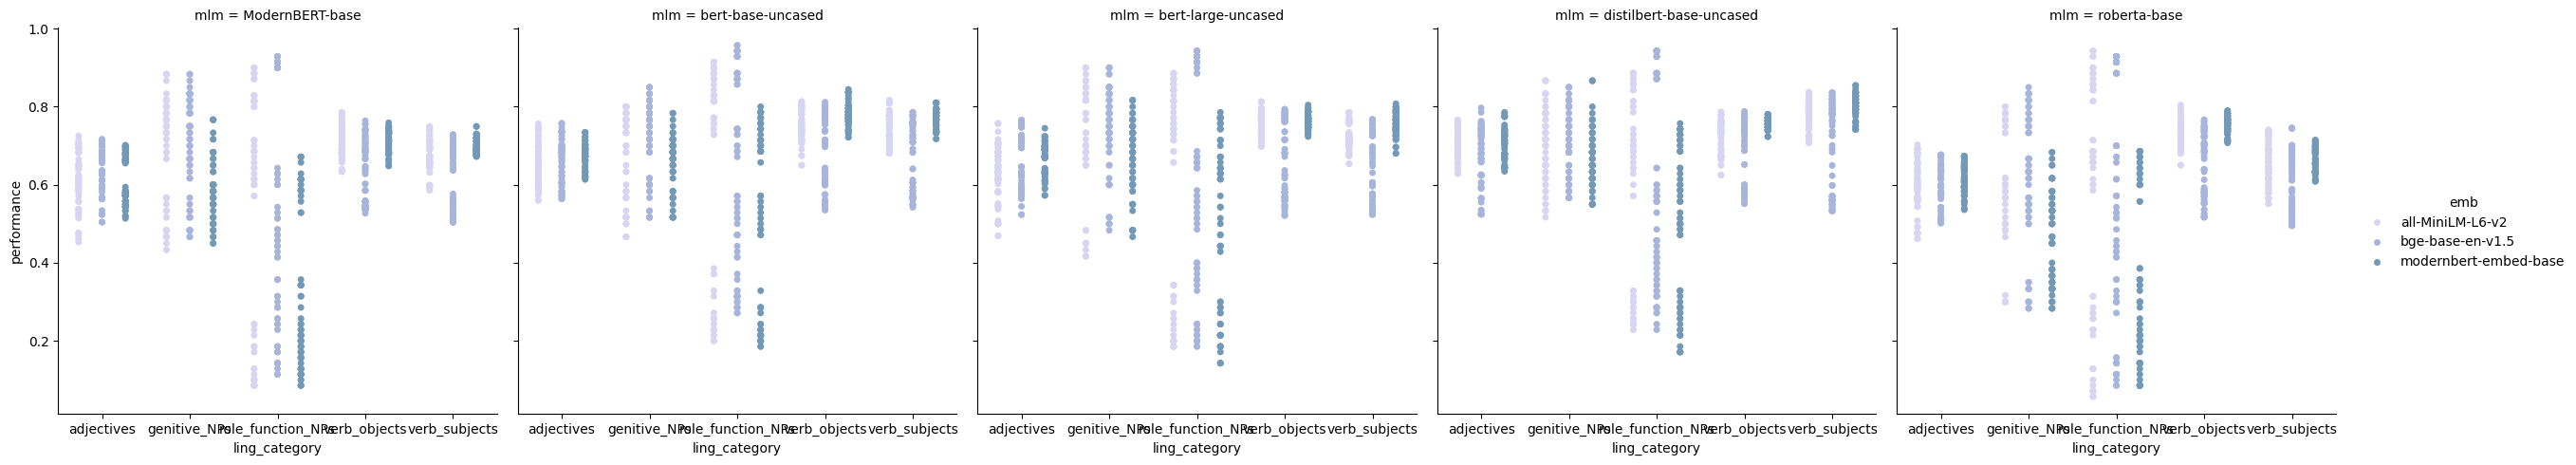

In [ ]:
with sns.cubehelix_palette(start=5):
  sns.catplot(scores_per_experiment, x="ling_category", y="performance", hue="emb", col="mlm", dodge=True, jitter=False)

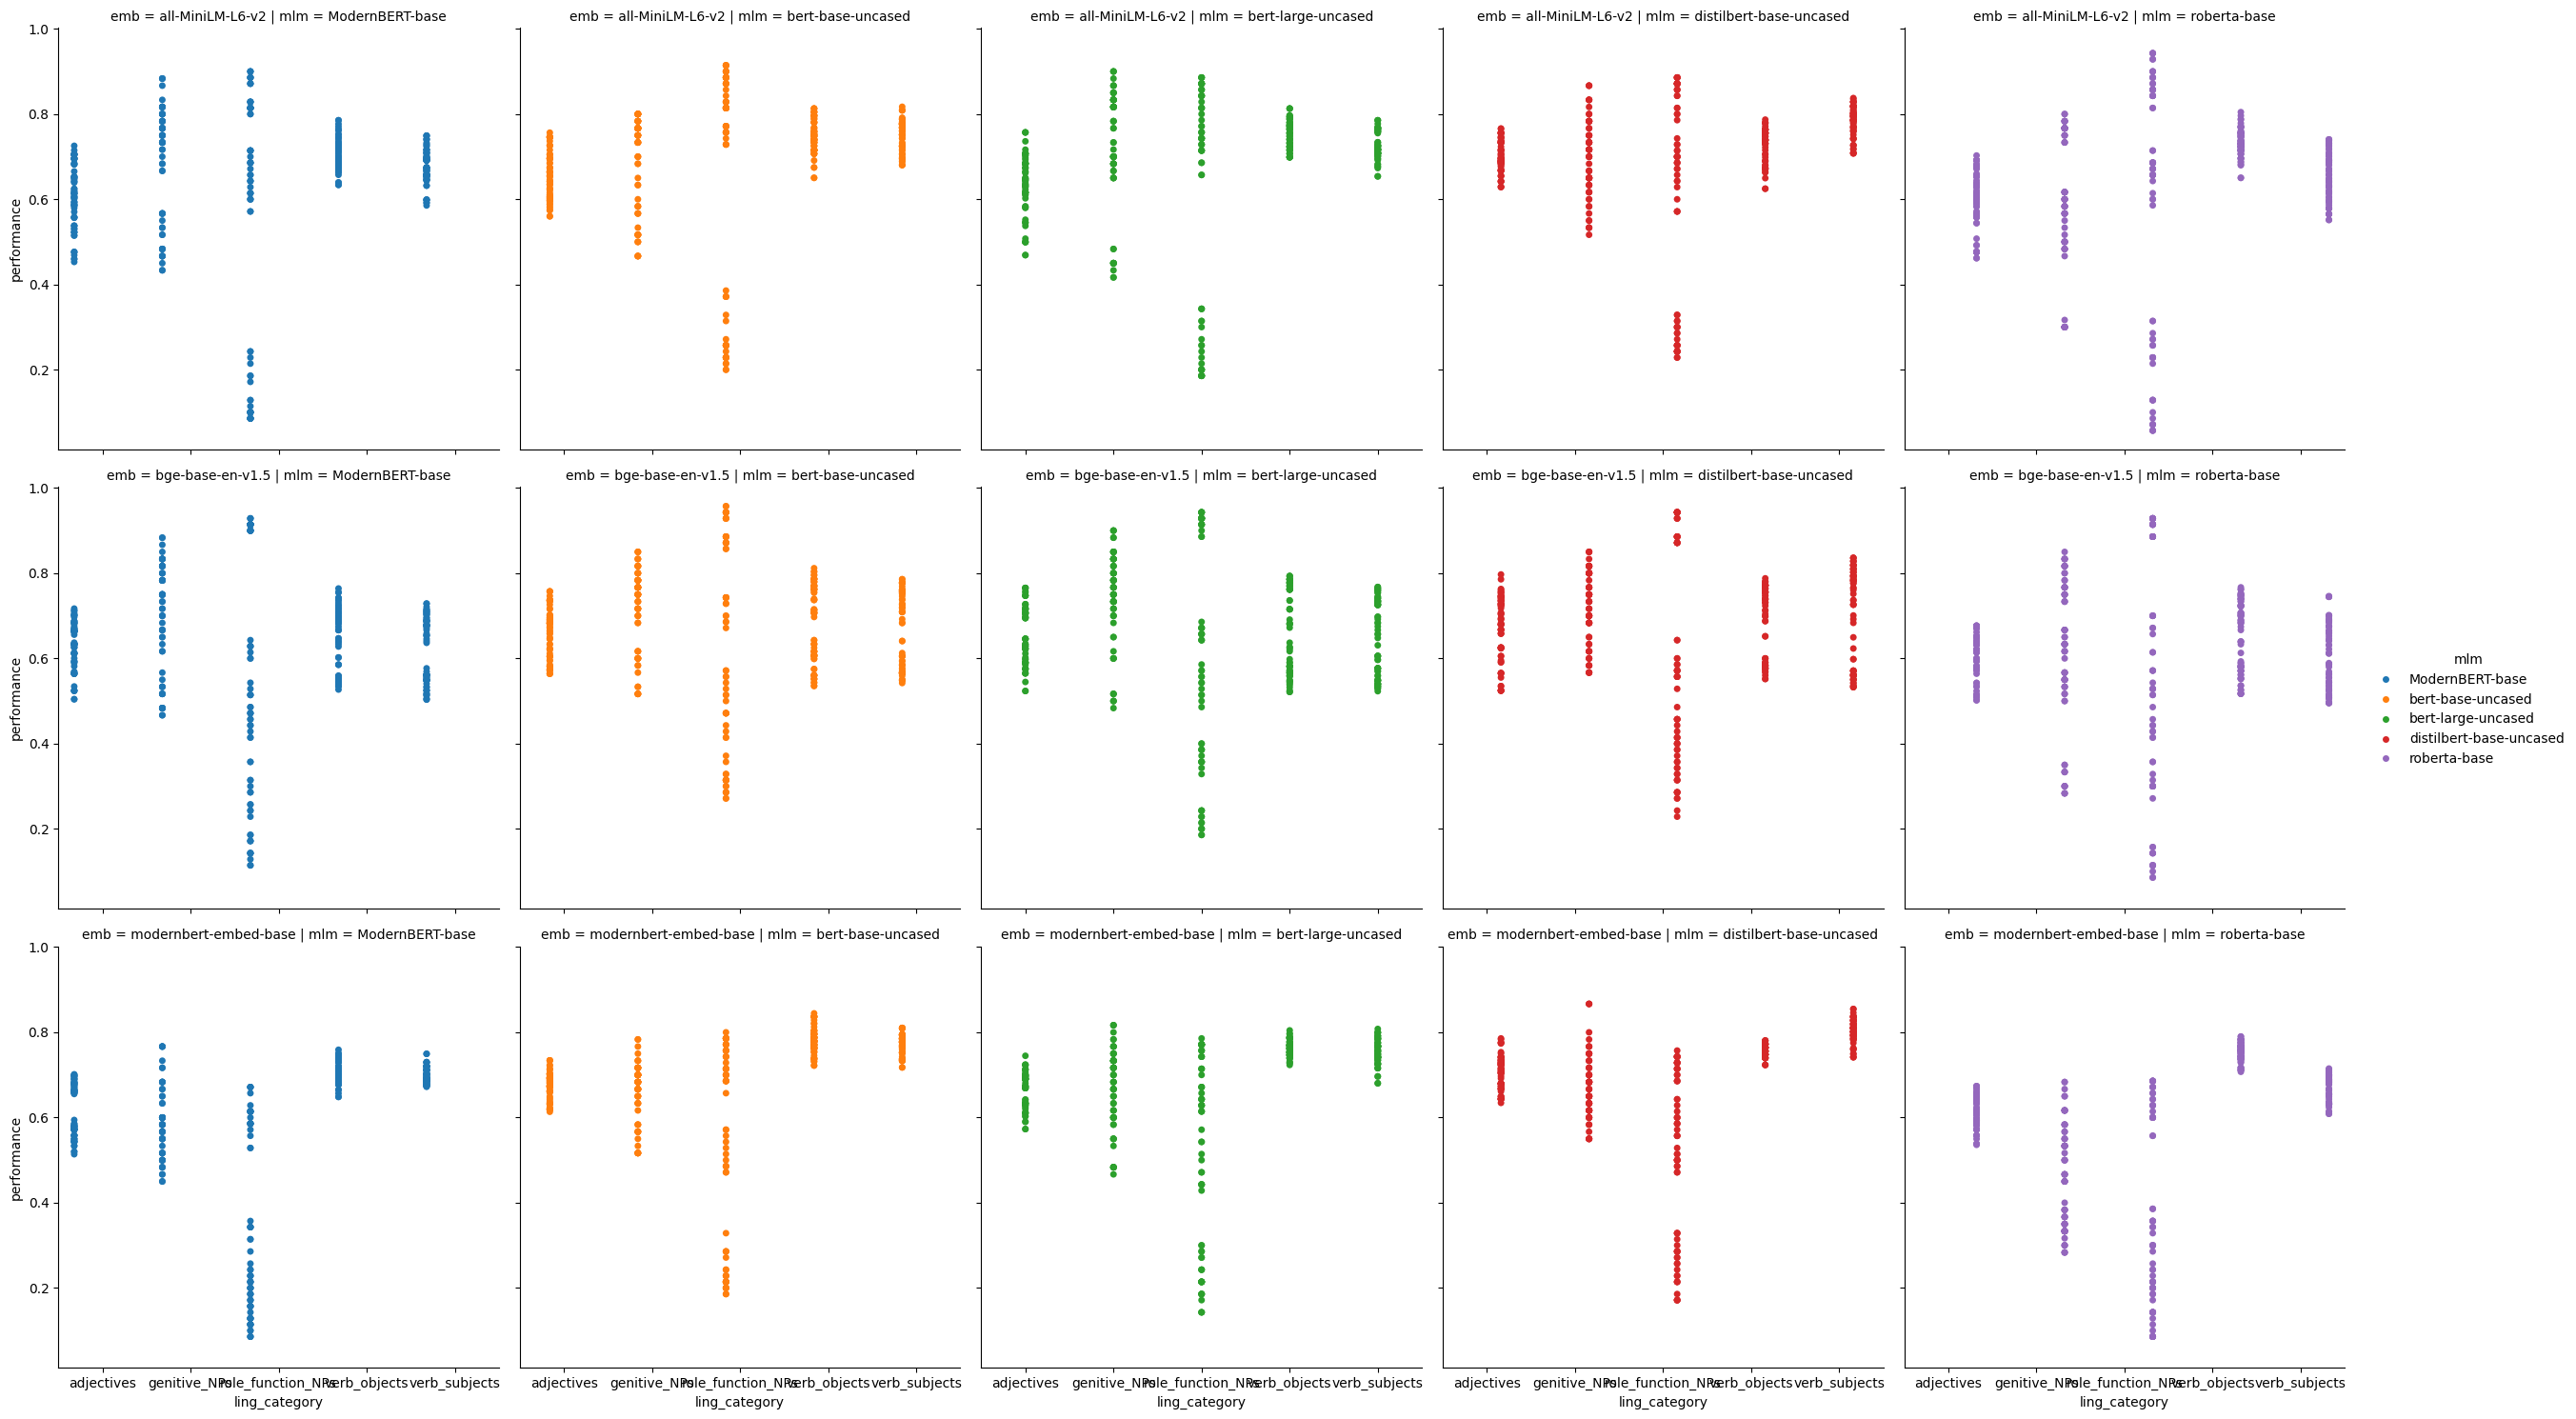

In [ ]:
sns.catplot(scores_per_experiment, x="ling_category", y="performance", hue="mlm", col="mlm", row="emb", dodge=True, jitter=False)

The above stripplots show what boxplots don't: in the role_function_NPs category, the results are clearly split between very good and very bad, rather than being centered around the mean. This is especially true for the bge-base-en-v1.5 model, which obtains the highest scores in that category with a small set of parameters.

The next most spread category is genitive_NPs, whereas the remaining categories adjectives, verb_objects, and verb_subjects have less variance in scores, though different parameters do have an effect in these categories as well.

## The effect of context parameters

In [ ]:
cont_emb_map = {0: "static", "contextual": "contextual", 2: "template"}
long_cont_map = {0: "short", 1: "long"}

In [ ]:
scores_per_experiment["context"] = (scores_per_experiment["cont_emb"].replace(cont_emb_map)+ " + " + scores_per_experiment["long_cont"].replace(long_cont_map)).astype("category")

Overall effect of context parameters, all models together

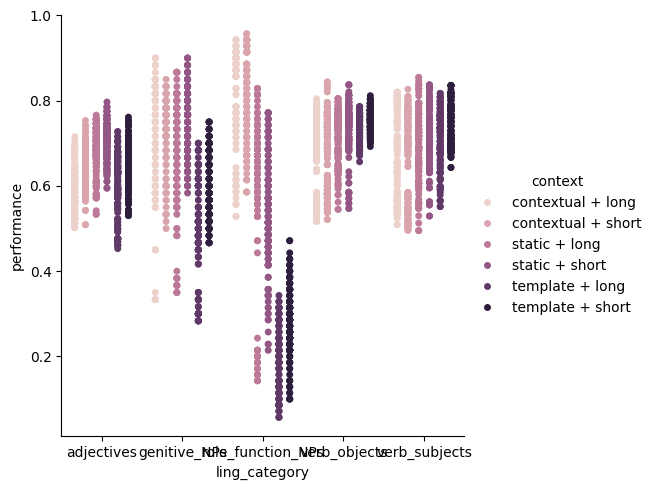

In [ ]:
with sns.cubehelix_palette():
  sns.catplot(scores_per_experiment, x="ling_category", y="performance", hue="context", dodge=True, jitter=False)

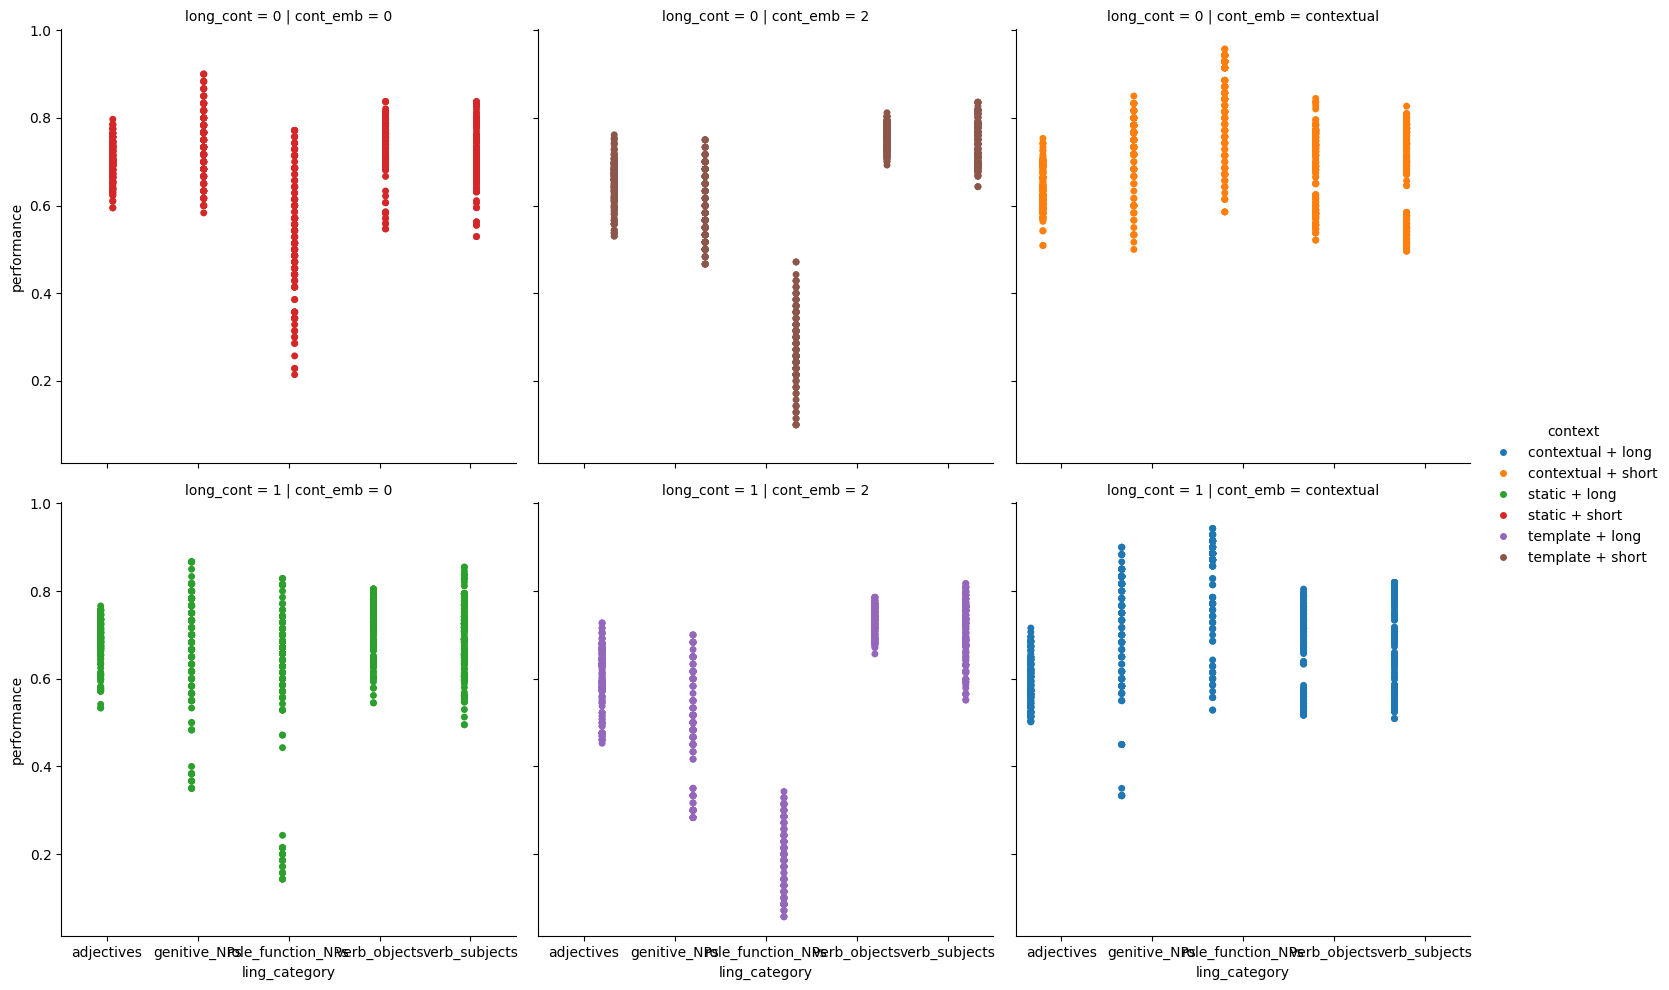

In [ ]:
sns.catplot(scores_per_experiment, x="ling_category", y="performance", hue="context", dodge=True, jitter=False, col="cont_emb", row="long_cont")

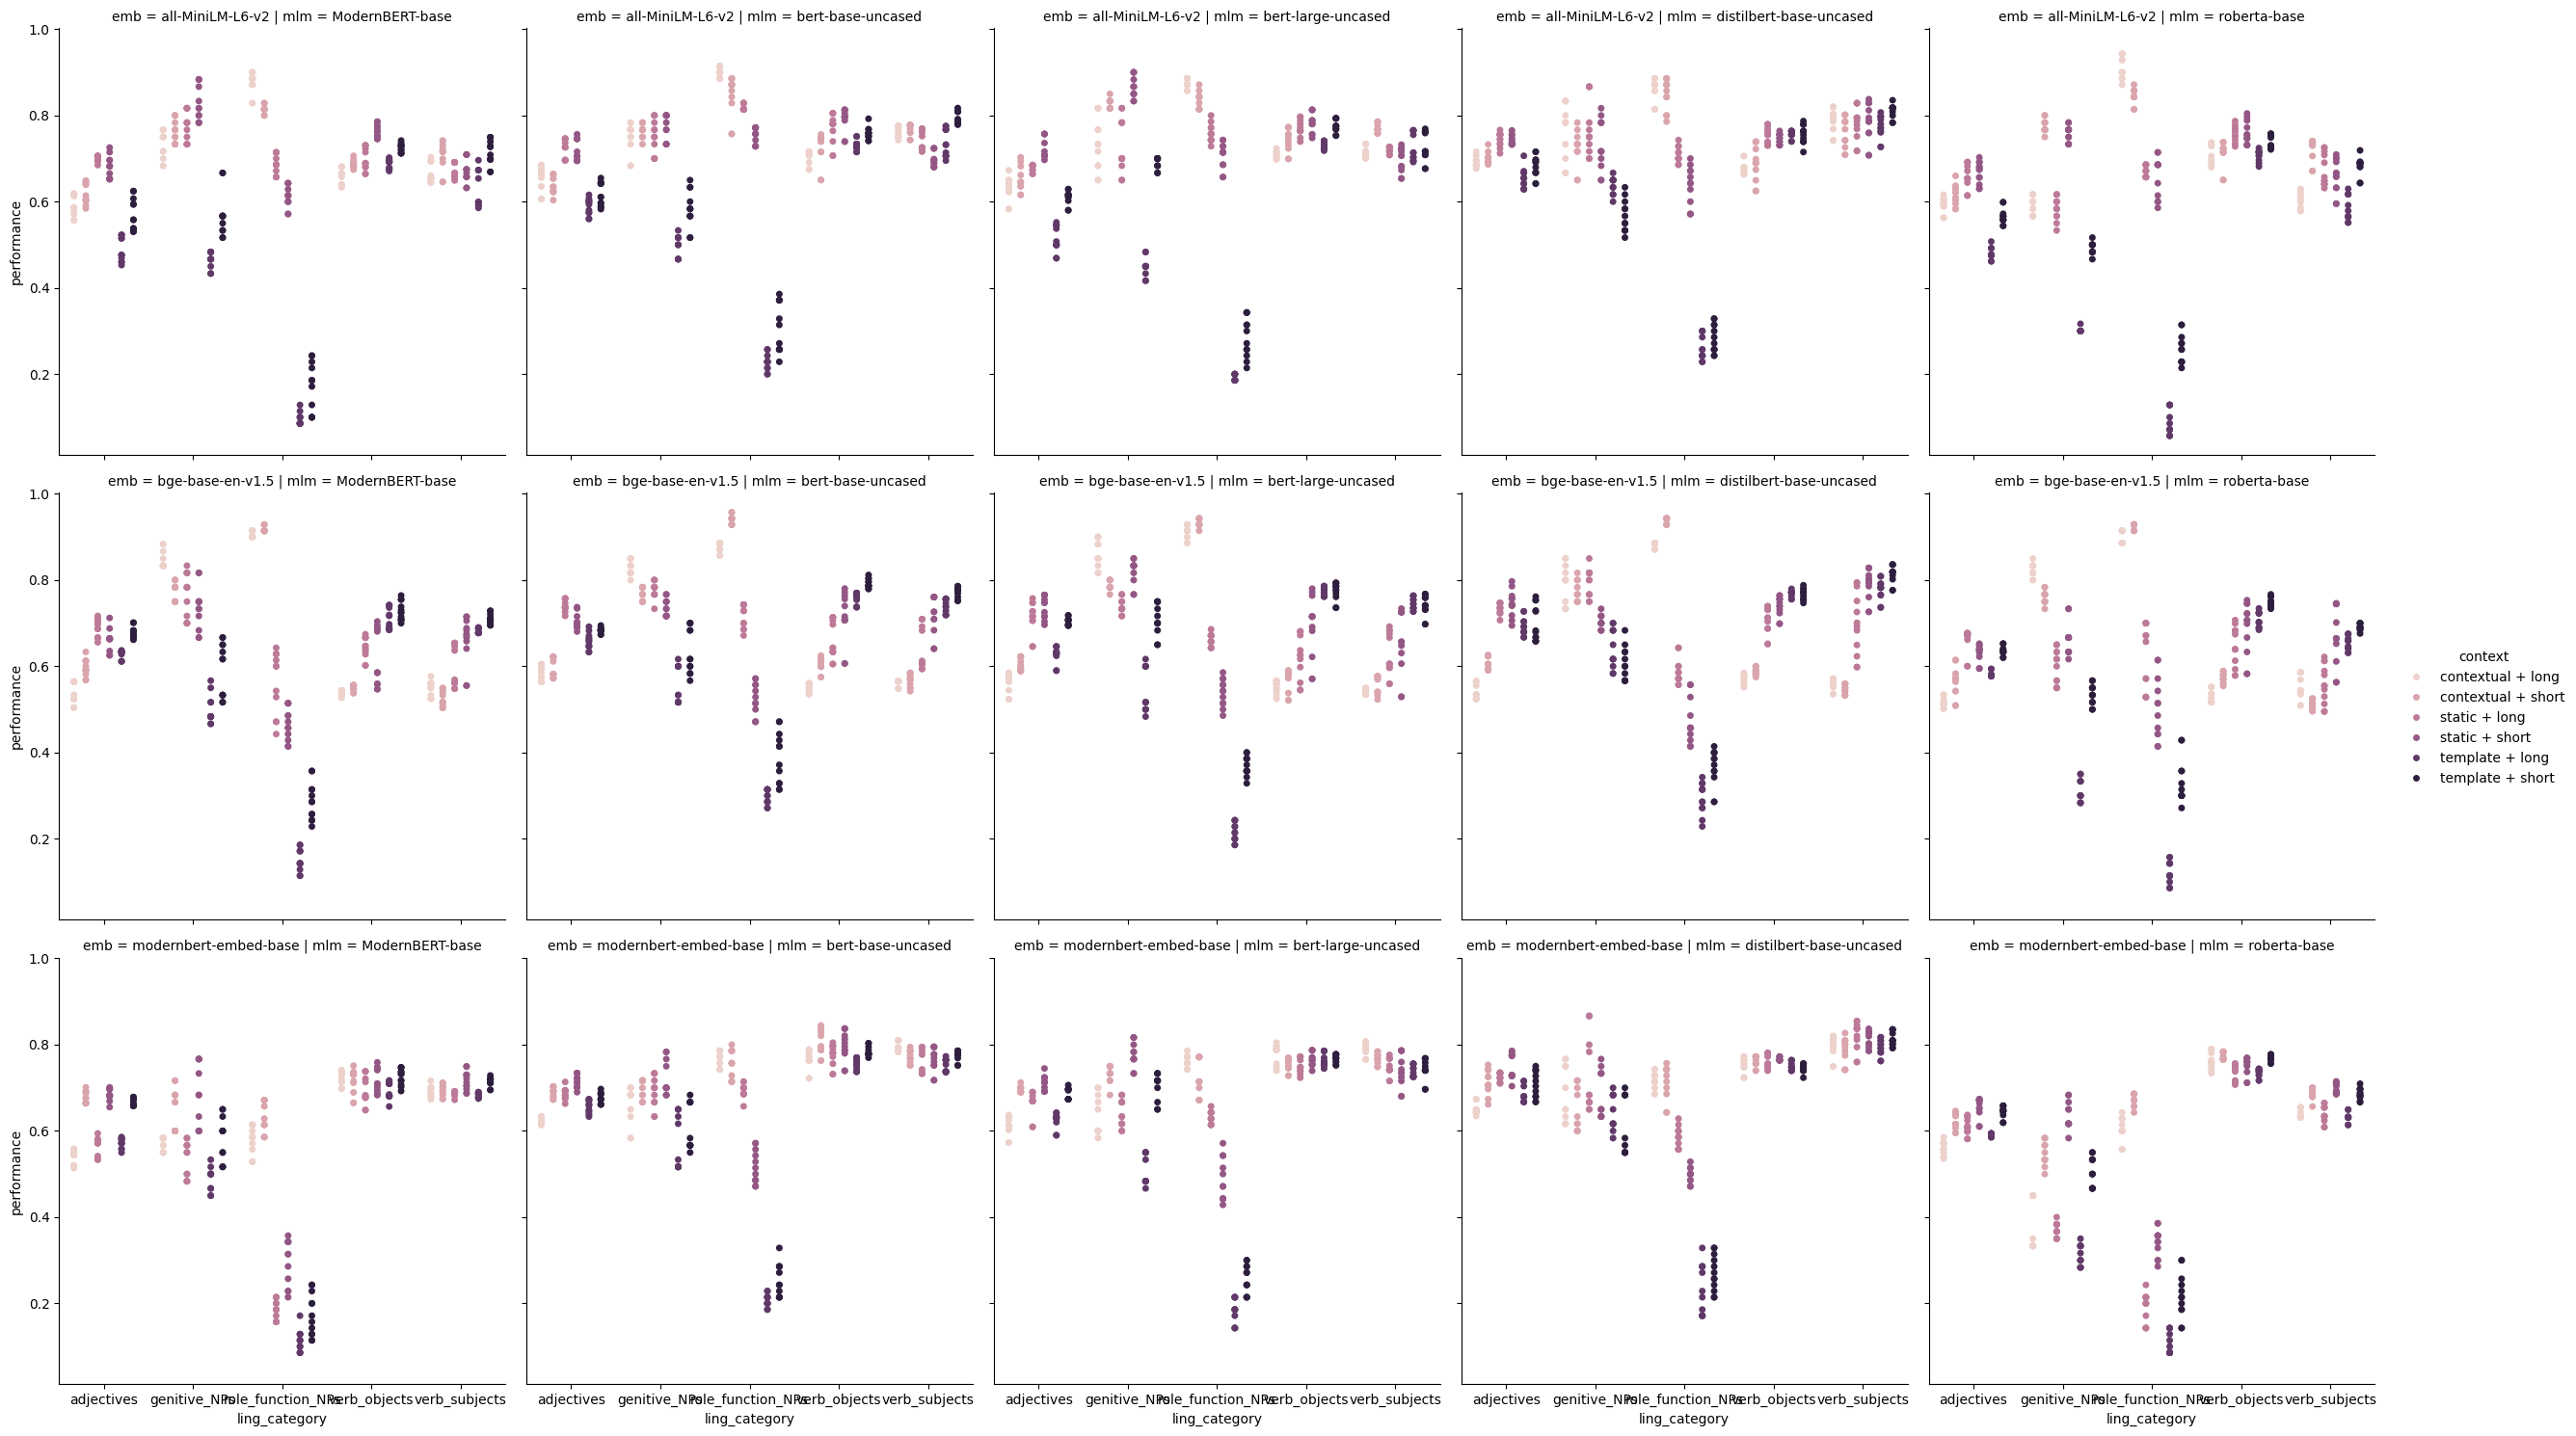

In [ ]:
with sns.cubehelix_palette():
  sns.catplot(scores_per_experiment, x="ling_category", y="performance", hue="context", dodge=True, jitter=False, col="mlm", row="emb")

Models seem to be affected largely in similar ways by different contextual parameters. The setting yielding best results on average is contextual embeddings with short context. (That, however, might be driven by the high scores in the category role_function_NPs.) As a rule of thumb, contextual embeddings seem to be the only reasonable approach for the category role_function_NPs. Using static or template approach in that category yields worse than chance results. For some models, the template approach improves the results in the categories verb_objects and verb_subjects, whereas the best performance in adjectives category is obtained with static embeddings.

In [ ]:
scores_per_experiment.groupby("context", observed=True)["performance"].agg(["min", "max", "mean", "std"]).sort_values("mean", ascending=False).style.background_gradient()

,min,max,mean,std
context,,,,
contextual + short,0.495989,0.957143,0.711763,0.105662
contextual + long,0.333333,0.942857,0.692052,0.124747
static + short,0.214286,0.900000,0.686738,0.110420
static + long,0.142857,0.866667,0.677114,0.114998
template + short,0.100000,0.835880,0.607828,0.183325
template + long,0.057143,0.817092,0.545938,0.212926


In [ ]:
scores_per_experiment.groupby(["context", "ling_category"], observed=True)["performance"].agg(["min", "max", "mean", "std"]).sort_values("mean", ascending=False).style.background_gradient()

In [ ]:
average_per_experiment["context"] = (average_per_experiment["cont_emb"].replace(cont_emb_map)+ " + " + average_per_experiment["long_cont"].replace(long_cont_map)).astype("category")

In [ ]:
average_per_experiment["models"] = (average_per_experiment["mlm"].astype(str) + " + " + average_per_experiment["emb"].astype(str)).astype("category")

In [ ]:
average_per_experiment.groupby("context", observed=True)["performance"].agg(["min", "max", "mean", "std"]).sort_values("mean", ascending=False).style.background_gradient()

,min,max,mean,std
context,,,,
contextual + short,0.649669,0.789773,0.711763,0.036679
contextual + long,0.564274,0.780659,0.692052,0.047467
static + short,0.583938,0.782232,0.686738,0.047623
static + long,0.493722,0.789213,0.677114,0.073309
template + short,0.511495,0.676187,0.607828,0.037960
template + long,0.423195,0.655312,0.545938,0.062047


Group static + short average: 0.6867380256955368
Group static + long average: 0.6771144833952678
Group template + short average: 0.6078281115548378
Group template + long average: 0.5459384315244623
Group contextual + short average: 0.7117633955318982
Group contextual + long average: 0.6920516100905989


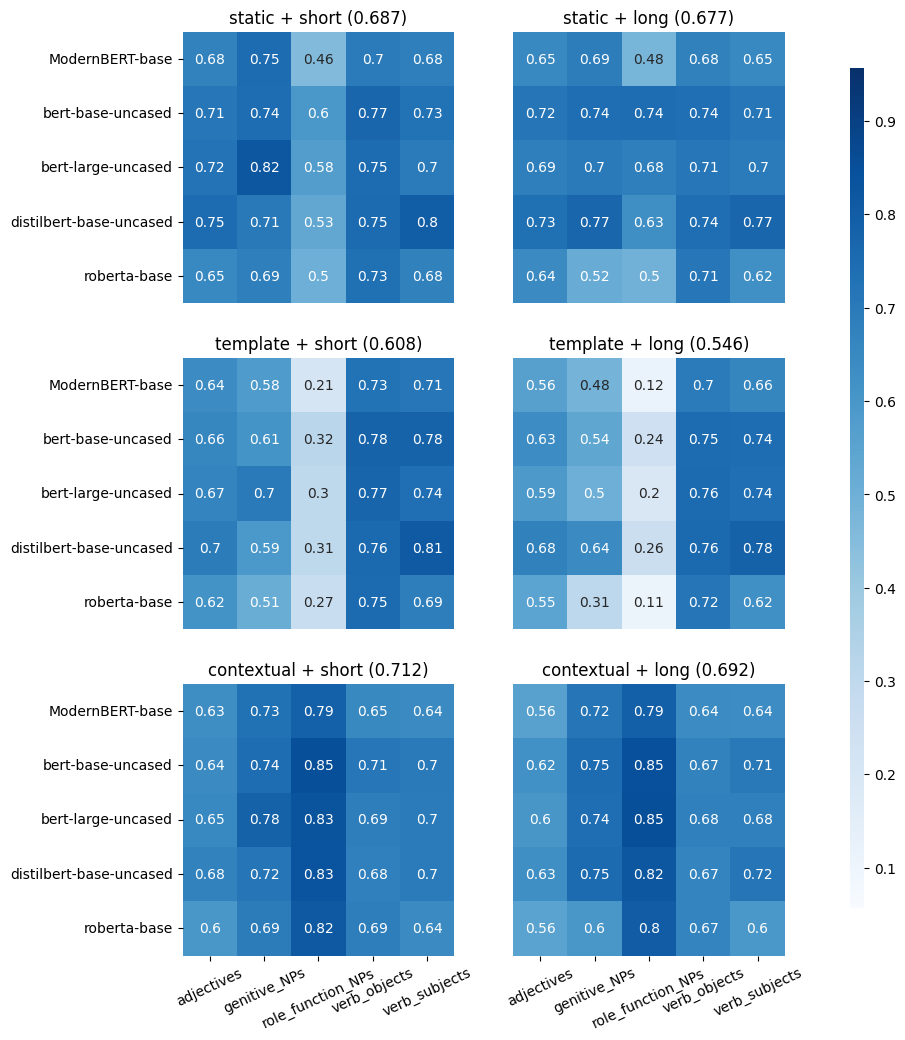

In [ ]:
fig, axes = plt.subplots(3,2, figsize=(9,12))
fig.subplots_adjust(wspace=-0.1)
axes = axes.flatten()
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # separate colorbar axis
#fig.subplots_adjust(wspace=0, right=0.93)  # leave room for colorbar

vmin = scores_per_experiment["performance"].min()
vmax = scores_per_experiment["performance"].max()
for i, (ax, context) in enumerate(zip(axes, scores_per_experiment.context.unique())):

  heatmap_data = (
      scores_per_experiment[(scores_per_experiment["context"] == context)]
      .groupby(["mlm", "ling_category"], observed=True)["performance"]
      .mean()
      .unstack("ling_category")
  )
  group_average = heatmap_data.mean(axis=None)
  print(f"Group {context} average: {group_average}")
  sns.heatmap(heatmap_data, cmap="Blues", ax=ax, vmin=vmin, vmax=vmax, square=True, annot=True,
              cbar=(i == scores_per_experiment.context.nunique()-1), cbar_ax=cbar_ax if (i == scores_per_experiment.context.nunique()-1) else None,
              )
  ax.set_title(f"{context} ({group_average:.3f})")
  axes[i].tick_params(axis="x", rotation=25)
  if i % 2 != 0:
    ax.set_yticks([])
    ax.set_ylabel("")
    ax.set_yticklabels([])

  if i not in (4, 5):
    ax.set_xticks([])
    ax.set_xlabel("")
    ax.set_xticklabels([])
  ax.set_xlabel("")
  ax.set_ylabel("")
#fig.supxlabel("Linguistic categories")
#plt.suptitle("Effect of context")
#plt.savefig("context_heatmap.pdf")
plt.show()

Below is the same plot, but with "hard" scores removed, as they are consistently lower (see a later section in this Notebook).

In [ ]:
scores_no_log = scores_per_experiment[scores_per_experiment["scoring_method"] == "soft"].copy()

Group static + short average: 0.6976623446637739
Group static + long average: 0.6859815924604302
Group template + short average: 0.6146208757894585
Group template + long average: 0.5540034762646955
Group contextual + short average: 0.7173244259843744
Group contextual + long average: 0.7006048973581218


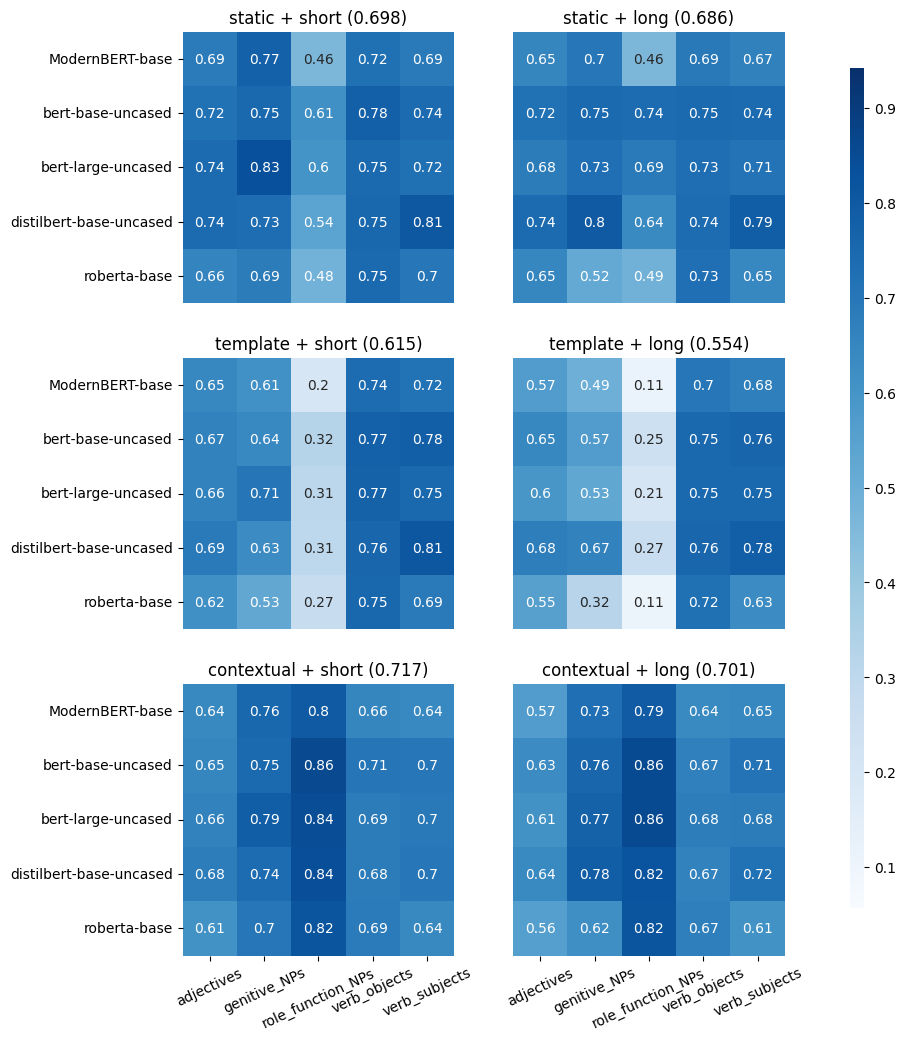

In [ ]:
fig, axes = plt.subplots(3,2, figsize=(9,12))
fig.subplots_adjust(wspace=-0.1)
axes = axes.flatten()
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # separate colorbar axis
#fig.subplots_adjust(wspace=0, right=0.93)  # leave room for colorbar

vmin = scores_no_log["performance"].min()
vmax = scores_no_log["performance"].max()
for i, (ax, context) in enumerate(zip(axes, scores_no_log.context.unique())):

  heatmap_data = (
      scores_no_log[(scores_no_log["context"] == context)]
      .groupby(["mlm", "ling_category"], observed=True)["performance"]
      .mean()
      .unstack("ling_category")
  )
  group_average = heatmap_data.mean(axis=None)
  print(f"Group {context} average: {group_average}")
  sns.heatmap(heatmap_data, cmap="Blues", ax=ax, vmin=vmin, vmax=vmax, square=True, annot=True,
              cbar=(i == scores_no_log.context.nunique()-1), cbar_ax=cbar_ax if (i == scores_per_experiment.context.nunique()-1) else None,
              )
  ax.set_title(f"{context} ({group_average:.3f})")
  axes[i].tick_params(axis="x", rotation=25)
  if i % 2 != 0:
    ax.set_yticks([])
    ax.set_ylabel("")
    ax.set_yticklabels([])

  if i not in (4, 5):
    ax.set_xticks([])
    ax.set_xlabel("")
    ax.set_xticklabels([])
  ax.set_xlabel("")
  ax.set_ylabel("")
#fig.supxlabel("Linguistic categories")
#plt.suptitle("Effect of context")
plt.savefig("context_heatmap_fixed.pdf")
plt.show()

## Effect of top-k

In [ ]:
topk_values = average_per_experiment.topk.unique()

In [ ]:
average_per_experiment.groupby("topk", observed=True)["performance"].agg(["min", "max", "mean", "std"]).sort_values("mean", ascending=False).style.background_gradient()

,min,max,mean,std
topk,,,,
50,0.425963,0.789213,0.658095,0.081765
10,0.423195,0.780659,0.657150,0.077506
100,0.423894,0.786603,0.656964,0.083117
150,0.423894,0.789773,0.656539,0.083565
5,0.436175,0.771533,0.654984,0.073659
1,0.431329,0.740884,0.637702,0.067261


<Axes: xlabel='topk'>

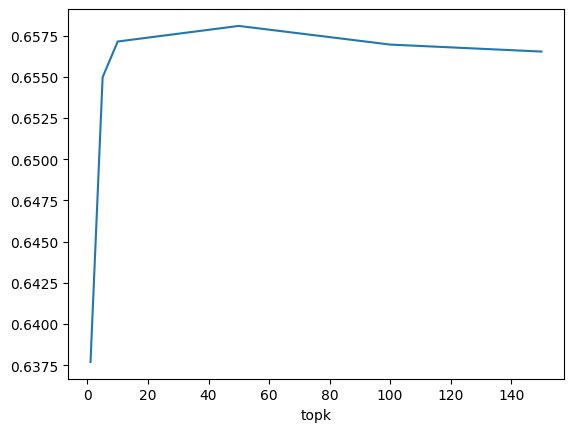

In [ ]:
average_per_experiment.groupby("topk", observed=True)["performance"].mean().plot()

In [ ]:
def plot_topk_effect(df, groupby_var, figsize=(6,6), save=False):
  fig, ax = plt.subplots(figsize=figsize)
  df.groupby(["topk", groupby_var], observed=True)["performance"].mean().unstack(groupby_var).plot(ax=ax)
  for k in topk_values:
    ax.axvline(x=k, color="gray", linestyle="--")
  ax.set_xticks(topk_values)
  ax.set_xticklabels(topk_values)
  df.groupby("topk", observed=True)["performance"].mean().rename("mean").plot(ax=ax, linestyle=(5, (10, 3)), color="black")
  ax.legend(loc="upper left", bbox_to_anchor=(1.01, 0.8))
  ax.set_xlabel("Top-k")
  plt.tight_layout()
  if save:
    plt.savefig("topk_effect.pdf")
  plt.show()

In [ ]:
title_mapping = {
    "mlm": "Masked Language Model",
    "emb": "Embedding Model",
    "context": "Context",
    "scoring_method": "Scoring method"
}

def plot_topk_effect(df, groupby_var, ax):
  df.groupby(["topk", groupby_var], observed=True)["performance"].mean().unstack(groupby_var).plot(ax=ax)
  for k in topk_values:
    ax.axvline(x=k, color="gray", linestyle="dotted")
  ax.set_xticks(topk_values)
  ax.set_xticklabels(topk_values)
  df.groupby("topk", observed=True)["performance"].mean().rename("mean").plot(ax=ax, linestyle=(5, (10, 3)), color="black")
  ax.legend(loc="lower right") # bbox_to_anchor=(1.01, 0.8)
  ax.set_xlabel("Top-k")
  ax.set_title(title_mapping[groupby_var])


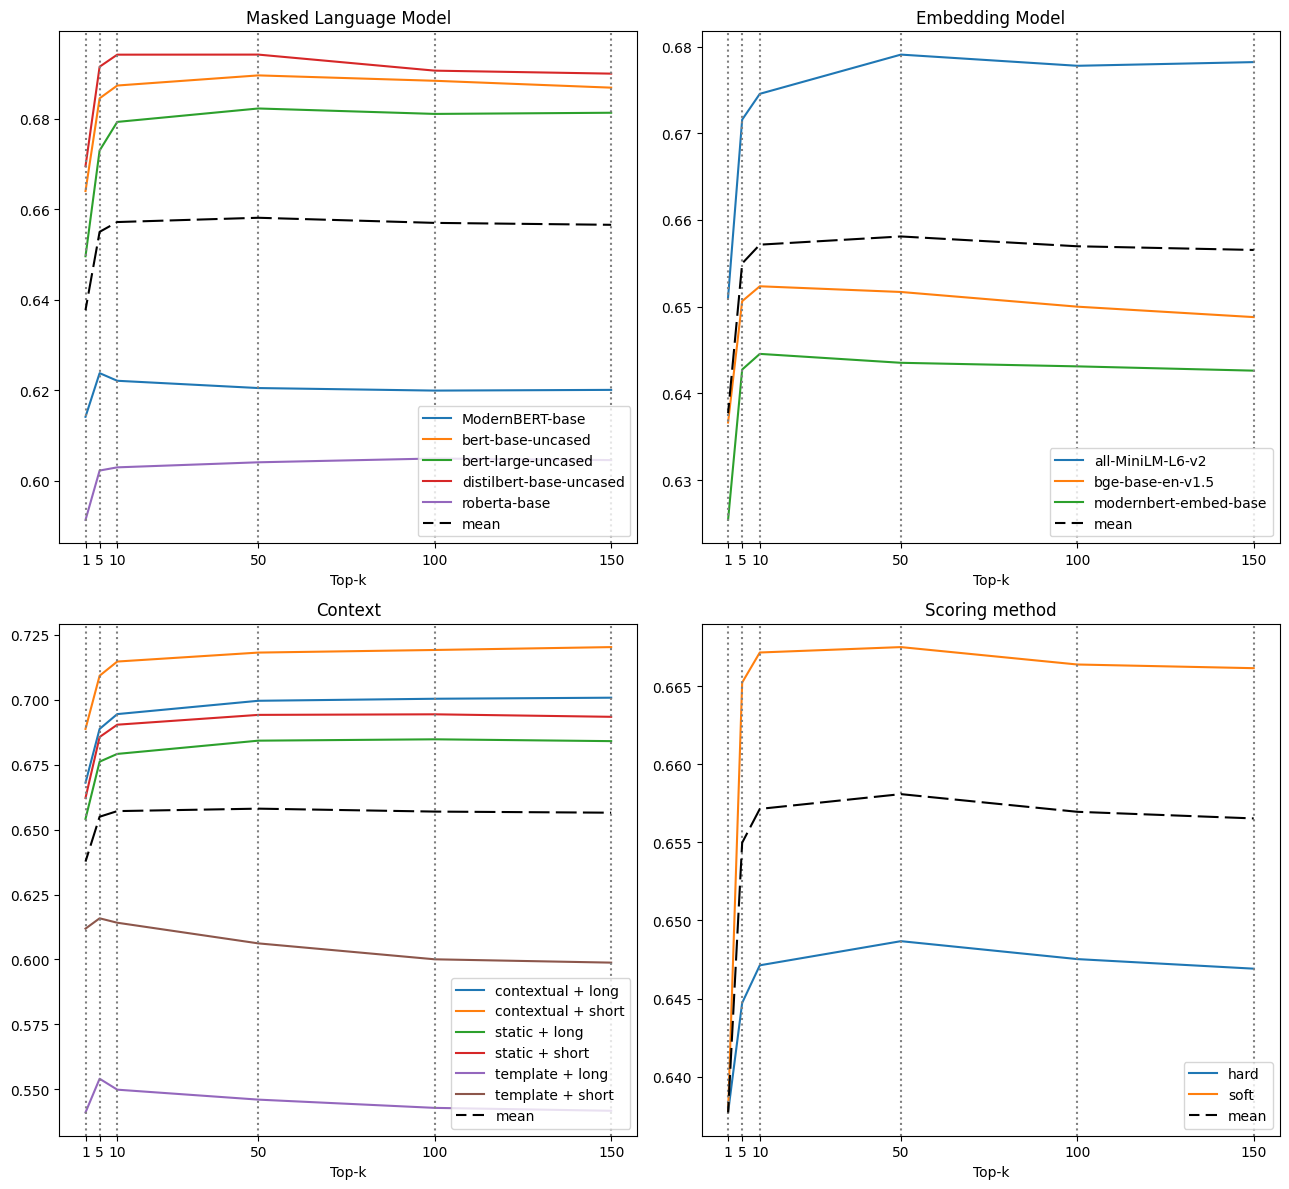

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 12))
axes = axes.flatten()

for i, col in enumerate(("mlm", "emb", "context", "scoring_method")):
  plot_topk_effect(average_per_experiment, col, axes[i])
plt.tight_layout()
plt.savefig("topk_effect.pdf")
plt.show()

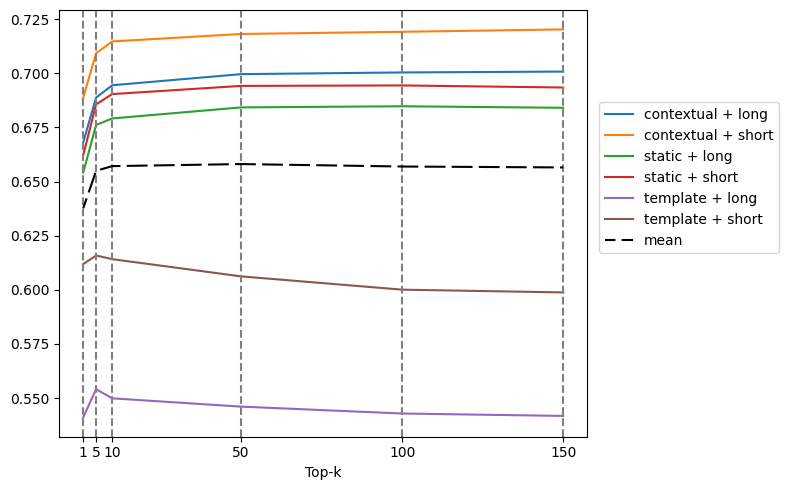

In [ ]:
plot_topk_effect(average_per_experiment, "context", (8, 5), save=True)

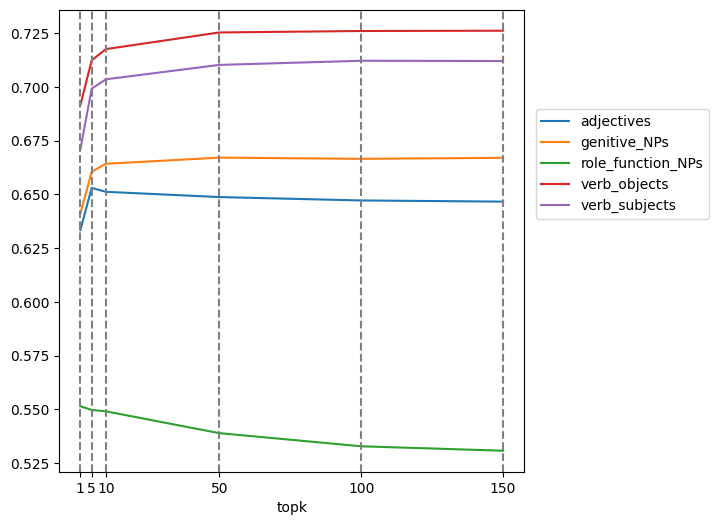

In [ ]:
plot_topk_effect(scores_per_experiment, "ling_category")

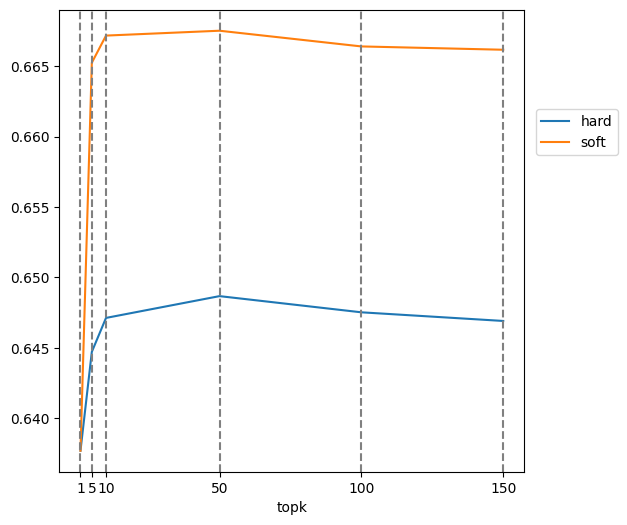

In [ ]:
plot_topk_effect(average_per_experiment, "scoring_method")

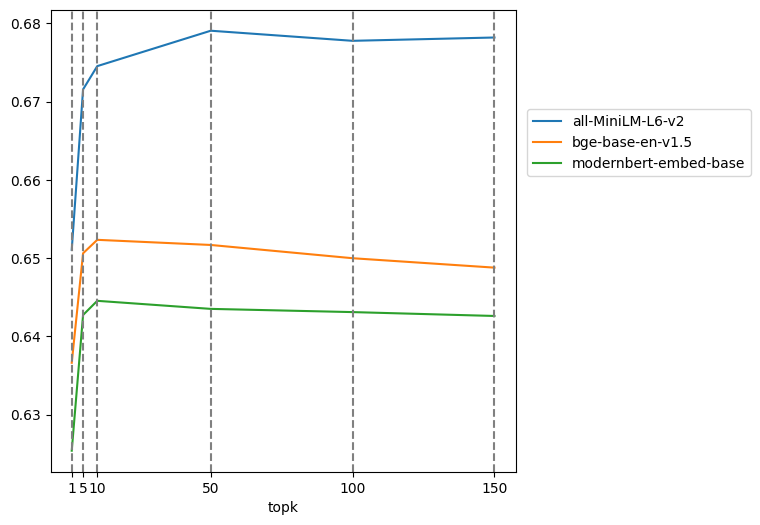

In [ ]:
plot_topk_effect(average_per_experiment, "emb")

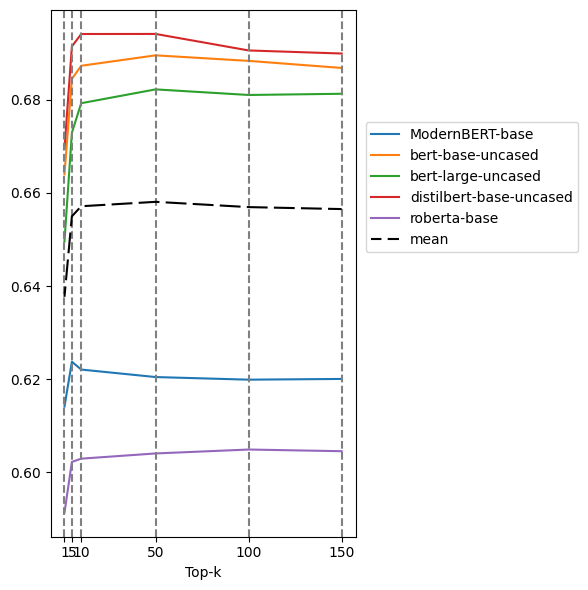

In [ ]:
plot_topk_effect(average_per_experiment, "mlm")

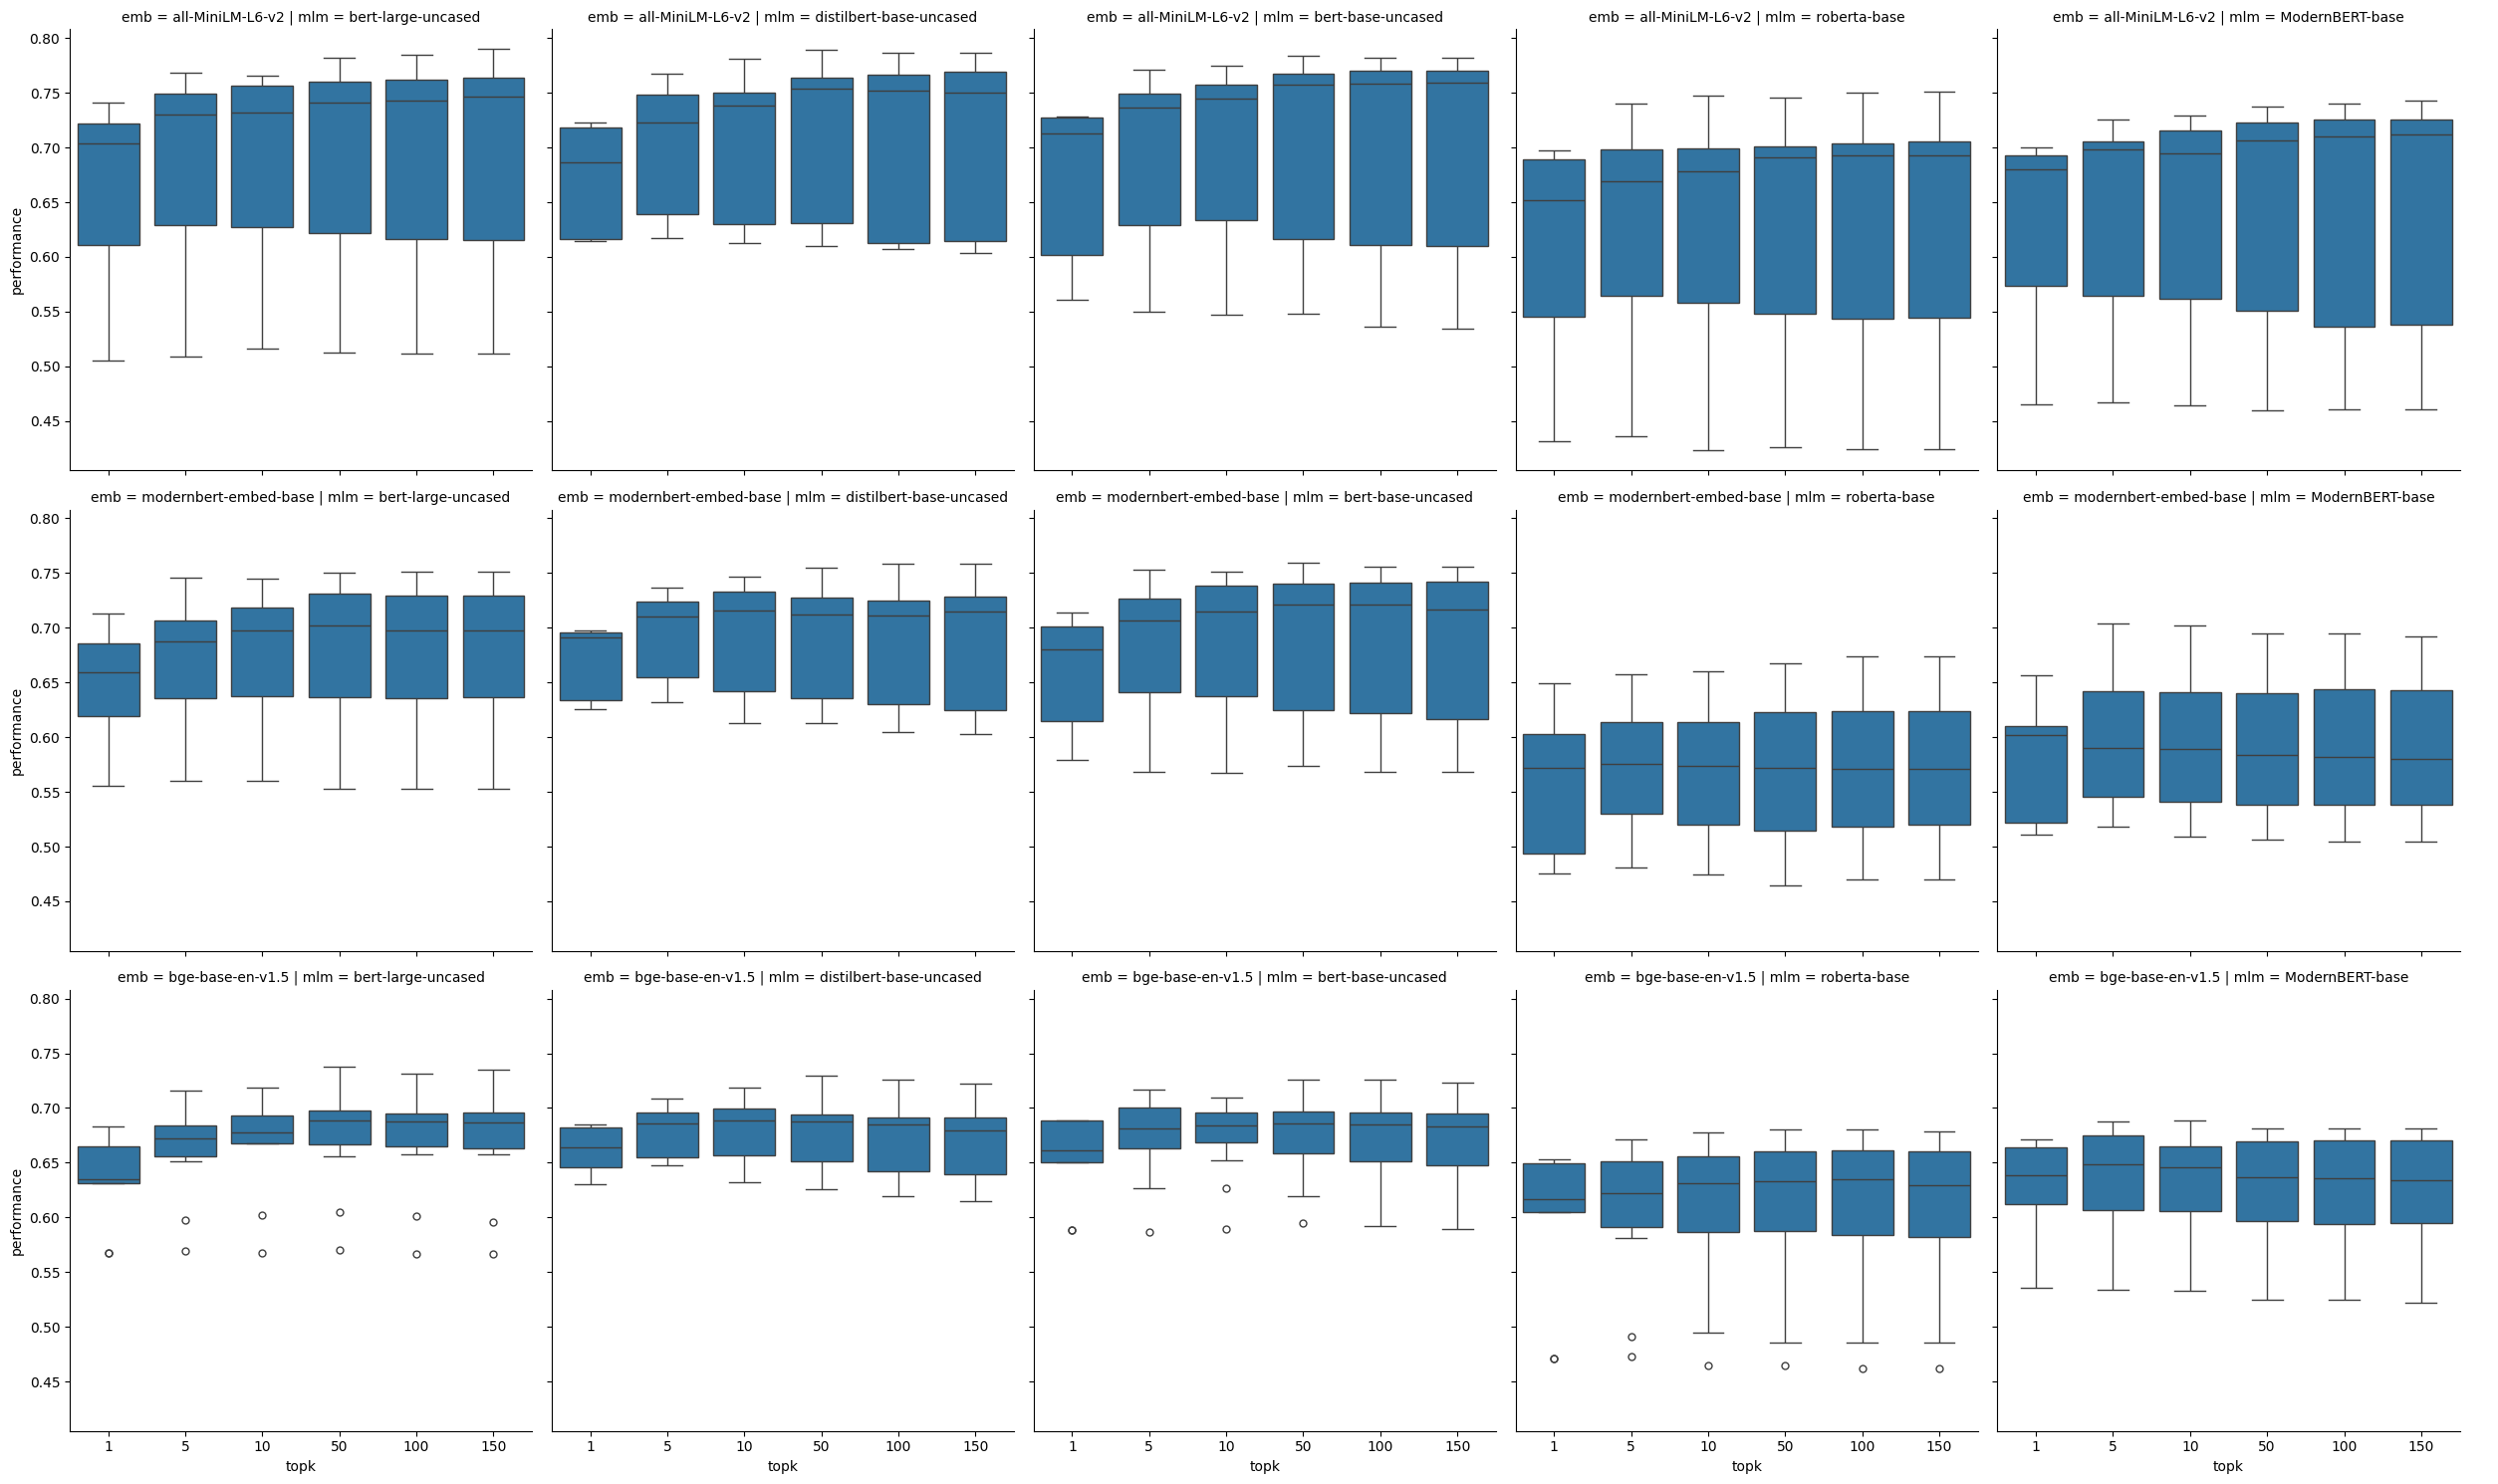

In [ ]:
sns.catplot(average_per_experiment, y="performance", x="topk", kind="box", col="mlm", row="emb")
plt.show()

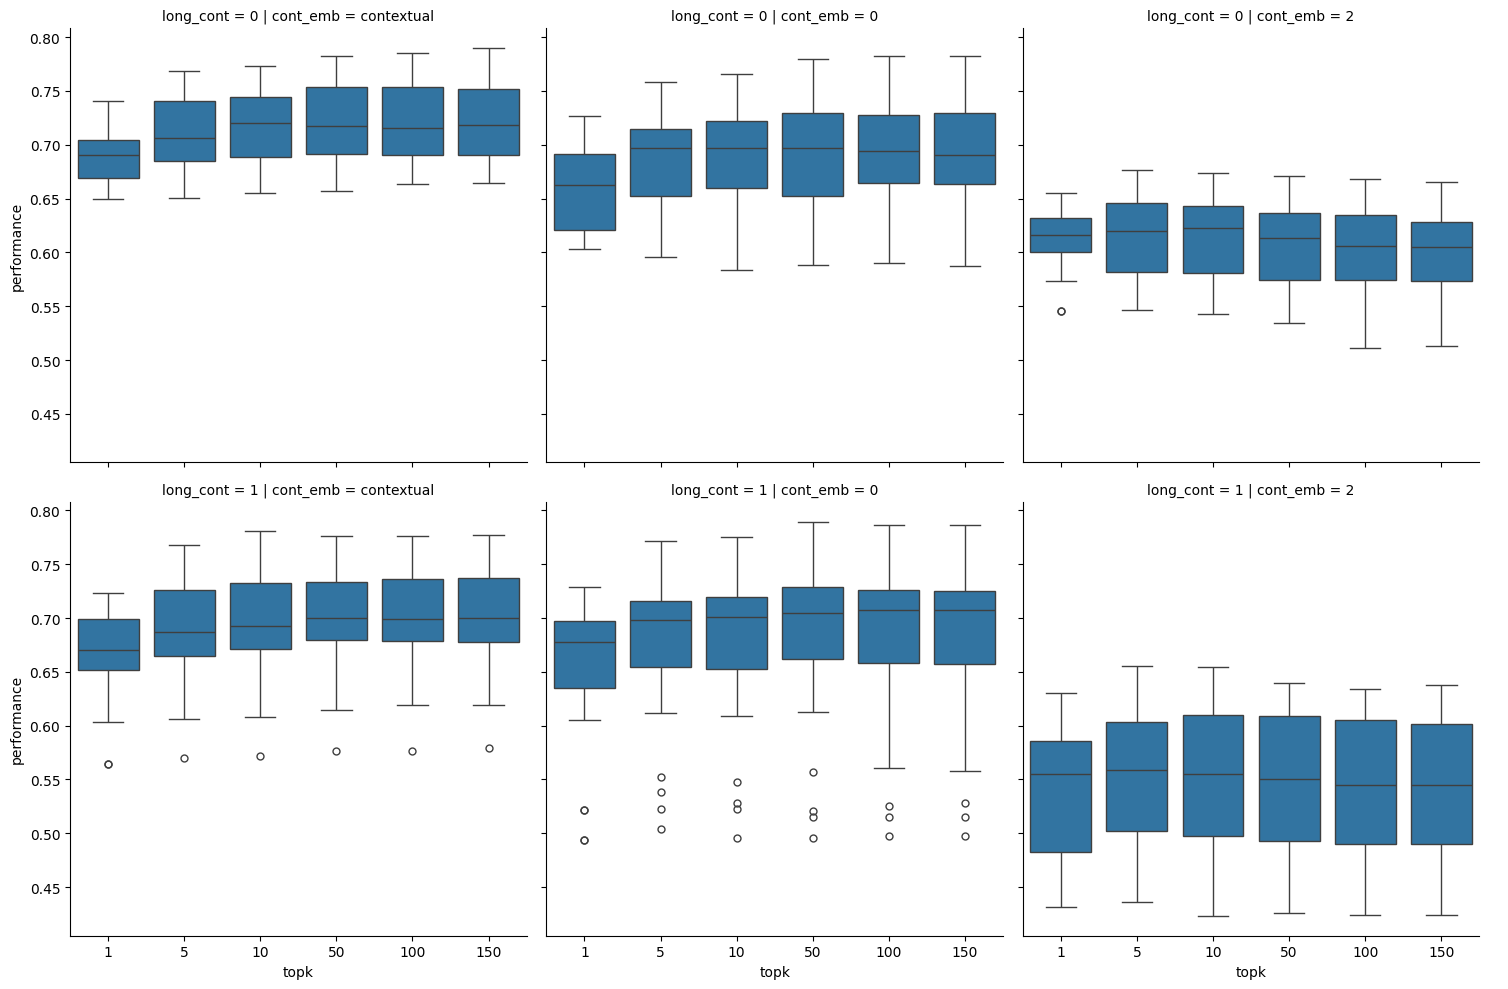

In [ ]:
sns.catplot(average_per_experiment, y="performance", x="topk", kind="box", col="cont_emb", row="long_cont")
plt.show()

## Effect of scoring method

On average, the "soft" scoring method is nearly always a better option than the "hard" scoring method. In some linguistic categories and contexts the difference in the average scores of soft vs hard scoring is smaller than in others.

<Axes: xlabel='ling_category', ylabel='performance'>

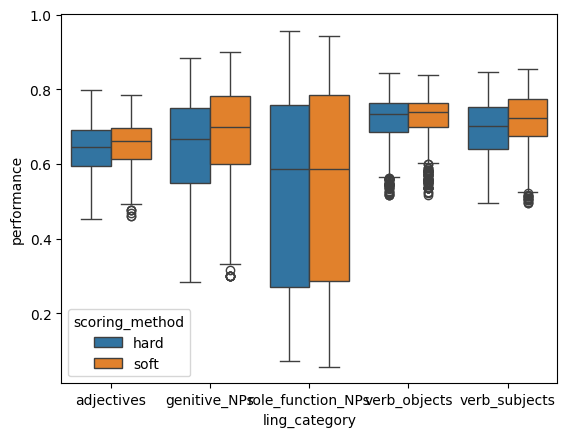

In [ ]:
sns.boxplot(scores_per_experiment, x="ling_category", y="performance", hue="scoring_method")

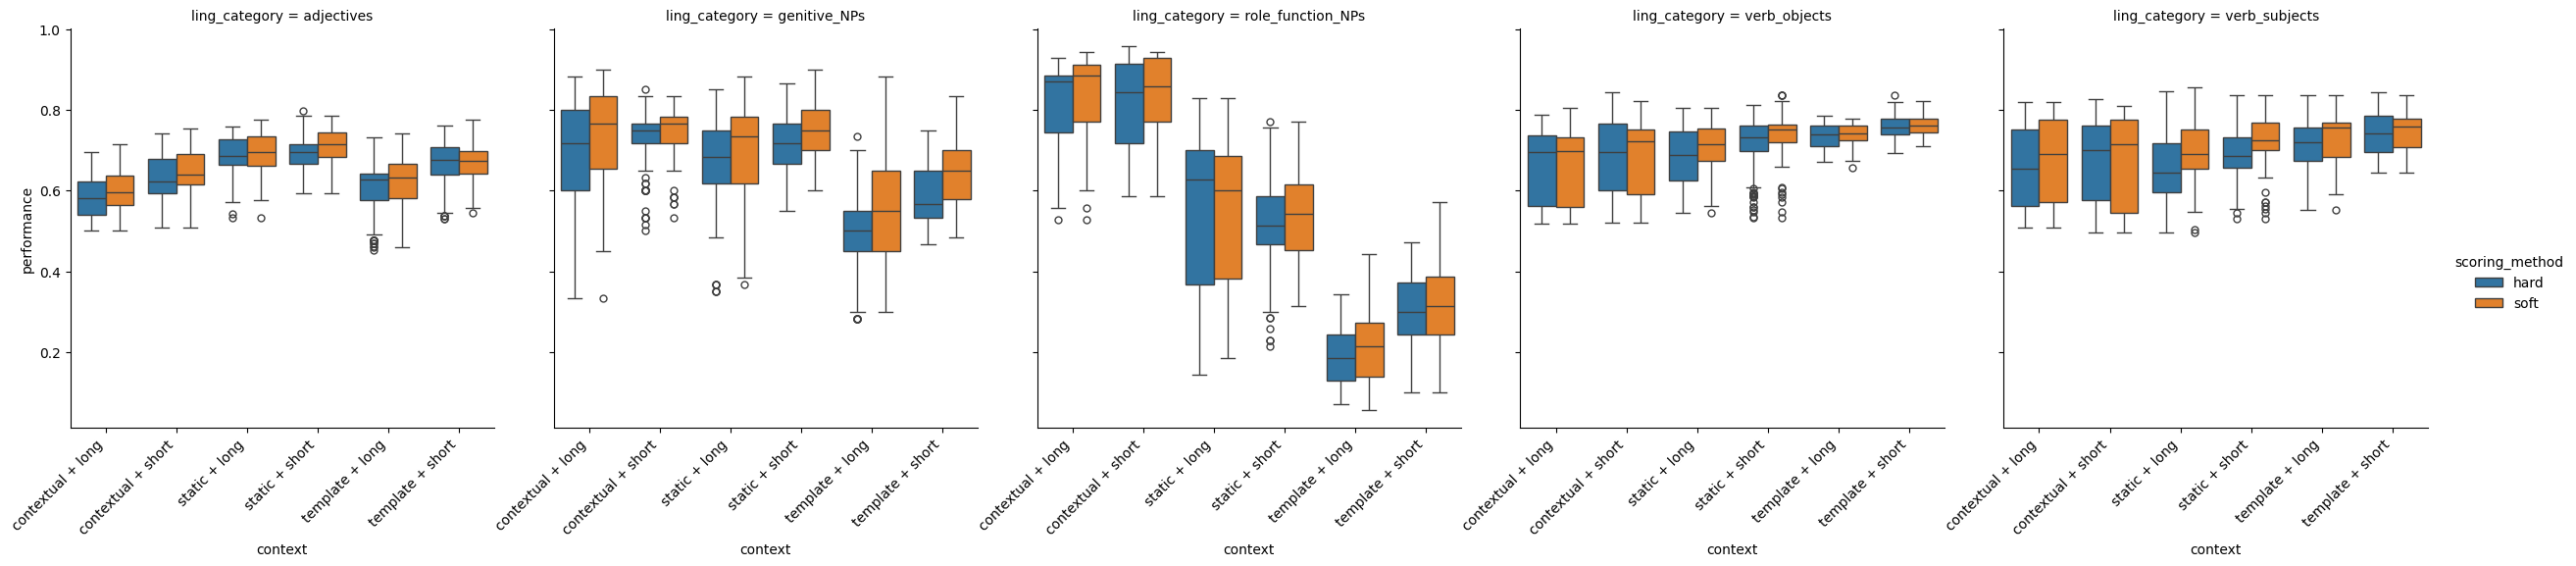

In [ ]:
g = sns.catplot(scores_per_experiment, x="context", y="performance", hue="scoring_method", col="ling_category", kind="box")
g.set_xticklabels(rotation=45, ha="right")

In [ ]:
labels_long.groupby("scoring_method")["score"].agg(["mean", "min", "max", "std"])

,mean,min,max,std
scoring_method,,,,
hard,-0.371065,-27.630698,27.631020,12.569167
soft,-0.001957,-0.250996,0.348857,0.064249


In [ ]:
scores_per_experiment.groupby("scoring_method", observed=True)["performance"].agg(["mean", "min", "max", "std"])

,mean,min,max,std
scoring_method,,,,
hard,0.645445,0.071429,0.957143,0.158726
soft,0.661700,0.057143,0.942857,0.158345


In [ ]:
average_per_experiment.groupby("scoring_method", observed=True)["performance"].agg(["mean", "min", "max", "std"])

,mean,min,max,std
scoring_method,,,,
hard,0.645445,0.423195,0.775579,0.077289
soft,0.661700,0.431329,0.789773,0.078291


In [ ]:
param_cols = ["mlm", "emb", "topk", "cont_emb", "long_cont"]
wide = average_per_experiment.pivot(index=param_cols, columns="scoring_method", values="performance")
wide

scoring_method                                                       hard  \
mlm             emb                   topk cont_emb   long_cont             
ModernBERT-base all-MiniLM-L6-v2      1    0          0          0.692377   
                                                      1          0.688902   
                                           2          0          0.573409   
                                                      1          0.465401   
                                           contextual 0          0.699902   
...                                                                   ...   
roberta-base    modernbert-embed-base 150  0          1          0.497104   
                                           2          0          0.541270   
                                                      1          0.469869   
                                           contextual 0          0.666302   
                                                      1          0.579284   

scoring_method                                                       soft  
mlm             emb                   topk cont_emb   long_cont            
ModernBERT-base all-MiniLM-L6-v2      1    0          0          0.692377  
                                                      1          0.688902  
                                           2          0          0.573409  
                                                      1          0.465401  
                                           contextual 0          0.699902  
...                                                                   ...  
roberta-base    modernbert-embed-base 150  0          1          0.528028  
                                           2          0          0.563403  
                                                      1          0.477774  
                                           contextual 0          0.673569  
                                                      1          0.619001  

[540 rows x 2 columns]

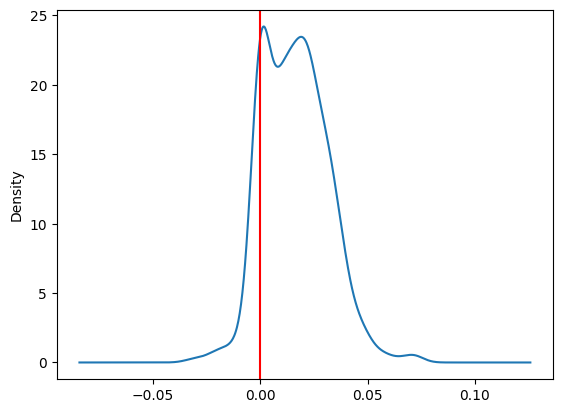

In [ ]:
scoring_method_diff =  (wide.soft - wide.hard).rename("diff")
ax = scoring_method_diff.plot.density()
ax.axvline(0, color="red")
plt.show()

In [ ]:
# Test the null hypothesis that two related paired samples come from the same
# distribution; if the difference is symmetric about zero.
from scipy.stats import wilcoxon

stat, p = wilcoxon(scoring_method_diff)
print(f"stat={stat}, p={p}")

stat=2880.0, p=2.4308462048135084e-67


In [ ]:
wilcoxon(scoring_method_diff, alternative="greater")

WilcoxonResult(statistic=np.float64(98595.0), pvalue=np.float64(1.2154231024067542e-67))

In [ ]:
hard_scores = labels_long[labels_long["scoring_method"] == "hard"].reset_index(drop=True).rename(columns={"pred": "pred_hard", "correct": "correct_hard"})
soft_scores = labels_long[labels_long["scoring_method"] == "soft"].reset_index(drop=True).rename(columns={"pred": "pred_soft", "correct": "correct_soft"})
assert len(hard_scores) == len(soft_scores)

In [ ]:
# How often do the predictions by hard/soft method agree/disagree?
pd.crosstab(hard_scores.pred_hard, soft_scores.pred_soft, margins=True)

pred_soft,0,1,All
pred_hard,,,
0,164577,9229,173806
1,7835,142359,150194
All,172412,151588,324000


In [ ]:
# How often are the predictions by hard/soft method correct?
pd.crosstab(hard_scores.correct_hard, soft_scores.correct_soft, margins=True)

correct_soft,False,True,All
correct_hard,,,
False,147713,8288,156001
True,4668,163331,167999
All,152381,171619,324000


In [ ]:
# How often are the predictions by hard/soft method correct when the inconclusive predictions are dropped?
pd.crosstab(hard_scores[hard_scores["expectations"] != 2].correct_hard, soft_scores[soft_scores["expectations"] != 2].correct_soft, margins=True)

correct_soft,False,True,All
correct_hard,,,
False,76973,8288,85261
True,4668,163331,167999
All,81641,171619,253260


In [ ]:
# How often are the predictions by hard/soft method correct when the inconclusive predictions are dropped?
pd.crosstab(hard_scores[hard_scores["expectations"] != 2].correct_hard, soft_scores[soft_scores["expectations"] != 2].correct_soft, normalize=True)

correct_soft,False,True
correct_hard,,
False,0.303929,0.032725
True,0.018432,0.644914


In [ ]:
# McNemar's test
((8288-4668)**2) / (8288+4668)

1011.4541525162088

In [ ]:
((121-59)**2) / (121+59)

21.355555555555554

In [ ]:
from scipy.stats import binom, chi2

def mcnemar(b: int, c: int, continuity_correction: bool = False) -> float:
    check_valid = lambda n: isinstance(n, int) or (isinstance(n, float) and n.is_integer())
    if not all(map(check_valid, [b, c])):
        raise ValueError("b and c must be integers!")
    n_min, n_max = sorted([b, c])
    corr = int(continuity_correction)
    if (n_min + n_max) < 25:
        pvalue = 2 * binom.cdf(n_min, n_min+n_max, 0.5) - binom.pmf(n_min, n_min+n_max, 0.5)
    else:
        chi2_statistic = (abs(n_min - n_max) - corr) ** 2 / (n_min + n_max)
        pvalue = chi2.sf(chi2_statistic, 1)
    return pvalue

mcnemar(8288, 4668)

np.float64(5.815138628855127e-222)